# UE Data Mining - Projet

Rapport du projet de l'UE Data Mining — année universitaire 2026–2027.

Équipe : Flavien, Leticia, Sarah, Marie, Arthur et Cheikh.

Analyse Ecology : Flavien. Les jeux de données et les personnes du récit sont fictifs.


# Analyse des données Ecology

Nous cherchons à comprendre les observations écologiques et à identifier
les évolutions ou événements qui nécessitent une investigation.

L'analyse commence par la structure et la qualité des six fichiers.
Les rapprochements avec les autres domaines seront ensuite examinés
à partir des identifiants, des lieux et des dates disponibles.

**Organisation.** Nous suivons l'ordre des cours : préparation et exploration
des fichiers, puis comparaisons, anomalies, réseaux, évolutions temporelles
et analyse textuelle lorsque ces approches répondent à une question utile.

**Usage de l'IA générative.** Une assistance a été utilisée pour proposer
et expliquer du code, corriger les erreurs et aider à rédiger les commentaires.
Les résultats obtenus sont examinés progressivement et les limites explicitées.

## Cours 1 — Préparation et exploration des données

### 1. Sites de suivi — `monitoring_sites.csv`

Ce fichier décrit les sites de surveillance écologique.
Une ligne représente un site, identifié par `site_code`.

Nous vérifions les dimensions, les types de variables, les valeurs
manquantes et l'unicité des identifiants. Cette table servira de référence
pour mettre en contexte les relevés et les rapports.

In [1]:
import pandas as pd

# Conservation du tableau brut pour pouvoir vérifier les transformations.
df_sites_brut = pd.read_csv(
    "data/ecology/monitoring_sites.csv"
)

print("Dimensions :", df_sites_brut.shape)

print(
    "Lignes entièrement dupliquées :",
    df_sites_brut.duplicated().sum()
)

print(
    "Codes de site dupliqués :",
    df_sites_brut["site_code"].duplicated().sum()
)

bilan_sites = pd.DataFrame({
    "type_pandas": df_sites_brut.dtypes.astype(str),
    "valeurs_manquantes": df_sites_brut.isna().sum(),
    "valeurs_distinctes": df_sites_brut.nunique()
})

print("\nStructure des variables :")
display(bilan_sites)

print("\nAperçu des sites :")
display(df_sites_brut.head())

Dimensions : (64, 14)
Lignes entièrement dupliquées : 0
Codes de site dupliqués : 0

Structure des variables :


,type_pandas,valeurs_manquantes,valeurs_distinctes
site_code,str,0,64
site_name,str,0,64
site_category,str,0,4
region,str,0,3
jurisdiction,str,0,3
latitude,float64,0,64
longitude,float64,0,64
elevation_m,float64,1,57
habitat_category,str,0,8
cave_access_category,str,0,2



Aperçu des sites :


,site_code,site_name,site_category,region,jurisdiction,latitude,longitude,elevation_m,habitat_category,cave_access_category,orchard_context,programme_start_date,programme_end_date,site_status
0,KNT-KES,Kestrel Cavern Monitoring Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.68,112.31,248.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
1,KNT-LUM,Luma Karst Reserve Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.81,112.44,25.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
2,KNT-SEN,Senna Ridge Cave Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.59,112.50,45.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
3,AVL-MAR,Marula East Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.41,101.69,226.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaN,active
4,AVL-VEL,Velin Basin Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.55,101.84,24.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaN,active


### Première lecture de la qualité des données

Le fichier contient 64 sites et 14 variables. Aucun doublon de ligne
ni de `site_code` n'est détecté. Le code de site peut donc servir
de clé pour relier cette table aux autres fichiers Ecology.

Une altitude est manquante. Le site concerné est conservé : cette
absence n'empêche pas d'utiliser ses autres informations.

La date de fin du programme est absente pour les 64 sites.
Nous conservons cette absence sans inventer de date. La colonne
`site_status` possède une seule modalité et ne permettra donc pas,
à elle seule, de distinguer les sites.

Les dates sont encore stockées comme du texte et devront être
converties. Avant de nettoyer les catégories, nous examinons leurs
modalités pour repérer d'éventuelles variantes d'écriture.

In [2]:
colonnes_categories_sites = [
    "site_category",
    "habitat_category",
    "cave_access_category",
    "orchard_context"
]

for colonne in colonnes_categories_sites:
    print(f"\nRépartition de {colonne} :")

    display(
        df_sites_brut[colonne]
        .value_counts(dropna=False)
        .rename_axis(colonne)
        .to_frame("nombre_sites")
    )


Répartition de site_category :


,nombre_sites
site_category,
habitat monitoring,40
orchard monitoring,15
cave monitoring,8
ORCHARD MONITORING,1



Répartition de habitat_category :


,nombre_sites
habitat_category,
mixed_forest,19
durian_orchard,10
coastal_habitat,10
karst_habitat,9
research_site,6
mixed_agriculture,5
protected_forest,3
degraded_land,2



Répartition de cave_access_category :


,nombre_sites
cave_access_category,
not applicable,56
managed,8



Répartition de orchard_context :


,nombre_sites
orchard_context,
none recorded,48
commercial or research orchard,16


### Harmonisation des catégories

Une variante d'écriture est présente dans `site_category` :
`ORCHARD MONITORING` correspond à `orchard monitoring`.
Nous harmonisons la casse et les espaces des quatre variables examinées.

Les modalités `not applicable` et `none recorded` sont conservées :
elles portent une information différente d'une valeur manquante.
En particulier, `none recorded` indique qu'aucun contexte de verger
n'est renseigné, sans démontrer son absence sur le terrain.

Les identifiants des sites sont conservés à l'identique pour préserver
les liens entre fichiers.

In [3]:
# Copie de travail : les données brutes restent disponibles.
df_sites = df_sites_brut.copy()

for colonne in colonnes_categories_sites:
    df_sites[colonne] = (
        df_sites[colonne]
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.lower()
    )

print("Catégories de sites après harmonisation :")

display(
    df_sites["site_category"]
    .value_counts(dropna=False)
    .rename_axis("site_category")
    .to_frame("nombre_sites")
)

print("Nombre de sites conservés :", len(df_sites))
print(
    "Codes de site inchangés :",
    df_sites["site_code"].equals(df_sites_brut["site_code"])
)

Catégories de sites après harmonisation :


,nombre_sites
site_category,
habitat monitoring,40
orchard monitoring,16
cave monitoring,8


Nombre de sites conservés : 64
Codes de site inchangés : True


### Conversion et contrôle des dates

Les dates de début et de fin des programmes ont été converties
en variables temporelles sans erreur.

Les programmes commencent en 2016 pour 27 sites, en 2017 pour
16 sites et en 2018 pour 21 sites.

Les dates de fin sont absentes pour les 64 sites et restent
manquantes (`NaT`). Aucun remplacement n'est effectué, car les
sources ne permettent pas d'attribuer une date de fin fiable.

Aucune date de fin antérieure au début n'est détectée. Toutefois,
en l'absence de dates de fin renseignées, ce contrôle ne permet
pas de valider leur cohérence chronologique ni de calculer les
durées complètes des programmes.

In [4]:
colonnes_dates_sites = [
    "programme_start_date",
    "programme_end_date"
]

for colonne in colonnes_dates_sites:
    df_sites[colonne] = pd.to_datetime(
        df_sites[colonne],
        format="mixed",
        errors="raise"
    )

print("Types après conversion :")
display(
    df_sites[colonnes_dates_sites]
    .dtypes.astype(str)
    .to_frame("type_pandas")
)

print("Répartition des dates de début :")
display(
    df_sites["programme_start_date"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("nombre_sites")
)

print(
    "Nombre de dates de fin renseignées :",
    df_sites["programme_end_date"].notna().sum()
)

dates_incoherentes_sites = (
    df_sites["programme_end_date"].notna()
    & (
        df_sites["programme_end_date"]
        < df_sites["programme_start_date"]
    )
)

print(
    "Dates de fin antérieures au début :",
    dates_incoherentes_sites.sum()
)

Types après conversion :

,type_pandas
programme_start_date,datetime64[us]
programme_end_date,datetime64[s]


Répartition des dates de début :


,nombre_sites
programme_start_date,
2016-01-01,27
2017-01-01,16
2018-01-01,21


Nombre de dates de fin renseignées : 0
Dates de fin antérieures au début : 0


### Vérification des coordonnées et de l'altitude

Nous contrôlons que les latitudes sont comprises entre -90 et 90 degrés,
et les longitudes entre -180 et 180 degrés.

Ces bornes permettent de détecter des coordonnées impossibles,
mais ne suffisent pas à confirmer la localisation exacte des sites.

Nous examinons également les valeurs extrêmes des trois variables
géographiques et identifions le site dont l'altitude est manquante.
Cette absence est conservée.

In [5]:
latitude_invalide = (
    df_sites["latitude"].notna()
    & ~df_sites["latitude"].between(-90, 90)
)

longitude_invalide = (
    df_sites["longitude"].notna()
    & ~df_sites["longitude"].between(-180, 180)
)

print("Latitudes hors des bornes :", latitude_invalide.sum())
print("Longitudes hors des bornes :", longitude_invalide.sum())

print("\nValeurs minimales et maximales :")
display(
    df_sites[
        ["latitude", "longitude", "elevation_m"]
    ]
    .agg(["min", "max"])
    .T
)

print("\nSites présentant des coordonnées hors des bornes :")
display(
    df_sites.loc[
        latitude_invalide | longitude_invalide,
        ["site_code", "site_name", "latitude", "longitude"]
    ]
)

print("\nSite dont l'altitude est manquante :")
display(
    df_sites.loc[
        df_sites["elevation_m"].isna(),
        ["site_code", "site_name", "region", "habitat_category"]
    ]
)

Latitudes hors des bornes : 0
Longitudes hors des bornes : 0

Valeurs minimales et maximales :


,min,max
latitude,1.7668,7.7568
longitude,101.3263,112.6905
elevation_m,5.0000,418.8000



Sites présentant des coordonnées hors des bornes :


,site_code,site_name,latitude,longitude



Site dont l'altitude est manquante :


,site_code,site_name,region,habitat_category
8,KNT-CYP,Dune Reach Monitoring Site,Kintara Karst Cluster,karst_habitat


### Résultat du contrôle géographique

Aucune latitude ni longitude ne dépasse les bornes géographiques
possibles. Ce contrôle ne confirme toutefois pas l'exactitude des
localisations.

Les altitudes renseignées s'étendent de 5 à 418,8 mètres.
L'altitude du site KNT-CYP, situé dans la région Kintara Karst Cluster,
est manquante. Ce site est conservé pour les autres analyses.

### Répartition des sites par région et habitat

Nous croisons la catégorie de suivi avec la région, puis avec
le type d'habitat.

La catégorie du site décrit son activité de surveillance, tandis que
l'habitat décrit son environnement. Ces deux informations ne sont
donc pas nécessairement équivalentes.

Ces répartitions serviront à contextualiser les comparaisons entre
sites et à identifier les groupes pour lesquels les effectifs sont faibles.

In [6]:
print("Catégories de suivi par région :")

repartition_sites_region = pd.crosstab(
    df_sites["region"],
    df_sites["site_category"],
    margins=True,
    margins_name="Total"
)

display(repartition_sites_region)

print("\nHabitats selon la catégorie de suivi :")

repartition_sites_habitat = pd.crosstab(
    df_sites["site_category"],
    df_sites["habitat_category"]
)

display(repartition_sites_habitat)

Catégories de suivi par région :


site_category,cave monitoring,habitat monitoring,orchard monitoring,Total
region,,,,
Eastern Avelora Agricultural Cluster,0,9,13,22
Kintara Karst Cluster,7,15,0,22
Tembara Coastal Cluster,1,16,3,20
Total,8,40,16,64



Habitats selon la catégorie de suivi :


habitat_category,coastal_habitat,degraded_land,durian_orchard,karst_habitat,mixed_agriculture,mixed_forest,protected_forest,research_site
site_category,,,,,,,,
cave monitoring,1,0,0,7,0,0,0,0
habitat monitoring,9,2,0,2,0,19,3,5
orchard monitoring,0,0,10,0,5,0,0,1


### Répartition des sites et précautions pour la suite

Les 64 sites se répartissent entre trois régions, avec des effectifs
proches : 22 sites en Avelora, 22 à Kintara et 20 à Tembara.

En revanche, les catégories de suivi sont réparties différemment :
- 13 des 16 sites de suivi des vergers se trouvent en Avelora ;
- 7 des 8 sites de suivi des grottes se trouvent à Kintara ;
- Tembara compte principalement des sites de suivi des habitats.

Une différence observée entre régions pourrait donc aussi être liée
aux habitats et aux catégories de suivi. Les comparaisons suivantes
devront tenir compte de cette répartition.

La catégorie de suivi et le type d’habitat décrivent deux aspects
différents. Par exemple, un site de suivi des habitats peut se trouver
en milieu karstique : cette combinaison ne constitue pas, à elle seule,
une erreur.

### 2. Relevés de chauves-souris — `bat_surveys.csv`

Nous examinons la structure des relevés, les valeurs manquantes
et les doublons avant d’étudier les effectifs observés.

Les comptages devront ensuite être interprétés en tenant compte
de l’effort d’observation et des conditions de collecte.

In [7]:
df_bats_brut = pd.read_csv("data/ecology/bat_surveys.csv")

print("Dimensions :", df_bats_brut.shape)

print(
    "Lignes entièrement dupliquées :",
    df_bats_brut.duplicated().sum()
)

print(
    "Identifiants de relevé dupliqués :",
    df_bats_brut["survey_id"].duplicated().sum()
)

print(
    "Nombre de sites représentés :",
    df_bats_brut["site_code"].nunique()
)

structure_bats = pd.DataFrame({
    "type_pandas": df_bats_brut.dtypes.astype(str),
    "valeurs_manquantes": df_bats_brut.isna().sum(),
    "valeurs_distinctes": df_bats_brut.nunique()
})

print("\nStructure des variables :")
display(structure_bats)

print("\nAperçu des relevés :")
display(df_bats_brut.head())

Dimensions : (4994, 14)
Lignes entièrement dupliquées : 2
Identifiants de relevé dupliqués : 2
Nombre de sites représentés : 64

Structure des variables :


,type_pandas,valeurs_manquantes,valeurs_distinctes
survey_id,str,0,4992
site_code,str,0,64
survey_start,str,0,78
survey_end,str,0,88
survey_method,str,0,8
observation_hours,str,0,348
observed_bat_count,str,0,77
acoustic_detection_count,str,0,105
nightly_visit_count,str,0,55
colony_estimate,float64,0,475



Aperçu des relevés :


,survey_id,site_code,survey_start,survey_end,survey_method,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,colony_estimate,comparison_species_count,observer_team,survey_quality,weather_interference
0,BAT-0000001,KNT-KES,2019-01-05T18:00:00,2019-01-12T00:00:00,fixed_acoustic_station,28.6,7,13,7,3.8,8,TEAM-11-2,high,32.0
1,BAT-0000002,KNT-KES,2019-02-05T18:00:00,2019-02-12T00:00:00,acoustic_and_visual,31.7,8,12,9,7.3,18,TEAM-11-2,acceptable,18.5
2,BAT-0000003,KNT-KES,2019-03-05T18:00:00,2019-03-12T00:00:00,fixed_acoustic_station,32.4,22,28,14,19.9,8,TEAM-11-2,high,26.2
3,BAT-0000004,KNT-KES,2019-04-05T18:00:00,2019-04-12T00:00:00,acoustic_and_visual,35.7,26,36,19,32.2,14,TEAM-11-2,high,35.0
4,BAT-0000005,KNT-KES,2019-05-05T18:00:00,2019-05-12T00:00:00,acoustic_transect,32.0,23,29,22,20.9,16,TEAM-11-2,acceptable,38.7


### Contrôle et suppression des doublons exacts

Le fichier contient 4 994 lignes, dont deux répétitions strictement
identiques. Nous conservons une seule occurrence de chaque ligne
afin de ne pas compter deux fois les mêmes relevés.

Nous vérifions ensuite si certains identifiants de relevé apparaissent
encore plusieurs fois. Des lignes différentes portant le même identifiant
nécessiteraient un examen séparé.

Les autres problèmes de qualité seront traités dans les étapes suivantes.

In [8]:
# Afficher toutes les occurrences des lignes répétées
print("Occurrences des doublons exacts :")

display(
    df_bats_brut.loc[
        df_bats_brut.duplicated(keep=False)
    ].sort_values("survey_id")
)

# Travailler sur une copie sans modifier les données brutes
df_bats = (
    df_bats_brut
    .drop_duplicates()
    .reset_index(drop=True)
    .copy()
)

print("Nombre de lignes avant :", len(df_bats_brut))
print("Nombre de lignes après :", len(df_bats))
print("Nombre de lignes supprimées :", len(df_bats_brut) - len(df_bats))

# Vérifier qu'aucun identifiant répété ne subsiste
identifiants_repetes = df_bats["survey_id"].duplicated(keep=False)

print(
    "Identifiants de relevé encore dupliqués :",
    df_bats["survey_id"].duplicated().sum()
)

if identifiants_repetes.any():
    display(
        df_bats.loc[identifiants_repetes]
        .sort_values("survey_id")
    )

Occurrences des doublons exacts :


,survey_id,site_code,survey_start,survey_end,survey_method,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,colony_estimate,comparison_species_count,observer_team,survey_quality,weather_interference
3182,BAT-0003183,AVL-ABG,2024-03-05T18:00:00,2024-03-12T00:00:00,acoustic_and_visual,38.7,8,18,12,8.6,7,TEAM-12-4,high,7.3
4992,BAT-0003183,AVL-ABG,2024-03-05T18:00:00,2024-03-12T00:00:00,acoustic_and_visual,38.7,8,18,12,8.6,7,TEAM-12-4,high,7.3
3566,BAT-0003567,AVL-FNQ,2023-09-05T18:00:00,2023-09-12T00:00:00,acoustic_transect,28.9,13,4,5,14.8,8,TEAM-12-4,high,55.9
4993,BAT-0003567,AVL-FNQ,2023-09-05T18:00:00,2023-09-12T00:00:00,acoustic_transect,28.9,13,4,5,14.8,8,TEAM-12-4,high,55.9


Nombre de lignes avant : 4994
Nombre de lignes après : 4992
Nombre de lignes supprimées : 2
Identifiants de relevé encore dupliqués : 0


### Vérification du format des variables numériques

Plusieurs mesures et comptages sont stockés sous forme de texte.
Avant leur conversion, nous recherchons les valeurs qui ne sont pas
directement interprétables comme des nombres.

Cette vérification permet de choisir un nettoyage adapté, sans transformer
silencieusement les valeurs problématiques en données manquantes.

In [9]:
variables_numeriques_texte_bats = [
    "observation_hours",
    "observed_bat_count",
    "acoustic_detection_count",
    "nightly_visit_count",
    "weather_interference"
]

for colonne in variables_numeriques_texte_bats:
    valeurs = df_bats[colonne].astype("string").str.strip()

    # Conversion de diagnostic uniquement :
    # les données de df_bats ne sont pas modifiées.
    conversion_test = pd.to_numeric(valeurs, errors="coerce")

    valeurs_non_convertibles = (
        valeurs.notna() & conversion_test.isna()
    )

    print(f"\nVariable : {colonne}")
    print(
        "Nombre de valeurs non directement convertibles :",
        valeurs_non_convertibles.sum()
    )

    if valeurs_non_convertibles.any():
        display(
            valeurs.loc[valeurs_non_convertibles]
            .value_counts()
            .rename_axis("valeur_originale")
            .to_frame("nombre_occurrences")
        )


Variable : observation_hours
Nombre de valeurs non directement convertibles : 30


,nombre_occurrences
valeur_originale,
"24,3",1
"37,2",1
"30,6",1
"35,0",1
"34,3",1
"31,6",1
"31,2",1
"32,5",1
"23,5",1



Variable : observed_bat_count
Nombre de valeurs non directement convertibles : 25


,nombre_occurrences
valeur_originale,
9 count,4
11 count,2
16 count,2
5 count,2
10 count,2
4 count,2
19 count,2
6 count,2
18 count,1



Variable : acoustic_detection_count
Nombre de valeurs non directement convertibles : 25


,nombre_occurrences
valeur_originale,
18 count,2
14 count,2
12 count,2
7 count,1
52 count,1
47 count,1
13 count,1
23 count,1
37 count,1



Variable : nightly_visit_count
Nombre de valeurs non directement convertibles : 10


,nombre_occurrences
valeur_originale,
8 count,3
7 count,1
1 count,1
5 count,1
14 count,1
9 count,1
16 count,1
4 count,1



Variable : weather_interference
Nombre de valeurs non directement convertibles : 8


,nombre_occurrences
valeur_originale,
"15,0",1
"42,4",1
"7,7",1
"34,1",1
"33,9",1
"58,2",1
"6,4",1
"52,7",1


### Harmonisation et conversion des mesures numériques

Nous remplaçons les virgules décimales par des points dans
`observation_hours` et `weather_interference`.

Pour les trois variables de comptage concernées, nous retirons uniquement
le suffixe `count`, puis nous convertissons les valeurs en nombres.

La conversion signale une erreur si une valeur reste non interprétable.
Aucun relevé n’est supprimé et aucune valeur manquante n’est imputée.
`colony_estimate`, déjà numérique, conserve ses décimales puisqu’il
s’agit d’une estimation.

In [10]:
# Mesures comportant parfois une virgule décimale
for colonne in [
    "observation_hours",
    "weather_interference"
]:
    valeurs_nettoyees = (
        df_bats[colonne]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    df_bats[colonne] = pd.to_numeric(
        valeurs_nettoyees,
        errors="raise"
    )

# Comptages comportant parfois le suffixe "count"
for colonne in [
    "observed_bat_count",
    "acoustic_detection_count",
    "nightly_visit_count"
]:
    valeurs_nettoyees = (
        df_bats[colonne]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+count$", "", regex=True)
    )

    df_bats[colonne] = pd.to_numeric(
        valeurs_nettoyees,
        errors="raise"
    )

print("Types et valeurs manquantes après conversion :")

display(
    pd.DataFrame({
        "type_pandas": (
            df_bats[variables_numeriques_texte_bats]
            .dtypes.astype(str)
        ),
        "valeurs_manquantes": (
            df_bats[variables_numeriques_texte_bats]
            .isna().sum()
        )
    })
)

print("Nombre de relevés conservés :", len(df_bats))

Types et valeurs manquantes après conversion :


,type_pandas,valeurs_manquantes
observation_hours,Float64,0
observed_bat_count,Int64,0
acoustic_detection_count,Int64,0
nightly_visit_count,Int64,0
weather_interference,Float64,0


Nombre de relevés conservés : 4992


### Contrôle de cohérence des valeurs numériques

Nous examinons les distributions des mesures et recherchons les durées
d’observation nulles ou négatives ainsi que les comptages négatifs.

Les comptages nuls sont conservés : ils peuvent correspondre à une absence
de détection pendant le relevé. Les valeurs élevées ne sont pas supprimées
sans examen du contexte.

In [11]:
variables_comptage_bats = [
    "observed_bat_count",
    "acoustic_detection_count",
    "nightly_visit_count",
    "comparison_species_count"
]

variables_mesure_bats = [
    "observation_hours",
    *variables_comptage_bats,
    "colony_estimate",
    "weather_interference"
]

print("Statistiques descriptives :")
display(
    df_bats[variables_mesure_bats]
    .describe()
    .T
    .round(2)
)

print("Nombre de comptages négatifs par variable :")
display(
    df_bats[variables_comptage_bats]
    .lt(0)
    .sum()
    .to_frame("nombre_valeurs_negatives")
)

duree_non_positive = df_bats["observation_hours"].le(0)
comptage_negatif = (
    df_bats[variables_comptage_bats]
    .lt(0)
    .any(axis=1)
)
estimation_negative = df_bats["colony_estimate"].lt(0)

print(
    "Durées d’observation nulles ou négatives :",
    duree_non_positive.sum()
)
print(
    "Estimations de colonie négatives :",
    estimation_negative.sum()
)

lignes_a_verifier = (
    duree_non_positive
    | comptage_negatif
    | estimation_negative
)

print("Relevés présentant ces incohérences :")
display(
    df_bats.loc[
        lignes_a_verifier,
        ["survey_id", "site_code"] + variables_mesure_bats
    ]
)

Statistiques descriptives :


,count,mean,std,min,25%,50%,75%,max
observation_hours,4992.0,30.327524,5.504168,5.0,26.9,30.6,34.1,46.9
observed_bat_count,4992.0,14.127604,8.248394,0.0,8.0,13.0,18.0,73.0
acoustic_detection_count,4992.0,20.48097,12.128314,0.0,12.0,18.0,26.0,107.0
nightly_visit_count,4992.0,10.107973,6.062931,0.0,6.0,9.0,13.0,54.0
comparison_species_count,4992.0,10.713141,3.449589,1.0,8.0,11.0,13.0,26.0
colony_estimate,4992.0,15.828165,9.60497,0.0,9.3,14.2,20.5,99.6
weather_interference,4992.0,37.486058,16.657117,0.0,25.1,36.7,49.0,100.0


Nombre de comptages négatifs par variable :


,nombre_valeurs_negatives
observed_bat_count,0
acoustic_detection_count,0
nightly_visit_count,0
comparison_species_count,0


Durées d’observation nulles ou négatives : 0
Estimations de colonie négatives : 0
Relevés présentant ces incohérences :


,survey_id,site_code,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,comparison_species_count,colony_estimate,weather_interference


### Bilan du contrôle numérique

Les durées d’observation sont toutes strictement positives.
Aucun comptage ni aucune estimation de colonie n’est négatif.

Les durées varient de 5 à 46,9 heures. Une différence de comptage
peut donc refléter une différence d’effort d’observation, et pas
uniquement une différence de présence des chauves-souris.

Les valeurs nulles et les valeurs élevées sont conservées à ce stade.
Ces contrôles ne suffisent pas à confirmer l’exactitude de toutes
les mesures ; leur interprétation nécessitera les informations
sur la méthode, la qualité du relevé et les conditions de collecte.

### Vérification des méthodes et de la qualité des relevés

Nous examinons les modalités des méthodes de suivi, de la qualité
des relevés et des équipes d’observation avant toute harmonisation.

Les équipes non renseignées restent manquantes : nous ne pouvons
pas attribuer une équipe à un relevé sans information supplémentaire.

In [12]:
for colonne in [
    "survey_method",
    "survey_quality",
    "observer_team"
]:
    print(f"\nRépartition de {colonne} :")

    display(
        df_bats[colonne]
        .value_counts(dropna=False)
        .rename_axis(colonne)
        .to_frame("nombre_releves")
    )


Répartition de survey_method :


,nombre_releves
survey_method,
acoustic_and_visual,1742
acoustic_transect,1616
fixed_acoustic_station,1614
FIXED_ACOUSTIC_STATION,9
ACOUSTIC_AND_VISUAL,4
ACOUSTIC_TRANSECT,4
Fixed_Acoustic_Station,2
Acoustic_Transect,1



Répartition de survey_quality :


,nombre_releves
survey_quality,
high,2688
acceptable,2166
limited,138



Répartition de observer_team :


,nombre_releves
observer_team,
TEAM-11-3,390
TEAM-11-4,390
TEAM-12-1,389
TEAM-11-2,388
TEAM-12-2,388
TEAM-12-5,312
TEAM-12-4,312
TEAM-13-3,311
TEAM-11-5,311


### Harmonisation des méthodes de suivi

Les huit modalités de `survey_method` correspondent à trois méthodes
présentant des différences de casse. Nous harmonisons leur écriture
en minuscules et supprimons les espaces éventuels en début et fin.

Les catégories de qualité sont conservées. Les relevés de qualité
limitée ne sont pas exclus à ce stade.

Les 20 valeurs manquantes de `observer_team` restent manquantes :
aucune équipe ne peut leur être attribuée avec certitude.
Les identifiants des équipes renseignées sont conservés.

In [13]:
# Harmoniser uniquement l'écriture des méthodes
df_bats["survey_method"] = (
    df_bats["survey_method"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("Méthodes après harmonisation :")

display(
    df_bats["survey_method"]
    .value_counts()
    .rename_axis("survey_method")
    .to_frame("nombre_releves")
)

print(
    "Nombre de méthodes distinctes :",
    df_bats["survey_method"].nunique()
)

print(
    "Équipes non renseignées :",
    df_bats["observer_team"].isna().sum()
)

print("Nombre de relevés conservés :", len(df_bats))

Méthodes après harmonisation :


,nombre_releves
survey_method,
acoustic_and_visual,1746
fixed_acoustic_station,1625
acoustic_transect,1621


Nombre de méthodes distinctes : 3
Équipes non renseignées : 20
Nombre de relevés conservés : 4992


### Harmonisation des formats de dates

Les dates de fin utilisent quatre formats :
- année-mois-jour : `2021-07-12T00:00:00` ;
- année/mois/jour : `2021/07/12 00:00:00` ;
- jour/mois/année : `12/07/2021 00:00:00` ;
- jour-mois abrégé-année : `12-Apr-2019 00:00:00`.

Une première conversion automatique avait interprété certaines dates ambiguës
dans l’ordre mois/jour/année, produisant des fenêtres de relevé
anormalement longues.

Nous reprenons les chaînes originales et appliquons explicitement
le format correspondant à chaque écriture. Pour les dates ambiguës,
l’interprétation jour/mois/année est retenue car elle est cohérente
avec les dates de début et les fenêtres habituelles des autres relevés.

Après correction, les 4 992 relevés présentent tous une fenêtre
de 6,25 jours. Aucune ligne n’est supprimée et aucune date manquante
n’est imputée.

In [14]:
# Dates de début : format ISO observé dans le fichier
dates_debut_converties = pd.to_datetime(
    df_bats["survey_start"],
    format="%Y-%m-%dT%H:%M:%S",
    errors="raise"
)

# Repartir des dates de fin originales
dates_fin_brutes = (
    df_bats["survey_id"]
    .map(
        df_bats_brut
        .drop_duplicates()
        .set_index("survey_id")["survey_end"]
    )
    .astype("string")
    .str.strip()
)

# Les quatre formats réellement présents dans le fichier
formats_dates_fin = [
    (r"^\d{4}-", "%Y-%m-%dT%H:%M:%S"),
    (r"^\d{4}/", "%Y/%m/%d %H:%M:%S"),
    (r"^\d{2}/", "%d/%m/%Y %H:%M:%S"),
    (r"^\d{2}-[A-Za-z]{3}-", "%d-%b-%Y %H:%M:%S")
]

# Préparer les conversions sans modifier immédiatement df_bats
dates_fin_corrigees = pd.Series(
    pd.NaT,
    index=df_bats.index,
    dtype="datetime64[us]"
)

formats_reconnus = pd.Series(False, index=df_bats.index)

for motif, format_date in formats_dates_fin:
    masque = dates_fin_brutes.str.match(motif, na=False)

    dates_fin_corrigees.loc[masque] = pd.to_datetime(
        dates_fin_brutes.loc[masque],
        format=format_date,
        errors="raise"
    )

    formats_reconnus = formats_reconnus | masque

# Ne rien affecter si un format reste non reconnu
if not formats_reconnus.all():
    display(dates_fin_brutes.loc[~formats_reconnus])
    raise ValueError("Certaines dates ont un format non reconnu.")

# Comparaison de diagnostic : l'inférence automatique interprète 4 dates autrement.
dates_fin_interpretation_auto = pd.to_datetime(
    dates_fin_brutes, format="mixed", errors="raise"
)
nombre_dates_modifiees = (
    dates_fin_corrigees.ne(dates_fin_interpretation_auto).sum()
)

df_bats["survey_start"] = dates_debut_converties

df_bats["survey_end"] = dates_fin_corrigees

print("Dates interprétées différemment :", nombre_dates_modifiees)
print("Dates de fin manquantes :", df_bats["survey_end"].isna().sum())
print("Date de fin maximale :", df_bats["survey_end"].max())

fenetres_jours_corrigees = (
    (df_bats["survey_end"] - df_bats["survey_start"])
    .dt.total_seconds()
    / (24 * 3600)
)

print("\nFenêtres de relevé après correction, en jours :")
display(
    fenetres_jours_corrigees
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("fenetre_jours")
    .to_frame("nombre_releves")
)

print(
    "Fins de relevé antérieures ou égales au début :",
    df_bats["survey_end"].le(df_bats["survey_start"]).sum()
)


Dates interprétées différemment :

 4
Dates de fin manquantes : 0
Date de fin maximale : 2025-06-12 00:00:00

Fenêtres de relevé après correction, en jours :


,nombre_releves
fenetre_jours,
6.25,4992


Fins de relevé antérieures ou égales au début : 0


### Régularité du suivi mensuel par site

Nous vérifions la répartition des relevés entre les sites et les mois,
sur la période couverte par les dates de début.

Le total de 4 992 relevés pourrait correspondre à 64 sites suivis pendant
78 mois. Ce total ne suffit toutefois pas à garantir un suivi complet :
des mois manquants pourraient être compensés par plusieurs relevés
dans d’autres mois.

Nous contrôlons donc chaque combinaison site-mois, sans supprimer
automatiquement les éventuels relevés multiples.

In [15]:
# Utiliser le mois de début pour situer chaque relevé
df_bats["mois_releve"] = (
    df_bats["survey_start"].dt.to_period("M")
)

mois_attendus = pd.period_range(
    start=df_bats["mois_releve"].min(),
    end=df_bats["mois_releve"].max(),
    freq="M"
)

# Nombre de relevés pour chaque combinaison site-mois
suivi_mensuel_bats = (
    pd.crosstab(
        df_bats["site_code"],
        df_bats["mois_releve"]
    )
    .reindex(columns=mois_attendus, fill_value=0)
)

resume_suivi_bats = pd.DataFrame({
    "nombre_releves": suivi_mensuel_bats.sum(axis=1),
    "nombre_mois_observes": suivi_mensuel_bats.gt(0).sum(axis=1),
    "nombre_mois_absents": suivi_mensuel_bats.eq(0).sum(axis=1),
    "nombre_mois_avec_plusieurs_releves": (
        suivi_mensuel_bats.gt(1).sum(axis=1)
    )
})

print("Premier mois :", mois_attendus.min())
print("Dernier mois :", mois_attendus.max())
print("Nombre de mois dans la période :", len(mois_attendus))
print("Nombre de sites représentés :", len(resume_suivi_bats))

print("\nAperçu du suivi par site :")
display(resume_suivi_bats.head())

sites_a_verifier = (
    resume_suivi_bats["nombre_mois_absents"].gt(0)
    | resume_suivi_bats[
        "nombre_mois_avec_plusieurs_releves"
    ].gt(0)
)

print(
    "Sites avec des mois absents ou plusieurs relevés par mois :",
    sites_a_verifier.sum()
)

display(resume_suivi_bats.loc[sites_a_verifier])

Premier mois : 2019-01
Dernier mois : 2025-06
Nombre de mois dans la période : 78
Nombre de sites représentés : 64

Aperçu du suivi par site :


,nombre_releves,nombre_mois_observes,nombre_mois_absents,nombre_mois_avec_plusieurs_releves
site_code,,,,
AVL-ABG,78,78,0,0
AVL-ARU,78,78,0,0
AVL-BVM,78,78,0,0
AVL-BWK,78,78,0,0
AVL-DER,78,78,0,0


Sites avec des mois absents ou plusieurs relevés par mois : 0


,nombre_releves,nombre_mois_observes,nombre_mois_absents,nombre_mois_avec_plusieurs_releves
site_code,,,,


### Bilan de la couverture temporelle

Les 64 sites possèdent chacun 78 relevés, soit un relevé par mois
de janvier 2019 à juin 2025. Aucun mois absent ni relevé multiple
pour une même combinaison site-mois n’a été détecté.

Cette couverture facilite les comparaisons temporelles. Elle ne garantit
cependant pas des conditions de collecte identiques : les durées,
les méthodes et la qualité des observations restent à prendre en compte.

### Rattachement des relevés aux caractéristiques des sites

Nous utilisons `site_code` pour associer chaque relevé à son site,
sa région, sa catégorie de suivi et son habitat.

La jointure doit conserver tous les relevés sans multiplier les lignes.
Nous vérifions également que chaque code de site possède une correspondance.

In [16]:
colonnes_sites_pour_bats = [
    "site_code",
    "site_name",
    "region",
    "site_category",
    "habitat_category"
]

df_bats_enrichi = df_bats.merge(
    df_sites[colonnes_sites_pour_bats],
    on="site_code",
    how="left",
    validate="many_to_one",
    indicator="_correspondance_site"
)

sans_correspondance = (
    df_bats_enrichi["_correspondance_site"] == "left_only"
)

print("Nombre de relevés avant jointure :", len(df_bats))
print("Nombre de relevés après jointure :", len(df_bats_enrichi))
print(
    "Relevés sans correspondance dans les sites :",
    sans_correspondance.sum()
)

if sans_correspondance.any():
    display(
        df_bats_enrichi.loc[
            sans_correspondance,
            ["survey_id", "site_code"]
        ]
    )
else:
    print("Tous les relevés sont rattachés à un site.")

df_bats_enrichi = df_bats_enrichi.drop(
    columns="_correspondance_site"
)

display(
    df_bats_enrichi[
        [
            "survey_id",
            "site_code",
            "region",
            "site_category",
            "habitat_category",
            "mois_releve"
        ]
    ].head()
)

Nombre de relevés avant jointure : 4992
Nombre de relevés après jointure : 4992
Relevés sans correspondance dans les sites : 0
Tous les relevés sont rattachés à un site.


,survey_id,site_code,region,site_category,habitat_category,mois_releve
0,BAT-0000001,KNT-KES,Kintara Karst Cluster,cave monitoring,karst_habitat,2019-01
1,BAT-0000002,KNT-KES,Kintara Karst Cluster,cave monitoring,karst_habitat,2019-02
2,BAT-0000003,KNT-KES,Kintara Karst Cluster,cave monitoring,karst_habitat,2019-03
3,BAT-0000004,KNT-KES,Kintara Karst Cluster,cave monitoring,karst_habitat,2019-04
4,BAT-0000005,KNT-KES,Kintara Karst Cluster,cave monitoring,karst_habitat,2019-05


### Prise en compte de l'effort d'observation

La jointure avec les sites conserve les 4 992 relevés, sans correspondance
manquante ni multiplication des lignes.

Les durées d'observation étant variables, nous rapportons le nombre
de chauves-souris observées et le nombre de détections acoustiques
aux heures d'observation renseignées.

Ces indices ne corrigent pas les différences de méthode, de météo ou
de qualité. Ils ne constituent pas des estimations de population :
une détection acoustique ne correspond pas forcément à un animal distinct.
L'estimation de colonie, déjà fournie comme une estimation et non comme
un cumul de détections, n'est pas divisée par le nombre d'heures.


In [17]:
df_bats_enrichi["observations_par_heure"] = (
    df_bats_enrichi["observed_bat_count"]
    / df_bats_enrichi["observation_hours"]
)

df_bats_enrichi["detections_acoustiques_par_heure"] = (
    df_bats_enrichi["acoustic_detection_count"]
    / df_bats_enrichi["observation_hours"]
)

print("Résumé des indices par heure :")
display(
    df_bats_enrichi[
        [
            "observations_par_heure",
            "detections_acoustiques_par_heure"
        ]
    ]
    .describe()
    .T
    .round(3)
)

print("Première comparaison descriptive par méthode :")
display(
    df_bats_enrichi
    .groupby("survey_method")
    .agg(
        nombre_releves=("survey_id", "size"),
        duree_mediane_heures=("observation_hours", "median"),
        observations_par_heure_medianes=(
            "observations_par_heure", "median"
        ),
        detections_par_heure_medianes=(
            "detections_acoustiques_par_heure", "median"
        )
    )
    .round(3)
)

Résumé des indices par heure :

,count,mean,std,min,25%,50%,75%,max
observations_par_heure,4992.0,0.466,0.259,0.0,0.29,0.425,0.596,2.417
detections_acoustiques_par_heure,4992.0,0.673,0.376,0.0,0.416,0.61,0.854,3.086


Première comparaison descriptive par méthode :


,nombre_releves,duree_mediane_heures,observations_par_heure_medianes,detections_par_heure_medianes
survey_method,,,,
acoustic_and_visual,1746,30.6,0.423,0.612
acoustic_transect,1621,31.0,0.426,0.606
fixed_acoustic_station,1625,30.3,0.426,0.611


### Interprétation des indices par méthode

Les trois méthodes présentent des médianes proches pour les observations
par heure (0,423 à 0,426) et les détections acoustiques par heure
(0,606 à 0,612).

Ces résultats ne montrent pas de différence globale marquée entre
les médianes. Ils ne démontrent toutefois pas l’équivalence des méthodes :
des différences locales ou temporelles peuvent être masquées.

Avant d'étudier l'évolution temporelle, nous poursuivons l'exploration
du cours 1 : distributions des mesures, comparaisons descriptives
et relations entre les variables pertinentes.


### Distributions des mesures et des indices

Les tableaux précédents donnent des valeurs centrales mais ne montrent pas la forme
des distributions. Les histogrammes complètent donc l'exploration du cours 1.
Nous conservons les comptages bruts et les indices par heure : ces derniers tiennent
compte de l'effort renseigné, sans corriger la probabilité de détection.

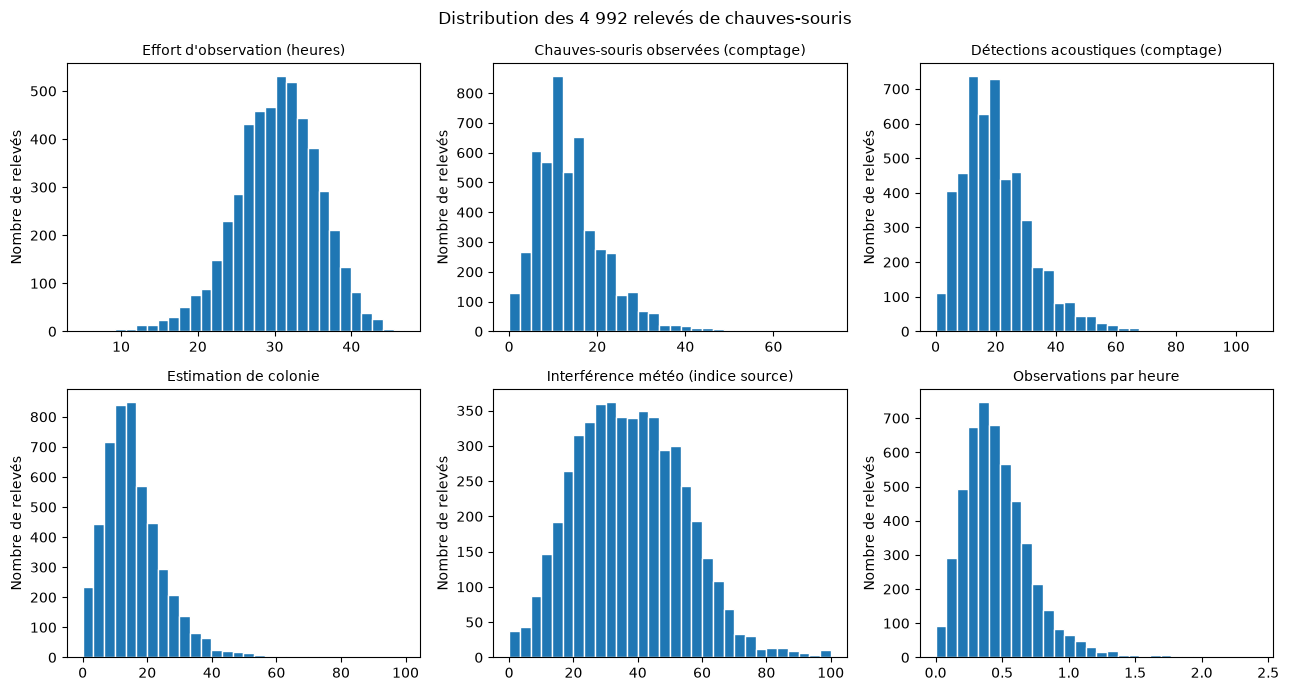

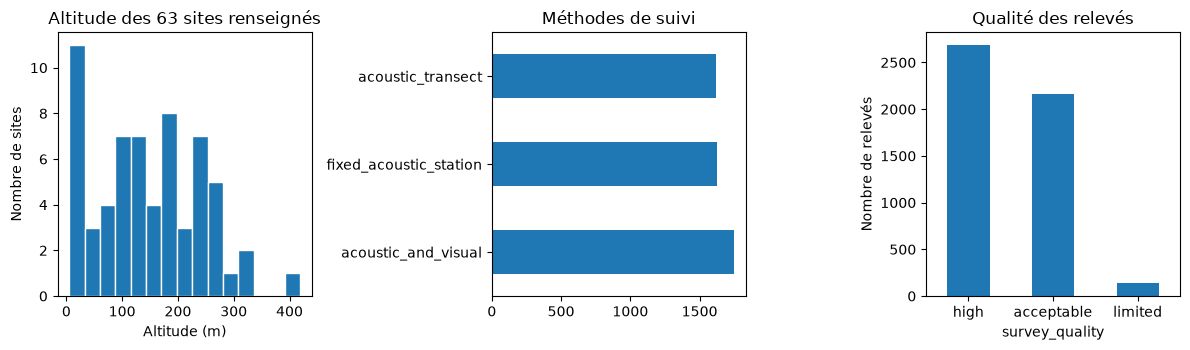

In [18]:
import numpy as np
import matplotlib.pyplot as plt

variables_histogrammes_ecology = {
    'observation_hours': "Effort d'observation (heures)",
    'observed_bat_count': 'Chauves-souris observées (comptage)',
    'acoustic_detection_count': 'Détections acoustiques (comptage)',
    'colony_estimate': 'Estimation de colonie',
    'weather_interference': 'Interférence météo (indice source)',
    'observations_par_heure': 'Observations par heure'
}
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for axe, (variable, titre) in zip(axes.flat, variables_histogrammes_ecology.items()):
    axe.hist(df_bats_enrichi[variable].dropna().astype(float), bins=30, edgecolor='white')
    axe.set_title(titre, fontsize=10)
    axe.set_ylabel('Nombre de relevés')
fig.suptitle('Distribution des 4 992 relevés de chauves-souris')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
df_sites['elevation_m'].dropna().plot.hist(bins=15, ax=axes[0], edgecolor='white')
axes[0].set_title('Altitude des 63 sites renseignés')
axes[0].set_xlabel('Altitude (m)')
axes[0].set_ylabel('Nombre de sites')
df_bats['survey_method'].value_counts().plot.barh(ax=axes[1])
axes[1].set_title('Méthodes de suivi')
axes[1].set_ylabel('')
df_bats['survey_quality'].value_counts().reindex(['high', 'acceptable', 'limited']).plot.bar(ax=axes[2], rot=0)
axes[2].set_title('Qualité des relevés')
axes[2].set_ylabel('Nombre de relevés')
plt.tight_layout()
plt.show()

### Comparaisons descriptives et relations entre variables

Nous comparons les distributions selon l'habitat, puis les relations entre effort,
observations, détections et météo. Pearson décrit une relation linéaire et Spearman
une relation monotone entre les rangs. Les 78 observations d'un site ne sont pas
78 sites indépendants. Ces corrélations regroupées sont descriptives, sans test
d'indépendance ni interprétation causale.

,nombre_sites,nombre_releves,mediane_observations_h,q1_observations_h,q3_observations_h
habitat_category,,,,,
coastal_habitat,10,780,0.401,0.303,0.534
degraded_land,2,156,0.142,0.082,0.215
durian_orchard,10,780,0.623,0.455,0.833
karst_habitat,9,702,0.513,0.358,0.684
mixed_agriculture,5,390,0.25,0.168,0.347
mixed_forest,19,1482,0.404,0.289,0.553
protected_forest,3,234,0.44,0.29,0.587
research_site,6,468,0.426,0.314,0.536


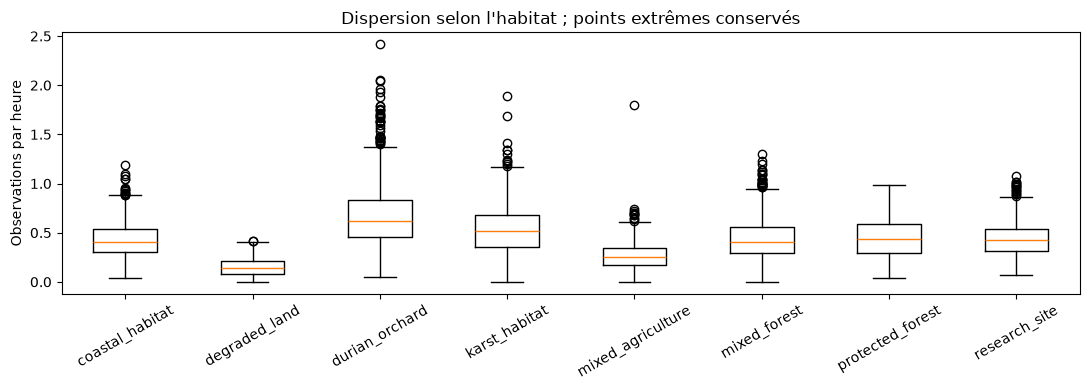

Pearson :


,observation_hours,observed_bat_count,acoustic_detection_count,colony_estimate,weather_interference
observation_hours,1.000,0.316,0.339,0.305,-0.688
observed_bat_count,0.316,1.000,0.783,0.961,-0.228
acoustic_detection_count,0.339,0.783,1.000,0.751,-0.364
colony_estimate,0.305,0.961,0.751,1.000,-0.219
weather_interference,-0.688,-0.228,-0.364,-0.219,1.000


Spearman :


,observation_hours,observed_bat_count,acoustic_detection_count,colony_estimate,weather_interference
observation_hours,1.000,0.324,0.352,0.312,-0.702
observed_bat_count,0.324,1.000,0.737,0.959,-0.231
acoustic_detection_count,0.352,0.737,1.000,0.709,-0.376
colony_estimate,0.312,0.959,0.709,1.000,-0.221
weather_interference,-0.702,-0.231,-0.376,-0.221,1.000


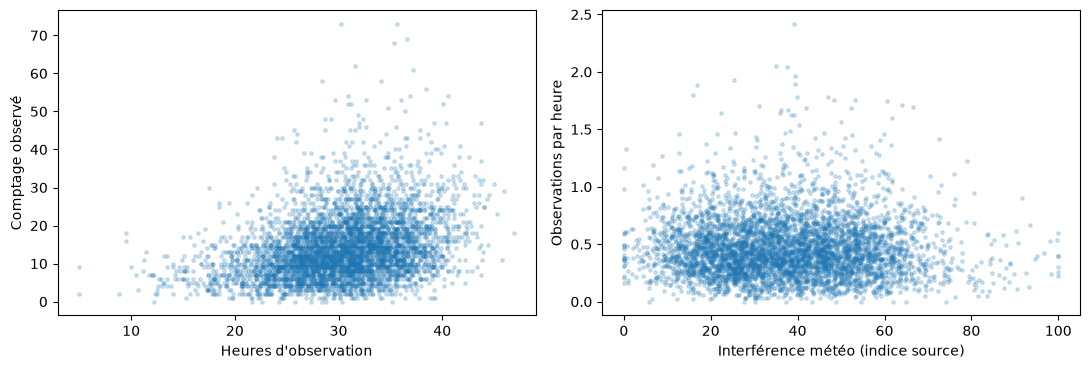

In [19]:
resume_habitats_ecology = df_bats_enrichi.groupby('habitat_category').agg(
    nombre_sites=('site_code', 'nunique'), nombre_releves=('survey_id', 'size'),
    mediane_observations_h=('observations_par_heure', 'median'),
    q1_observations_h=('observations_par_heure', lambda x: x.quantile(.25)),
    q3_observations_h=('observations_par_heure', lambda x: x.quantile(.75))
)
display(resume_habitats_ecology.round(3))
habitats_ecology = sorted(df_bats_enrichi['habitat_category'].unique())
fig, axe = plt.subplots(figsize=(11, 4))
axe.boxplot([df_bats_enrichi.loc[df_bats_enrichi['habitat_category'].eq(h), 'observations_par_heure'].astype(float) for h in habitats_ecology], tick_labels=habitats_ecology)
axe.tick_params(axis='x', rotation=30)
axe.set_ylabel('Observations par heure')
axe.set_title("Dispersion selon l'habitat ; points extrêmes conservés")
plt.tight_layout()
plt.show()

variables_correlation_ecology = ['observation_hours', 'observed_bat_count', 'acoustic_detection_count', 'colony_estimate', 'weather_interference']
correlations_pearson_bats = df_bats_enrichi[variables_correlation_ecology].corr(method='pearson')
correlations_spearman_bats = df_bats_enrichi[variables_correlation_ecology].corr(method='spearman')
print('Pearson :')
display(correlations_pearson_bats.round(3))
print('Spearman :')
display(correlations_spearman_bats.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(df_bats_enrichi['observation_hours'], df_bats_enrichi['observed_bat_count'], s=6, alpha=.2)
axes[0].set(xlabel="Heures d'observation", ylabel='Comptage observé')
axes[1].scatter(df_bats_enrichi['weather_interference'], df_bats_enrichi['observations_par_heure'], s=6, alpha=.2)
axes[1].set(xlabel='Interférence météo (indice source)', ylabel='Observations par heure')
plt.tight_layout()
plt.show()

**Lecture.** Les comptages, les estimations de colonie et les observations par heure
présentent une queue vers les valeurs élevées. Les heures d'observation sont
plus concentrées autour de 30 heures. Les habitats ne sont pas interchangeables :
les sites de vergers de durians présentent des indices centraux plus élevés que
ceux de terrains dégradés. Ces écarts ne démontrent pas un effet causal de l'habitat.

Les distributions et les boxplots servent à distinguer une valeur
fréquente d'une valeur extrême, pas à déclarer automatiquement une erreur.
Les relations entre comptages et estimations ne sont pas des confirmations
indépendantes d'un événement : les mesures peuvent partager la même information.
La division par les heures ne rend pas non plus les habitats interchangeables.
Nous conservons ces limites avant de comparer les sites.

### 3. Conditions environnementales — `environmental_monthly.csv`

Une ligne décrit un site et un mois. Nous contrôlons cette clé, retirons seulement
les répétitions exactes, corrigeons les formats numériques observés et conservons
les valeurs manquantes. Un code météo absent signifie seulement qu'aucun code
n'est renseigné dans la table. Il ne prouve pas l'absence d'un phénomène météo.

Dimensions brutes / nettoyées : (4994, 11) (4992, 11)


,type,manquants
site_code,str,0
reporting_month,datetime64[us],0
mean_temperature_c,Float64,0
rainfall_mm,Float64,0
mean_humidity_pct,Float64,0
vegetation_cover_pct,Float64,10
habitat_disturbance_index,Float64,0
pesticide_index,Float64,15
land_use_category,string,0
weather_exception_code,str,4788


,count,mean,std,min,25%,50%,75%,max
mean_temperature_c,4992.0,26.38,1.67,21.3,25.19,26.35,27.61,32.0
rainfall_mm,4992.0,159.89,74.9,5.0,95.7,156.25,221.7,384.3
mean_humidity_pct,4992.0,75.84,7.25,56.7,70.3,75.9,81.5,96.4
vegetation_cover_pct,4982.0,61.01,14.0,15.0,52.7,62.3,70.9,98.0
habitat_disturbance_index,4992.0,30.36,16.36,0.0,17.9,29.4,41.4,86.8
pesticide_index,4977.0,25.02,16.27,0.0,11.6,25.2,37.5,77.3
data_completeness_pct,4992.0,95.96,2.82,85.5,94.0,96.15,98.2,100.0


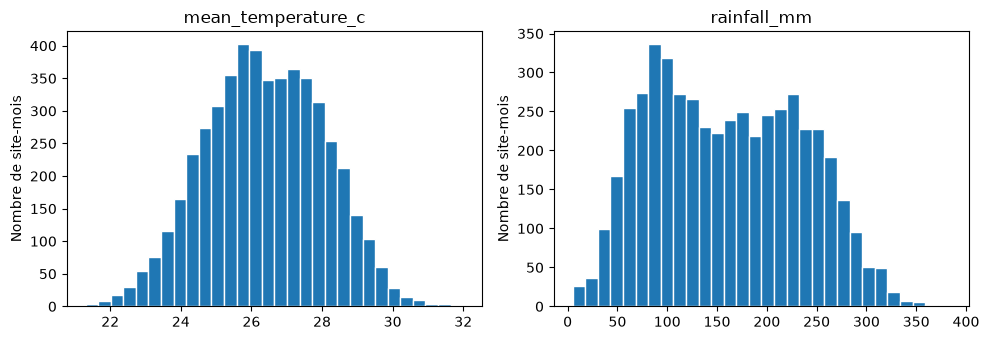

In [20]:
import re

def numerique_ecology(serie, unite=None):
    """Conversion ciblée ; une écriture inconnue provoque une erreur."""
    valeurs = serie.astype('string').str.strip().str.replace(',', '.', regex=False)
    if unite is not None:
        valeurs = valeurs.str.replace(r'\s+' + re.escape(unite) + r'$', '', regex=True)
    resultat = pd.to_numeric(valeurs, errors='raise')
    assert resultat.isna().sum() == serie.isna().sum()
    return resultat

def categorie_ecology(serie):
    return serie.astype('string').str.replace(r'\s+', ' ', regex=True).str.strip().str.lower()

def dates_heures_ecology(serie):
    """Les quatre écritures effectivement observées dans les dates/heures Ecology."""
    valeurs = serie.astype('string').str.strip()
    resultat = pd.Series(pd.NaT, index=serie.index, dtype='datetime64[us]')
    reconnus = pd.Series(False, index=serie.index)
    formats = [(r'^\d{4}-', '%Y-%m-%dT%H:%M:%S'), (r'^\d{4}/', '%Y/%m/%d %H:%M:%S'), (r'^\d{2}/', '%d/%m/%Y %H:%M:%S'), (r'^\d{2}-[A-Za-z]{3}-', '%d-%b-%Y %H:%M:%S')]
    for motif, format_date in formats:
        masque = valeurs.str.match(motif, na=False)
        resultat.loc[masque] = pd.to_datetime(valeurs.loc[masque], format=format_date, errors='raise')
        reconnus = reconnus | masque
    if not reconnus.all():
        raise ValueError('Format de date non reconnu : ' + str(valeurs.loc[~reconnus].unique()))
    return resultat

df_environnement_brut = pd.read_csv('data/ecology/environmental_monthly.csv')
df_environnement = df_environnement_brut.drop_duplicates().copy()
print('Dimensions brutes / nettoyées :', df_environnement_brut.shape, df_environnement.shape)
unites_environnement = {'mean_temperature_c': 'C', 'rainfall_mm': 'mm', 'mean_humidity_pct': None, 'vegetation_cover_pct': None, 'habitat_disturbance_index': None, 'pesticide_index': None, 'data_completeness_pct': None}
for colonne, unite in unites_environnement.items():
    df_environnement[colonne] = numerique_ecology(df_environnement[colonne], unite)
df_environnement['land_use_category'] = categorie_ecology(df_environnement['land_use_category'])
df_environnement['reporting_month'] = pd.to_datetime(df_environnement['reporting_month'], format='%Y-%m-%d', errors='raise')
df_environnement['mois_releve'] = df_environnement['reporting_month'].dt.to_period('M')
assert not df_environnement.duplicated(['site_code', 'mois_releve']).any()
for colonne in ['mean_humidity_pct', 'vegetation_cover_pct', 'data_completeness_pct']:
    assert df_environnement[colonne].dropna().between(0, 100).all()
assert df_environnement['rainfall_mm'].ge(0).all()
display(pd.DataFrame({'type': df_environnement.dtypes.astype(str), 'manquants': df_environnement.isna().sum()}))
display(df_environnement[list(unites_environnement)].describe().T.round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for axe, variable in zip(axes, ['mean_temperature_c', 'rainfall_mm']):
    axe.hist(df_environnement[variable].astype(float), bins=30, edgecolor='white')
    axe.set_title(variable)
    axe.set_ylabel('Nombre de site-mois')
plt.tight_layout()
plt.show()

Les valeurs manquantes de végétation et de pesticide restent non renseignées.
Les remplacer par zéro signifierait respectivement une absence de végétation ou
de pesticide, ce que la source ne dit pas. Pour les analyses complètes, nous
choisirons des variables sans manque ou expliciterons les lignes disponibles.

### 4. Fonctionnement des appareils — `monitoring_device_operations.csv`

La disponibilité et la qualité acoustique permettent de vérifier une explication
technique à un faible comptage. Le dictionnaire décrit `acoustic_quality` comme
catégorielle, mais les valeurs sont numériques et graduées : nous l'utilisons
comme un indice numérique source, sans lui attribuer une unité physique.
Les codes de panne et prestataires manquants ne sont pas inventés.

Dimensions brutes / nettoyées : (4994, 11) (4992, 12)


,count,mean,std,min,25%,50%,75%,max
uptime_pct,4992.0,92.53,7.93,23.1,90.2,93.8,97.3,100.0
acoustic_quality,4992.0,78.99,8.51,20.0,73.9,79.3,84.62,100.0


,non_renseignes
fault_code,4803
maintenance_provider,30


,nombre_operations
fault_code,
code non renseigné,4803
MICROPHONE_DRIFT,97
STORAGE_LIMIT,56
POWER_INTERRUPTION,36


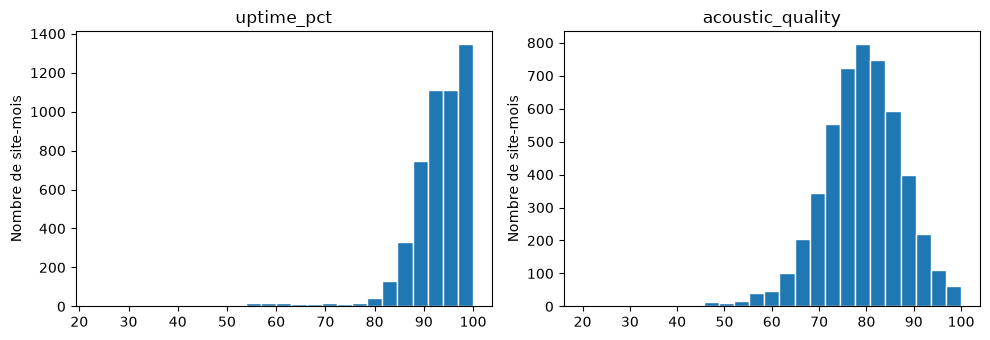

In [21]:
df_appareils_brut = pd.read_csv('data/ecology/monitoring_device_operations.csv')
df_appareils = df_appareils_brut.drop_duplicates().copy()
for colonne in ['uptime_pct', 'acoustic_quality']:
    df_appareils[colonne] = numerique_ecology(df_appareils[colonne])
for colonne in ['maintenance_type', 'record_status']:
    df_appareils[colonne] = categorie_ecology(df_appareils[colonne])
for colonne in ['operation_start', 'operation_end']:
    df_appareils[colonne] = dates_heures_ecology(df_appareils[colonne])
df_appareils['mois_releve'] = df_appareils['operation_start'].dt.to_period('M')
assert df_appareils['device_operation_id'].is_unique
assert not df_appareils.duplicated(['site_code', 'mois_releve']).any()
assert (df_appareils['operation_end'] > df_appareils['operation_start']).all()
assert df_appareils['uptime_pct'].between(0, 100).all()
print('Dimensions brutes / nettoyées :', df_appareils_brut.shape, df_appareils.shape)
display(df_appareils[['uptime_pct', 'acoustic_quality']].describe().T.round(2))
display(df_appareils[['fault_code', 'maintenance_provider']].isna().sum().to_frame('non_renseignes'))
display(df_appareils['fault_code'].fillna('code non renseigné').value_counts().to_frame('nombre_operations'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for axe, variable in zip(axes, ['uptime_pct', 'acoustic_quality']):
    axe.hist(df_appareils[variable].astype(float), bins=25, edgecolor='white')
    axe.set_title(variable)
    axe.set_ylabel('Nombre de site-mois')
plt.tight_layout()
plt.show()

### 5. Suivi des vergers — `orchard_surveys.csv`

Ces relevés concernent seulement les sites de vergers. Nous conservons l'unité
de chaque variable et calculons un rendement par hectare pour ne pas confondre
surface et production. Un mois sans récolte ne sera pas interprété comme une
anomalie avant l'examen de la saisonnalité. Les notes agricoles absentes restent
absentes, et non transformées en « absence de perturbation ».

Dimensions brutes / nettoyées : (1250, 11) (1248, 13)
Sites de vergers : 16


,count,mean,std,min,25%,50%,75%,max
orchard_area_ha,1248.0,45.53,18.98,6.0,29.9,49.35,59.32,84.7
durian_flower_density,1248.0,63.15,22.37,17.0,45.98,58.55,84.02,100.0
fruit_set_rate_pct,1248.0,53.2,10.22,0.47,46.9,52.8,59.4,87.7
durian_yield_kg,1248.0,47150.89,21479.64,3971.3,31192.9,46774.65,62028.28,118638.7
other_pollinator_activity,1248.0,59.44,9.37,27.9,53.3,59.5,65.7,93.7
fertilizer_use_index,1248.0,38.32,10.73,5.0,31.0,38.1,45.52,74.4
irrigation_level,1248.0,39.97,9.12,11.5,33.8,39.5,45.5,81.0
rendement_kg_ha,1248.0,1041.19,197.39,392.78,905.85,1038.25,1164.74,1815.73


,nombre_releves
agricultural_disturbance_note,
note non renseignée,1225
storm-related flower loss,18
elevated pesticide application,5


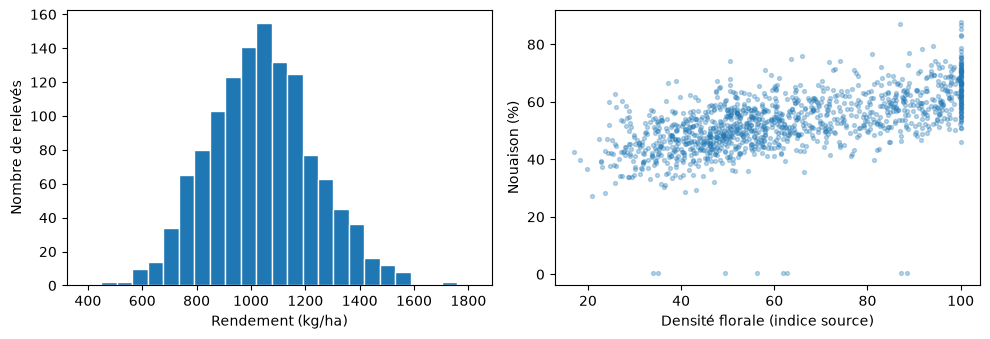

In [22]:
df_vergers_brut = pd.read_csv('data/ecology/orchard_surveys.csv')
df_vergers = df_vergers_brut.drop_duplicates().copy()
unites_vergers = {'orchard_area_ha': 'ha', 'durian_flower_density': None, 'fruit_set_rate_pct': None, 'durian_yield_kg': 'kg', 'other_pollinator_activity': None, 'fertilizer_use_index': None, 'irrigation_level': None}
for colonne, unite in unites_vergers.items():
    df_vergers[colonne] = numerique_ecology(df_vergers[colonne], unite)
df_vergers['survey_period'] = pd.to_datetime(df_vergers['survey_period'], format='%Y-%m-%d', errors='raise')
df_vergers['mois_releve'] = df_vergers['survey_period'].dt.to_period('M')
df_vergers['agricultural_disturbance_note'] = categorie_ecology(df_vergers['agricultural_disturbance_note'])
assert df_vergers['orchard_survey_id'].is_unique
assert not df_vergers.duplicated(['site_code', 'mois_releve']).any()
assert df_vergers['orchard_area_ha'].gt(0).all()
assert df_vergers['fruit_set_rate_pct'].between(0, 100).all()
assert df_vergers[list(unites_vergers)].ge(0).all().all()
df_vergers['rendement_kg_ha'] = df_vergers['durian_yield_kg'] / df_vergers['orchard_area_ha']
print('Dimensions brutes / nettoyées :', df_vergers_brut.shape, df_vergers.shape)
print('Sites de vergers :', df_vergers['site_code'].nunique())
display(df_vergers[list(unites_vergers) + ['rendement_kg_ha']].describe().T.round(2))
display(df_vergers['agricultural_disturbance_note'].fillna('note non renseignée').value_counts().to_frame('nombre_releves'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df_vergers['rendement_kg_ha'].astype(float), bins=25, edgecolor='white')
axes[0].set(xlabel='Rendement (kg/ha)', ylabel='Nombre de relevés')
axes[1].scatter(df_vergers['durian_flower_density'], df_vergers['fruit_set_rate_pct'], s=8, alpha=.3)
axes[1].set(xlabel='Densité florale (indice source)', ylabel='Nouaison (%)')
plt.tight_layout()
plt.show()

### 6. Rapports de terrain — `environmental_field_reports.csv`

Une ligne représente un document, pas un site-mois. Les 30 documents ne sont
donc pas ajoutés directement aux mesures : cela pourrait multiplier les relevés.
Nous vérifions séparément leurs références de site, de relevé et d'appareil.
La date d'un document, son mois de reporting et le mois du relevé cité sont trois
informations différentes. Une discordance est signalée sans déplacer les dates.

In [23]:
df_rapports_brut = pd.read_csv('data/ecology/environmental_field_reports.csv')
df_rapports = df_rapports_brut.drop_duplicates().copy()
assert df_rapports['document_id'].is_unique
df_rapports['document_date'] = pd.to_datetime(df_rapports['document_date'], format='%Y-%m-%d', errors='raise')
df_rapports['reporting_period'] = pd.to_datetime(df_rapports['reporting_period'], format='%Y-%m', errors='raise').dt.to_period('M')
print('Dimensions des documents :', df_rapports.shape)
display(df_rapports.isna().sum().to_frame('non_renseignes'))
display(df_rapports['document_type'].value_counts().to_frame('nombre_documents'))
display(df_rapports['publication_status'].value_counts().to_frame('nombre_documents'))
liens_rapports_ecology = df_rapports.merge(
    df_bats[['survey_id', 'site_code', 'survey_start', 'mois_releve']],
    left_on='related_survey_id', right_on='survey_id', how='left',
    validate='many_to_one', suffixes=('_document', '_releve'), indicator=True
)
liens_rapports_ecology['releve_trouve'] = liens_rapports_ecology['_merge'].eq('both')
liens_rapports_ecology['site_concordant'] = liens_rapports_ecology['site_code_document'].eq(liens_rapports_ecology['site_code_releve'])
liens_rapports_ecology['mois_concordant'] = liens_rapports_ecology['reporting_period'].eq(liens_rapports_ecology['mois_releve'])
liens_rapports_ecology['document_avant_releve'] = liens_rapports_ecology['document_date'].lt(liens_rapports_ecology['survey_start'])
references_appareil_ecology = df_appareils[['site_code', 'device_reference']].drop_duplicates()
liens_appareil_rapports = df_rapports.merge(references_appareil_ecology, left_on=['site_code', 'related_device_reference'], right_on=['site_code', 'device_reference'], how='left', validate='many_to_one', indicator=True)
print('Contrôle des références documentaires :')
display(liens_rapports_ecology[['releve_trouve', 'site_concordant', 'mois_concordant', 'document_avant_releve']].sum().to_frame('nombre_documents'))
print('Références site-appareil retrouvées :', liens_appareil_rapports['_merge'].eq('both').sum())
display(liens_rapports_ecology[['document_id', 'site_code_document', 'document_date', 'related_survey_id', 'survey_start', 'mois_concordant', 'document_avant_releve']].head(6))

Dimensions des documents : (30, 12)


,non_renseignes
document_id,0
site_code,0
document_date,0
document_type,0
author_name,1
author_organization,0
reporting_period,0
title,0
text,0
related_survey_id,0


,nombre_documents
document_type,
ecological_incident_report,6
field_observation,6
monitoring_report,6
cave_access_note,6
sensor_quality_report,6


,nombre_documents
publication_status,
restricted,12
public,10
internal,8


Contrôle des références documentaires :


,nombre_documents
releve_trouve,30
site_concordant,30
mois_concordant,2
document_avant_releve,15


Références site-appareil retrouvées : 30


,document_id,site_code_document,document_date,related_survey_id,survey_start,mois_concordant,document_avant_releve
0,EFR-510088,KNT-KES,2024-04-02,BAT-0000064,2024-04-05 18:00:00,True,True
1,EFR-510082,KNT-JAK,2019-04-01,BAT-0001000,2024-04-05 18:00:00,False,True
2,EFR-510035,KNT-JQG,2022-09-08,BAT-0001037,2020-11-05 18:00:00,False,False
3,EFR-510007,KNT-JQG,2025-02-15,BAT-0001074,2023-12-05 18:00:00,False,False
4,EFR-510031,KNT-VLB,2020-07-22,BAT-0001111,2020-07-05 18:00:00,True,False
5,EFR-510020,KNT-VLB,2023-12-02,BAT-0001148,2023-08-05 18:00:00,False,False


Les 30 références de relevé et les 30 couples site-appareil sont retrouvés.
Cependant, seuls 2 rapports sur 30 portent sur le même mois que le relevé cité,
et 15 documents sont datés avant ce relevé. Une référence peut désigner un relevé
historique ou comparatif, mais un document antérieur à son relevé cité pose une
question de chronologie. Nous ne synchronisons donc pas automatiquement tous
les rapports avec les mesures à partir du seul mois documentaire.

### Table commune et relations avec les conditions de collecte

Les mesures de chauves-souris, la météo et les appareils sont reliés par
`site_code` et mois. La validation un-à-un empêche les multiplications de lignes.
Les vergers sont ajoutés seulement pour les sites concernés. Les absences de
données de verger sur les autres sites sont structurelles, pas des zéros.
Les données mensuelles des appareils ne constituent pas un journal de panne
pendant les seules heures du relevé : leur concordance temporelle reste grossière.

In [24]:
colonnes_env_ecology = ['site_code', 'mois_releve'] + list(unites_environnement) + ['weather_exception_code']
colonnes_app_ecology = ['site_code', 'mois_releve', 'device_reference', 'uptime_pct', 'acoustic_quality', 'fault_code', 'maintenance_type', 'maintenance_provider']
ecologie_mensuelle = df_bats_enrichi.merge(df_environnement[colonnes_env_ecology], on=['site_code', 'mois_releve'], how='left', validate='one_to_one', indicator='_lien_env')
ecologie_mensuelle = ecologie_mensuelle.merge(df_appareils[colonnes_app_ecology], on=['site_code', 'mois_releve'], how='left', validate='one_to_one', indicator='_lien_app')
assert len(ecologie_mensuelle) == len(df_bats)
assert ecologie_mensuelle['_lien_env'].eq('both').all()
assert ecologie_mensuelle['_lien_app'].eq('both').all()
ecologie_mensuelle = ecologie_mensuelle.drop(columns=['_lien_env', '_lien_app'])
vergers_analyses_ecology = df_vergers.merge(ecologie_mensuelle[['site_code', 'mois_releve', 'observations_par_heure', 'detections_acoustiques_par_heure']], on=['site_code', 'mois_releve'], how='left', validate='one_to_one', indicator=True)
assert vergers_analyses_ecology['_merge'].eq('both').all()
assert set(df_vergers['site_code']) == set(df_sites.loc[df_sites['site_category'].eq('orchard monitoring'), 'site_code'])
print('Table commune :', ecologie_mensuelle.shape, '; relevés vergers reliés :', len(vergers_analyses_ecology))
variables_conditions_ecology = ['observations_par_heure', 'detections_acoustiques_par_heure', 'rainfall_mm', 'mean_temperature_c', 'weather_interference', 'uptime_pct', 'acoustic_quality', 'habitat_disturbance_index']
correlations_conditions_ecology = ecologie_mensuelle[variables_conditions_ecology].corr(method='spearman')
display(correlations_conditions_ecology.loc[['observations_par_heure', 'detections_acoustiques_par_heure']].round(3))
correlations_vergers_ecology = vergers_analyses_ecology[['observations_par_heure', 'fruit_set_rate_pct', 'rendement_kg_ha', 'durian_flower_density', 'other_pollinator_activity', 'fertilizer_use_index']].corr(method='spearman')
display(correlations_vergers_ecology.round(3))

Table commune :

 (4992, 35) ; relevés vergers reliés : 1248


,observations_par_heure,detections_acoustiques_par_heure,rainfall_mm,mean_temperature_c,weather_interference,uptime_pct,acoustic_quality,habitat_disturbance_index
observations_par_heure,1.000,0.691,-0.012,0.150,-0.022,0.002,-0.002,-0.402
detections_acoustiques_par_heure,0.691,1.000,-0.149,0.178,-0.180,0.014,0.221,-0.400


,observations_par_heure,fruit_set_rate_pct,rendement_kg_ha,durian_flower_density,other_pollinator_activity,fertilizer_use_index
observations_par_heure,1.000,0.477,0.448,0.270,0.314,-0.039
fruit_set_rate_pct,0.477,1.000,0.895,0.653,0.414,0.036
rendement_kg_ha,0.448,0.895,1.000,0.595,0.401,0.036
durian_flower_density,0.270,0.653,0.595,1.000,0.029,0.022
other_pollinator_activity,0.314,0.414,0.401,0.029,1.000,-0.025
fertilizer_use_index,-0.039,0.036,0.036,0.022,-0.025,1.000


### Qualité, effort et couverture des six sources

Nous approfondissons les différences de collecte avant de comparer les sites.
L'objectif est de vérifier si un résultat peut venir d'une différence d'effort,
de qualité ou de couverture, plutôt que d'une différence écologique.
Les absences structurelles des vergers sont distinguées des valeurs manquantes.

In [25]:
audit_sources_ecology = pd.DataFrame([
    {'fichier': 'sites', 'lignes_brutes': len(df_sites_brut), 'lignes_nettoyees': len(df_sites), 'sites': df_sites['site_code'].nunique()},
    {'fichier': 'chauves_souris', 'lignes_brutes': len(df_bats_brut), 'lignes_nettoyees': len(df_bats), 'sites': df_bats['site_code'].nunique()},
    {'fichier': 'environnement', 'lignes_brutes': len(df_environnement_brut), 'lignes_nettoyees': len(df_environnement), 'sites': df_environnement['site_code'].nunique()},
    {'fichier': 'appareils', 'lignes_brutes': len(df_appareils_brut), 'lignes_nettoyees': len(df_appareils), 'sites': df_appareils['site_code'].nunique()},
    {'fichier': 'vergers', 'lignes_brutes': len(df_vergers_brut), 'lignes_nettoyees': len(df_vergers), 'sites': df_vergers['site_code'].nunique()},
    {'fichier': 'rapports', 'lignes_brutes': len(df_rapports_brut), 'lignes_nettoyees': len(df_rapports), 'sites': df_rapports['site_code'].nunique()}
])
audit_sources_ecology['doublons_exacts_retires'] = audit_sources_ecology['lignes_brutes'] - audit_sources_ecology['lignes_nettoyees']
display(audit_sources_ecology)
qualite_collecte_ecology = ecologie_mensuelle.groupby('survey_quality').agg(
    relevements=('survey_id', 'size'), heures_medianes=('observation_hours', 'median'),
    disponibilite_mediane=('uptime_pct', 'median'), qualite_acoustique_mediane=('acoustic_quality', 'median'),
    meteo_mediane=('weather_interference', 'median'), observations_h_medianes=('observations_par_heure', 'median'),
    detections_h_medianes=('detections_acoustiques_par_heure', 'median')
)
display(qualite_collecte_ecology.round(3))
couverture_autres_sources_ecology = []
for nom, tableau in [('environnement', df_environnement), ('appareils', df_appareils), ('vergers', df_vergers)]:
    couverture = pd.crosstab(tableau['site_code'], tableau['mois_releve']).reindex(columns=mois_attendus, fill_value=0)
    couverture_autres_sources_ecology.append({'source': nom, 'sites': len(couverture), 'mois_absents_sur_sites_concernes': int(couverture.eq(0).sum().sum()), 'site_mois_multiples': int(couverture.gt(1).sum().sum())})
display(pd.DataFrame(couverture_autres_sources_ecology))

,fichier,lignes_brutes,lignes_nettoyees,sites,doublons_exacts_retires
0,sites,64,64,64,0
1,chauves_souris,4994,4992,64,2
2,environnement,4994,4992,64,2
3,appareils,4994,4992,64,2
4,vergers,1250,1248,16,2
5,rapports,30,30,16,0


,relevements,heures_medianes,disponibilite_mediane,qualite_acoustique_mediane,meteo_mediane,observations_h_medianes,detections_h_medianes
survey_quality,,,,,,,
acceptable,2166,29.0,93.4,73.7,43.6,0.422,0.556
high,2688,32.0,94.3,83.9,31.4,0.427,0.668
limited,138,19.05,58.5,56.7,36.5,0.411,0.455


,source,sites,mois_absents_sur_sites_concernes,site_mois_multiples
0,environnement,64,0,0
1,appareils,64,0,0
2,vergers,16,0,0


Les relevés de qualité limitée présentent une disponibilité médiane de 58,5 %, contre plus de 93 % dans les deux autres classes. Leur indice acoustique médian est plus faible (0,455 contre 0,668 pour `high`), tandis que l'indice visuel varie peu. Cela motive les contrôles de sensibilité, sans autoriser une correction automatique des comptages. Les trois séries mensuelles complémentaires n'ont ni mois absent ni site-mois multiple sur leurs sites respectifs.

### Relations globales, entre sites et à l'intérieur des sites

Une corrélation globale peut mélanger deux phénomènes : des sites durablement
différents et des changements au cours du temps sur un même site. Nous comparons
donc la corrélation regroupée, celle des médianes par site et celle obtenue après
soustraction de la médiane de chaque site. Ce centrage ne retire pas la saison
et ne transforme pas l'analyse descriptive en expérience causale.

,tous_les_releves_spearman,medianes_64_sites_spearman,deviations_intra_site_spearman
detections_acoustiques_par_heure,0.691,0.969,0.405
rainfall_mm,-0.012,-0.110,0.029
mean_temperature_c,0.150,0.020,0.251
habitat_disturbance_index,-0.402,-0.498,-0.177
uptime_pct,0.002,-0.153,0.015
acoustic_quality,-0.002,-0.020,-0.008


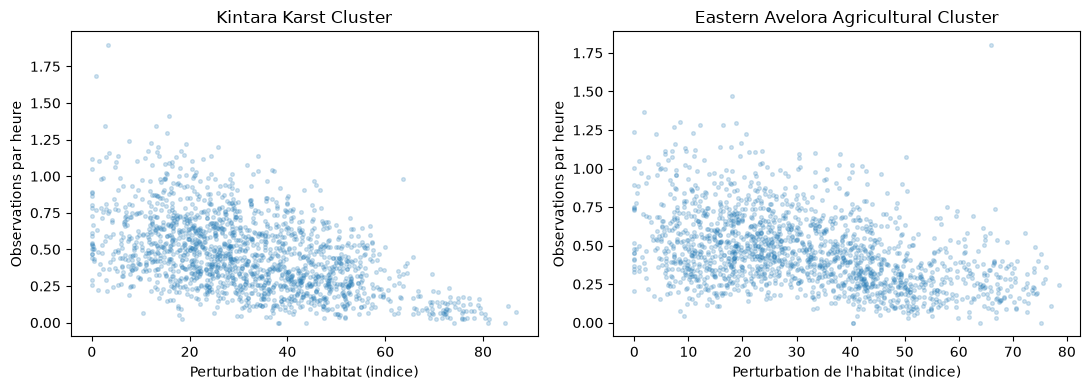

In [26]:
variables_contextes_ecology = ['observations_par_heure', 'detections_acoustiques_par_heure', 'rainfall_mm', 'mean_temperature_c', 'habitat_disturbance_index', 'uptime_pct', 'acoustic_quality']
medians_sites_conditions_ecology = ecologie_mensuelle.groupby('site_code')[variables_contextes_ecology].median()
deviations_sites_ecology = ecologie_mensuelle[variables_contextes_ecology] - ecologie_mensuelle.groupby('site_code')[variables_contextes_ecology].transform('median')
comparaison_correlations_ecology = pd.DataFrame({
    'tous_les_releves_spearman': ecologie_mensuelle[variables_contextes_ecology].corr(method='spearman')['observations_par_heure'],
    'medianes_64_sites_spearman': medians_sites_conditions_ecology.corr(method='spearman')['observations_par_heure'],
    'deviations_intra_site_spearman': deviations_sites_ecology.corr(method='spearman')['observations_par_heure']
})
display(comparaison_correlations_ecology.drop(index='observations_par_heure').round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axe, region in zip(axes, ['Kintara Karst Cluster', 'Eastern Avelora Agricultural Cluster']):
    sous_ensemble = ecologie_mensuelle.loc[ecologie_mensuelle['region'].eq(region)]
    axe.scatter(sous_ensemble['habitat_disturbance_index'], sous_ensemble['observations_par_heure'], s=7, alpha=.2)
    axe.set(xlabel="Perturbation de l'habitat (indice)", ylabel='Observations par heure', title=region)
plt.tight_layout()
plt.show()

La corrélation observations–détections passe de 0,691 globalement à 0,405 après centrage par site, alors qu'elle atteint 0,969 entre les médianes des sites. Une grande part du lien concerne donc les différences durables entre sites. La perturbation de l'habitat reste négativement associée à l'activité après centrage, mais plus faiblement (−0,177 contre −0,402). Aucun de ces coefficients n'isole un effet causal.

### Nouaison, rendement et explications agricoles concurrentes

Le lien entre chauves-souris et vergers doit être examiné avec les fleurs,
les autres pollinisateurs, les pesticides et les notes de perturbation.
Les tableaux suivants décrivent les observations disponibles. Les notes non
renseignées ne sont pas une preuve d'absence de perturbation.

In [27]:
vergers_contextuels_ecology = df_vergers.merge(ecologie_mensuelle[['site_code', 'mois_releve', 'region', 'rainfall_mm', 'pesticide_index', 'observations_par_heure', 'detections_acoustiques_par_heure']], on=['site_code', 'mois_releve'], validate='one_to_one')
vergers_contextuels_ecology['note_affichee'] = vergers_contextuels_ecology['agricultural_disturbance_note'].fillna('non renseignée')
vergers_contextuels_ecology['echelle_nouaison_a_verifier'] = vergers_contextuels_ecology['fruit_set_rate_pct'].gt(0) & vergers_contextuels_ecology['fruit_set_rate_pct'].lt(1)
print('Taux entre 0 et 1 dans une colonne déclarée en pourcentage :', vergers_contextuels_ecology['echelle_nouaison_a_verifier'].sum())
resume_notes_vergers_ecology = vergers_contextuels_ecology.groupby('note_affichee').agg(
    nombre_releves=('orchard_survey_id', 'size'), nombre_sites=('site_code', 'nunique'),
    nouaison_mediane=('fruit_set_rate_pct', 'median'), rendement_median_kg_ha=('rendement_kg_ha', 'median'),
    pesticide_median=('pesticide_index', 'median'), observations_h_medianes=('observations_par_heure', 'median')
)
display(resume_notes_vergers_ecology.round(3))
print('Relevés de nouaison les plus faibles, conservés pour examen :')
display(vergers_contextuels_ecology.nsmallest(8, 'fruit_set_rate_pct')[['site_code', 'mois_releve', 'fruit_set_rate_pct', 'durian_flower_density', 'pesticide_index', 'agricultural_disturbance_note']])
vergers_medians_site_ecology = vergers_contextuels_ecology.groupby('site_code')[['observations_par_heure', 'fruit_set_rate_pct', 'rendement_kg_ha']].median()
vergers_deviations_ecology = vergers_contextuels_ecology[['observations_par_heure', 'fruit_set_rate_pct', 'rendement_kg_ha']] - vergers_contextuels_ecology.groupby('site_code')[['observations_par_heure', 'fruit_set_rate_pct', 'rendement_kg_ha']].transform('median')
display(pd.DataFrame({
    'correlation_globale': vergers_contextuels_ecology[['observations_par_heure', 'fruit_set_rate_pct', 'rendement_kg_ha']].corr(method='spearman')['observations_par_heure'],
    'correlation_entre_sites': vergers_medians_site_ecology.corr(method='spearman')['observations_par_heure'],
    'correlation_deviations_intra_site': vergers_deviations_ecology.corr(method='spearman')['observations_par_heure']
}).round(3))
# Hypothèse de sensibilité uniquement : certains taux pourraient être des proportions.
# Nous ne remplaçons pas les valeurs originales sur cette seule supposition.
masque_ambigu = vergers_contextuels_ecology['echelle_nouaison_a_verifier']
nouaison_hypothese_ecology = vergers_contextuels_ecology['fruit_set_rate_pct'].where(~masque_ambigu, vergers_contextuels_ecology['fruit_set_rate_pct'] * 100)
sensibilite_echelle_nouaison_ecology = pd.Series({
    'valeurs_originales': vergers_contextuels_ecology['observations_par_heure'].corr(vergers_contextuels_ecology['fruit_set_rate_pct'], method='spearman'),
    'sans_taux_a_verifier': vergers_contextuels_ecology.loc[~masque_ambigu, 'observations_par_heure'].corr(vergers_contextuels_ecology.loc[~masque_ambigu, 'fruit_set_rate_pct'], method='spearman'),
    'hypothese_taux_multiplies_par_100': vergers_contextuels_ecology['observations_par_heure'].corr(nouaison_hypothese_ecology, method='spearman')
}, name='correlation_spearman')
display(sensibilite_echelle_nouaison_ecology.round(3))

Taux entre 0 et 1 dans une colonne déclarée en pourcentage : 8


,nombre_releves,nombre_sites,nouaison_mediane,rendement_median_kg_ha,pesticide_median,observations_h_medianes
note_affichee,,,,,,
elevated pesticide application,5,2,46.2,986.924,68.2,0.137
non renseignée,1225,16,53.1,1039.805,38.0,0.478
storm-related flower loss,18,6,45.3,857.573,51.55,0.198


Relevés de nouaison les plus faibles, conservés pour examen :


,site_code,mois_releve,fruit_set_rate_pct,durian_flower_density,pesticide_index,agricultural_disturbance_note
919,AVL-NMQ,2024-02,0.467,35.1,30.2,<NA>
412,AVL-GRB,2020-11,0.543,49.4,45.2,<NA>
454,AVL-GRB,2024-05,0.549,88.5,66.4,elevated pesticide application
1180,TMB-HQL,2019-11,0.555,62.7,32.8,<NA>
716,AVL-YAU,2020-03,0.561,61.8,40.1,<NA>
269,AVL-TRP,2021-12,0.568,56.3,18.5,<NA>
1060,TMB-BRC,2022-11,0.581,33.9,8.0,<NA>
718,AVL-YAU,2020-05,0.595,87.3,47.0,<NA>


,correlation_globale,correlation_entre_sites,correlation_deviations_intra_site
observations_par_heure,1.000,1.000,1.000
fruit_set_rate_pct,0.477,0.682,0.374
rendement_kg_ha,0.448,0.656,0.332


valeurs_originales                   0.477
sans_taux_a_verifier                 0.487
hypothese_taux_multiplies_par_100    0.486
Name: correlation_spearman, dtype: float64

Les huit taux de nouaison compris entre 0 et 1 demandent une vérification d'échelle, pas une multiplication automatique : un pourcentage inférieur à 1 reste possible. La corrélation avec l'activité des chauves-souris reste voisine de 0,48 dans les trois scénarios (0,477 ; 0,487 ; 0,486). Les notes de tempête ou de pesticides correspondent à une activité médiane plus faible, mais ne concernent que 18 et 5 relevés ; une note absente ne signifie pas une absence de perturbation.

### Bilan du cours 1

Les six fichiers ont été examinés à leur propre granularité. Les identifiants
restent intacts, les répétitions exactes sont supprimées, les formats sont
harmonisés et les valeurs absentes ne sont pas inventées. La table commune
permet maintenant de vérifier les explications environnementales et techniques.

Les corrélations ne suffisent pas à départager saison, habitat et conditions
de collecte. Les observations répétées d'un même site et les variations
saisonnières peuvent produire des relations apparentes. Nous n'en déduisons
ni un effet causal des chauves-souris sur le rendement, ni une activité clandestine.

Dans les vergers, la corrélation de Spearman entre observations par heure et
nouaison vaut environ 0,477, et celle avec le rendement par hectare environ 0,448.
La densité florale, la saison et les autres pollinisateurs peuvent aussi intervenir.
Dans la table commune, les observations par heure sont peu corrélées globalement
à la météo et à la disponibilité. La relation avec l'indice de perturbation
de l'habitat est négative (environ −0,402). Ce sont des pistes de comparaison,
pas des effets isolés par une expérience ou un modèle causal.

## Cours 2 — Comparer les profils des sites

**Question.** Certains sites ont-ils des profils d'activité proches ?
Nous utilisons une ligne par site, et non 78 lignes considérées comme des sites
différents. Le profil retient les médianes des deux indices d'activité, leur
variabilité interquartile et le comptage médian des espèces de comparaison.
Ces dernières ne sont pas une population témoin expérimentale.

Nous vérifions les redondances, standardisons, puis comparons les profils par
distance euclidienne. La PCA sert à visualiser. Un K-means exploratoire est
comparé pour plusieurs nombres de groupes, sans supposer que les groupes
correspondent aux régions ou à des catégories biologiques réelles.

,observations_medianes,detections_medianes,variabilite_observations,especes_comparaison_medianes
observations_medianes,1.000,0.985,0.833,0.427
detections_medianes,0.985,1.000,0.816,0.434
variabilite_observations,0.833,0.816,1.000,0.362
especes_comparaison_medianes,0.427,0.434,0.362,1.000


Variables retenues : ['observations_medianes', 'variabilite_observations', 'especes_comparaison_medianes']


,site_voisin,distance
site_code,,
AVL-ABG,KNT-TEX,0.144
AVL-ARU,KNT-GKR,0.409
AVL-BVM,TMB-WYT,0.387
AVL-BWK,AVL-ECJ,0.171
AVL-DER,TMB-WYT,0.114
AVL-ECJ,AVL-BWK,0.171
AVL-FNM,KNT-QWU,0.421
AVL-FNQ,AVL-GRB,0.173


,k,silhouette
0,2,0.364
1,3,0.377
2,4,0.380
3,5,0.318
4,6,0.275


,nombre_sites
cluster_ecology,
0,33
1,12
2,1
3,18


,observations_medianes,detections_medianes,variabilite_observations,especes_comparaison_medianes
cluster_ecology,,,,
0,0.422,0.601,0.196,11.0
1,0.233,0.325,0.149,9.0
2,1.354,1.959,0.442,12.0
3,0.617,0.898,0.3,11.0


Profils isolés dans cette partition :


,observations_medianes,detections_medianes,variabilite_observations,especes_comparaison_medianes
site_code,,,,
TMB-BRC,1.354409,1.959277,0.442096,12.0


Variance expliquée par les deux axes : [0.704 0.241]


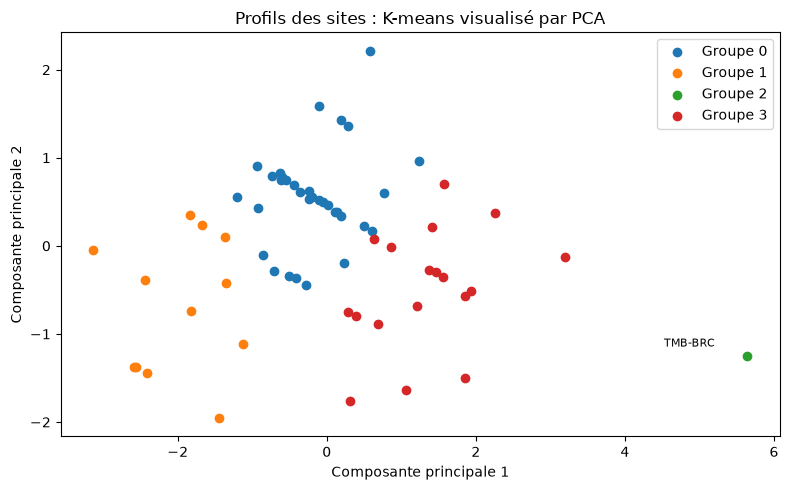

In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances, silhouette_score
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

profil_sites_ecology = ecologie_mensuelle.groupby('site_code').agg(
    observations_medianes=('observations_par_heure', 'median'),
    detections_medianes=('detections_acoustiques_par_heure', 'median'),
    variabilite_observations=('observations_par_heure', lambda x: x.quantile(.75) - x.quantile(.25)),
    especes_comparaison_medianes=('comparison_species_count', 'median')
)
correlation_profils_ecology = profil_sites_ecology.corr()
display(correlation_profils_ecology.round(3))
variables_profil_ecology = list(profil_sites_ecology.columns)
# Éviter de compter deux fois une information presque identique.
if abs(correlation_profils_ecology.loc['observations_medianes', 'detections_medianes']) > .90:
    variables_profil_ecology.remove('detections_medianes')
print('Variables retenues :', variables_profil_ecology)
scaler_sites_ecology = StandardScaler()
profils_standardises_ecology = pd.DataFrame(scaler_sites_ecology.fit_transform(profil_sites_ecology[variables_profil_ecology]), index=profil_sites_ecology.index, columns=variables_profil_ecology)
distances_sites_ecology = pd.DataFrame(pairwise_distances(profils_standardises_ecology), index=profil_sites_ecology.index, columns=profil_sites_ecology.index)
distances_voisins_ecology = distances_sites_ecology.to_numpy(copy=True)
np.fill_diagonal(distances_voisins_ecology, np.inf)
voisins_sites_ecology = pd.DataFrame({'site_voisin': profil_sites_ecology.index[np.argmin(distances_voisins_ecology, axis=1)], 'distance': distances_voisins_ecology.min(axis=1)}, index=profil_sites_ecology.index)
display(voisins_sites_ecology.head(8).round(3))

scores_k_ecology = []
for k in range(2, 7):
    etiquettes = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(profils_standardises_ecology)
    scores_k_ecology.append({'k': k, 'silhouette': silhouette_score(profils_standardises_ecology, etiquettes)})
scores_k_ecology = pd.DataFrame(scores_k_ecology)
display(scores_k_ecology.round(3))
k_sites_ecology = int(scores_k_ecology.loc[scores_k_ecology['silhouette'].idxmax(), 'k'])
modele_sites_ecology = KMeans(n_clusters=k_sites_ecology, random_state=42, n_init=20)
groupes_sites_ecology = pd.Series(modele_sites_ecology.fit_predict(profils_standardises_ecology), index=profil_sites_ecology.index, name='cluster_ecology')
description_groupes_ecology = profil_sites_ecology.join(groupes_sites_ecology).groupby('cluster_ecology').median()
display(groupes_sites_ecology.value_counts().sort_index().to_frame('nombre_sites'))
display(description_groupes_ecology.round(3))
groupes_isoles_ecology = groupes_sites_ecology.value_counts().loc[lambda x: x.eq(1)].index
print('Profils isolés dans cette partition :')
display(profil_sites_ecology.loc[groupes_sites_ecology.isin(groupes_isoles_ecology)])
pca_sites_ecology = PCA(n_components=2)
projection_sites_ecology = pca_sites_ecology.fit_transform(profils_standardises_ecology)
print('Variance expliquée par les deux axes :', pca_sites_ecology.explained_variance_ratio_.round(3))
fig, axe = plt.subplots(figsize=(8, 5))
for groupe in sorted(groupes_sites_ecology.unique()):
    masque = groupes_sites_ecology.eq(groupe).to_numpy()
    axe.scatter(projection_sites_ecology[masque, 0], projection_sites_ecology[masque, 1], label=f'Groupe {groupe}')
for site in profil_sites_ecology.index[groupes_sites_ecology.isin(groupes_isoles_ecology)]:
    position = profil_sites_ecology.index.get_loc(site)
    axe.annotate(site, projection_sites_ecology[position], xytext=(-60, 7), textcoords='offset points', fontsize=8)
axe.set(xlabel='Composante principale 1', ylabel='Composante principale 2', title='Profils des sites : K-means visualisé par PCA')
axe.legend()
plt.tight_layout()
plt.show()

Les médianes d'observation et de détection sont très corrélées entre sites
(Pearson ≈ 0,985) : seule la première est conservée dans le calcul des distances.
Les deux axes PCA représentent environ 94,6 % de la variance du profil standardisé.

Parmi les valeurs testées, k = 4 maximise légèrement la silhouette (≈ 0,380),
contre ≈ 0,377 pour k = 3. Les quatre groupes contiennent 33, 12, 1 et 18 sites :
la présence d'un singleton et le faible écart de score ne permettent pas
d'affirmer que quatre groupes naturels ont été découverts.
Le singleton est TMB-BRC, dont la médiane d'observation atteint environ
1,354 observation par heure. C'est un profil durablement élevé dans cette
représentation, pas une preuve d'erreur ou de baisse récente.

Le score de silhouette compare uniquement les partitions testées avec ce profil
et cette distance. Il ne démontre pas l'existence de groupes naturels.
Les regroupements résument des niveaux et une dispersion sur toute la période :
ils peuvent manquer une baisse récente et localisée. Nous ne multiplions pas
les projections t-SNE ou les algorithmes de clustering sans question supplémentaire.

### Robustesse aux choix de distance et de regroupement

Le faible écart entre k = 3 et k = 4 appelle une comparaison plutôt qu'un choix
définitif. Nous vérifions si le plus proche voisin change avec Manhattan, puis
comparons une partition hiérarchique moyenne à K-means. Le dendrogramme tronqué
présente les grandes branches, pas une nouvelle classification biologique.

Même plus proche voisin selon les deux distances : 53 sur 64


,site_voisin,distance,voisin_manhattan,meme_voisin
site_code,,,,
AVL-NFR,TMB-HFR,0.701996,KNT-YRG,False
AVL-NMQ,AVL-VEL,0.587653,KNT-JAK,False
AVL-RBC,AVL-YAU,0.815563,KNT-UJJ,False
AVL-TRP,KNT-YRX,1.058652,AVL-HUA,False
KNT-NNM,TMB-CKU,0.282641,TMB-WST,False
KNT-TEX,AVL-ABG,0.143531,TMB-WQL,False
KNT-TLQ,KNT-BME,1.134172,TMB-GWP,False
KNT-UJJ,AVL-RBC,0.820682,TMB-HVD,False
KNT-YRG,KNT-GGN,0.778022,AVL-NFR,False


,methode,k,silhouette,plus_petit_groupe,plus_grand_groupe
0,kmeans,3,0.377,12,35
1,hierarchique_moyenne,3,0.373,1,50
2,kmeans,4,0.380,1,33
3,hierarchique_moyenne,4,0.358,1,35


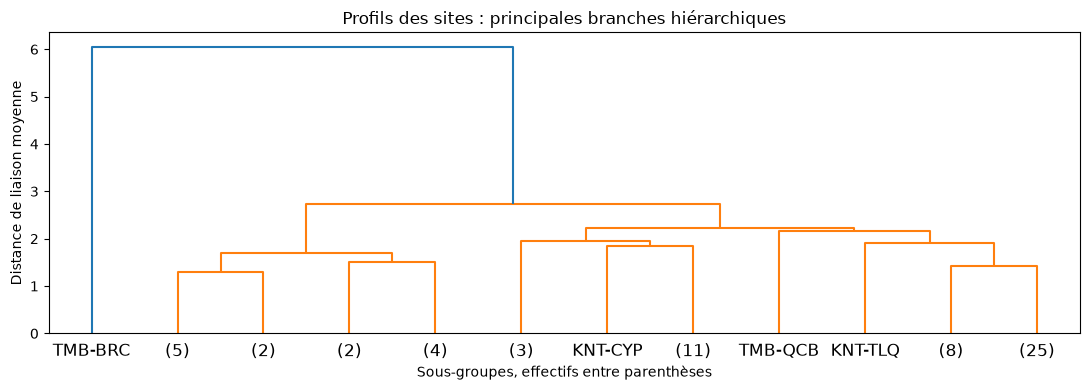

In [29]:
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

distances_manhattan_ecology = pairwise_distances(profils_standardises_ecology, metric='manhattan')
np.fill_diagonal(distances_manhattan_ecology, np.inf)
voisins_manhattan_ecology = profil_sites_ecology.index[np.argmin(distances_manhattan_ecology, axis=1)]
comparaison_voisins_ecology = voisins_sites_ecology.copy()
comparaison_voisins_ecology['voisin_manhattan'] = voisins_manhattan_ecology
comparaison_voisins_ecology['meme_voisin'] = comparaison_voisins_ecology['site_voisin'].eq(comparaison_voisins_ecology['voisin_manhattan'])
print('Même plus proche voisin selon les deux distances :', comparaison_voisins_ecology['meme_voisin'].sum(), 'sur 64')
display(comparaison_voisins_ecology.loc[~comparaison_voisins_ecology['meme_voisin']].head(10))
liaison_sites_ecology = linkage(profils_standardises_ecology.to_numpy(), method='average', metric='euclidean')
comparaison_partitions_ecology = []
for k in [3, 4]:
    labels_kmeans = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(profils_standardises_ecology)
    labels_hierarchie = cut_tree(liaison_sites_ecology, n_clusters=k).ravel()
    for methode, labels in [('kmeans', labels_kmeans), ('hierarchique_moyenne', labels_hierarchie)]:
        tailles = pd.Series(labels).value_counts()
        comparaison_partitions_ecology.append({'methode': methode, 'k': k, 'silhouette': silhouette_score(profils_standardises_ecology, labels), 'plus_petit_groupe': tailles.min(), 'plus_grand_groupe': tailles.max()})
display(pd.DataFrame(comparaison_partitions_ecology).round(3))
fig, axe = plt.subplots(figsize=(11, 4))
dendrogram(liaison_sites_ecology, labels=profil_sites_ecology.index.tolist(), truncate_mode='lastp', p=12, ax=axe, show_leaf_counts=True)
axe.set(title='Profils des sites : principales branches hiérarchiques', xlabel='Sous-groupes, effectifs entre parenthèses', ylabel='Distance de liaison moyenne')
plt.tight_layout()
plt.show()

Le même voisin est retrouvé pour 53 sites sur 64 avec les deux distances : la proximité est assez stable, mais pas universelle. Les silhouettes de K-means pour trois et quatre groupes sont proches (0,377 et 0,380). Le regroupement hiérarchique conserve un singleton et n'améliore pas ce score. Nous ne transformons donc pas le meilleur score en preuve d'un nombre naturel de catégories.

## Cours 3 — Valeurs atypiques et cooccurrences

**Question.** Quels relevés méritent un examen, et quelles conditions accompagnent
une activité faible ? Nous commençons par l'IQR, avec les bornes usuelles
Q1 − 1,5 × IQR et Q3 + 1,5 × IQR. Un seuil global est un repérage descriptif :
il ne tient pas compte de la saison ni de l'habitat. Les observations signalées
ne sont ni supprimées ni considérées automatiquement comme suspectes.

In [30]:
variables_iqr_ecology = ['observations_par_heure', 'detections_acoustiques_par_heure', 'colony_estimate', 'observation_hours', 'weather_interference', 'uptime_pct', 'acoustic_quality']
mesures_iqr_ecology = ecologie_mensuelle[variables_iqr_ecology].astype(float)
q1_ecology = mesures_iqr_ecology.quantile(.25)
q3_ecology = mesures_iqr_ecology.quantile(.75)
iqr_ecology = q3_ecology - q1_ecology
bornes_basses_ecology = q1_ecology - 1.5 * iqr_ecology
bornes_hautes_ecology = q3_ecology + 1.5 * iqr_ecology
flags_iqr_ecology = mesures_iqr_ecology.lt(bornes_basses_ecology) | mesures_iqr_ecology.gt(bornes_hautes_ecology)
display(pd.DataFrame({'borne_basse': bornes_basses_ecology, 'borne_haute': bornes_hautes_ecology, 'nombre_signales': flags_iqr_ecology.sum()}).round(3))
signalements_sites_ecology = ecologie_mensuelle[['site_code', 'mois_releve']].copy()
signalements_sites_ecology['nombre_variables_signalees'] = flags_iqr_ecology.sum(axis=1)
display(signalements_sites_ecology.sort_values('nombre_variables_signalees', ascending=False).head(10))

,borne_basse,borne_haute,nombre_signales
observations_par_heure,-0.168,1.055,149
detections_acoustiques_par_heure,-0.242,1.511,146
colony_estimate,-7.500,37.300,155
observation_hours,16.100,44.900,67
weather_interference,-10.750,84.850,32
uptime_pct,79.550,107.950,182
acoustic_quality,57.813,100.712,82


,site_code,mois_releve,nombre_variables_signalees
2109,AVL-TRP,2019-04,4
1220,KNT-CHP,2023-03,4
1232,KNT-CHP,2024-03,4
624,KNT-CYP,2019-01,3
1244,KNT-CHP,2025-03,3
2114,AVL-TRP,2019-09,3
363,AVL-VEL,2023-04,3
2151,AVL-TRP,2022-10,3
1209,KNT-CHP,2022-04,3
1185,KNT-CHP,2020-04,3


Nous définissons ensuite une transaction comme un site-mois et cinq événements
descriptifs : activité observée sous Q1, pluie au-dessus de Q3, gêne météo au-dessus
de Q3, disponibilité sous Q1 et qualité de relevé limitée. Les quartiles sont
calculés sur l'ensemble du jeu et ne sont pas des seuils écologiques validés.

Avec cinq indicateurs et une question sur les paires, une matrice de cooccurrences
suffit. Nous calculons support, confiance et lift pour distinguer fréquence
et association relative. Aucun Apriori n'est nécessaire pour ces seules paires.

In [31]:
transactions_ecology = pd.DataFrame({
    'activite_faible': ecologie_mensuelle['observations_par_heure'].lt(ecologie_mensuelle['observations_par_heure'].quantile(.25)),
    'pluie_forte': ecologie_mensuelle['rainfall_mm'].gt(ecologie_mensuelle['rainfall_mm'].quantile(.75)),
    'gene_meteo_forte': ecologie_mensuelle['weather_interference'].gt(ecologie_mensuelle['weather_interference'].quantile(.75)),
    'disponibilite_faible': ecologie_mensuelle['uptime_pct'].lt(ecologie_mensuelle['uptime_pct'].quantile(.25)),
    'qualite_limitee': ecologie_mensuelle['survey_quality'].eq('limited')
}).astype(int)
cooccurrences_ecology = transactions_ecology.T.dot(transactions_ecology)
supports_ecology = transactions_ecology.mean()
regles_ecology = []
for antecedent in transactions_ecology.columns:
    for consequent in transactions_ecology.columns:
        if antecedent == consequent:
            continue
        support = cooccurrences_ecology.loc[antecedent, consequent] / len(transactions_ecology)
        confiance = support / supports_ecology[antecedent]
        regles_ecology.append({'antecedent': antecedent, 'consequent': consequent, 'effectif': cooccurrences_ecology.loc[antecedent, consequent], 'support': support, 'confiance': confiance, 'lift': confiance / supports_ecology[consequent]})
regles_ecology = pd.DataFrame(regles_ecology)
display(cooccurrences_ecology)
display(regles_ecology.loc[regles_ecology['consequent'].eq('activite_faible')].sort_values('lift', ascending=False).round(3))

,activite_faible,pluie_forte,gene_meteo_forte,disponibilite_faible,qualite_limitee
activite_faible,1246,320,345,319,35
pluie_forte,320,1247,918,313,34
gene_meteo_forte,345,918,1244,324,39
disponibilite_faible,319,313,324,1241,128
qualite_limitee,35,34,39,128,138


,antecedent,consequent,effectif,support,confiance,lift
8,gene_meteo_forte,activite_faible,345,0.069,0.277,1.111
12,disponibilite_faible,activite_faible,319,0.064,0.257,1.030
4,pluie_forte,activite_faible,320,0.064,0.257,1.028
16,qualite_limitee,activite_faible,35,0.007,0.254,1.016


Les lifts des règles vers « activité faible » vont ici d'environ 1,016 à 1,111.
Ces associations globales sont faibles avec les seuils choisis. Elles ne donnent
pas une explication unique aux faibles comptages. Les bornes basses IQR des indices
d'activité sont négatives : cette règle globale ne peut pas détecter une baisse
restant positive, même si elle est importante pour un site donné.

Un lift supérieur à 1 indique une cooccurrence plus fréquente que sous
l'indépendance des indicateurs, pas un effet causal. Les observations répétées,
les saisons et les seuils choisis limitent cette lecture. Cette étape aide à
conserver des explications ordinaires à un faible comptage. Les changements
propres à un site seront examinés avec une référence saisonnière au cours 5.

### Comparer les repérages univariés et multivariés

Nous confrontons l'IQR au z-score classique, puis comparons Isolation Forest
et LOF sur les 64 profils de sites. Isolation Forest recherche les profils
faciles à isoler globalement. LOF compare leur densité à celle de leurs voisins.
Nous présentons les rangs, sans imposer un pourcentage de sites « suspects ».
Le site KNT-KES peut être important dans un document sans être un profil global
extrême sur six années : les méthodes ne répondent pas à la même question.

In [32]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

z_scores_ecology = (mesures_iqr_ecology - mesures_iqr_ecology.mean()) / mesures_iqr_ecology.std(ddof=0).replace(0, np.nan)
comparaison_univariee_ecology = pd.DataFrame({'IQR': flags_iqr_ecology.sum(), 'z_score_absolu_superieur_3': z_scores_ecology.abs().gt(3).sum()})
display(comparaison_univariee_ecology)
modele_if_ecology = IsolationForest(n_estimators=300, random_state=42, contamination='auto')
modele_if_ecology.fit(profils_standardises_ecology)
modele_lof_ecology = LocalOutlierFactor(n_neighbors=10, contamination='auto')
modele_lof_ecology.fit_predict(profils_standardises_ecology)
rangs_anomalies_sites_ecology = pd.DataFrame({
    'score_isolement': -modele_if_ecology.score_samples(profils_standardises_ecology),
    'facteur_lof': -modele_lof_ecology.negative_outlier_factor_
}, index=profil_sites_ecology.index)
rangs_anomalies_sites_ecology['rang_isolement'] = rangs_anomalies_sites_ecology['score_isolement'].rank(ascending=False, method='min').astype(int)
rangs_anomalies_sites_ecology['rang_lof'] = rangs_anomalies_sites_ecology['facteur_lof'].rank(ascending=False, method='min').astype(int)
display(rangs_anomalies_sites_ecology.sort_values('rang_isolement').head(10).round(3))
print('Comparaison de deux sites retenus pour des raisons différentes :')
display(rangs_anomalies_sites_ecology.loc[['KNT-KES', 'TMB-BRC']].round(3))
# Vérifier que le rang local ne repose pas sur un seul choix du voisinage.
sensibilite_lof_ecology = []
for nombre_voisins in [5, 10, 15]:
    modele = LocalOutlierFactor(n_neighbors=nombre_voisins)
    modele.fit_predict(profils_standardises_ecology)
    rangs = pd.Series(-modele.negative_outlier_factor_, index=profil_sites_ecology.index).rank(ascending=False, method='min')
    sensibilite_lof_ecology.append({'voisins': nombre_voisins, 'rang_KNT_KES': rangs.loc['KNT-KES'], 'rang_TMB_BRC': rangs.loc['TMB-BRC']})
display(pd.DataFrame(sensibilite_lof_ecology))

,IQR,z_score_absolu_superieur_3
observations_par_heure,149,69
detections_acoustiques_par_heure,146,75
colony_estimate,155,71
observation_hours,67,32
weather_interference,32,26
uptime_pct,182,122
acoustic_quality,82,41


,score_isolement,facteur_lof,rang_isolement,rang_lof
site_code,,,,
TMB-BRC,0.757,3.244,1,1
KNT-GGN,0.656,1.350,2,9
KNT-CYP,0.602,1.416,3,6
TMB-QCB,0.577,2.101,4,2
AVL-YAU,0.567,1.184,5,21
AVL-TRP,0.562,1.303,6,10
AVL-GRB,0.547,1.227,7,16
KNT-YRG,0.546,1.184,8,22
AVL-HUA,0.540,1.241,9,11


Comparaison de deux sites retenus pour des raisons différentes :


,score_isolement,facteur_lof,rang_isolement,rang_lof
site_code,,,,
KNT-KES,0.509,1.139,13,28
TMB-BRC,0.757,3.244,1,1


,voisins,rang_KNT_KES,rang_TMB_BRC
0,5,8.0,1.0
1,10,28.0,1.0
2,15,19.0,1.0


TMB-BRC arrive en tête d'Isolation Forest et de LOF ; c'est surtout un site d'activité élevée. KNT-KES est seulement 13e pour l'isolement et 28e pour LOF avec dix voisins ; son rang LOF varie de 8 à 28 avec le voisinage. Sa priorité vient du contexte documentaire et d'épisodes datés, pas d'une anomalie globale indiscutable. Les moyennes de six ans peuvent masquer une baisse de quelques mois.

## Cours 4 — Réseau des sites et des prestataires de maintenance

**Question.** Les opérations enregistrées révèlent-elles des liens particuliers
entre sites et prestataires ? Nous construisons un graphe biparti non orienté :
un nœud représente un site ou un prestataire, et un lien signifie qu'au moins
une opération associe les deux. Son poids est le nombre d'opérations.

Ce réseau décrit des associations administratives. Il ne représente ni un trajet
de transport ni le déplacement de chauves-souris. Les prestataires manquants
ne sont pas regroupés en un faux acteur commun. Nous ne fabriquons pas de
processus à partir de relevés mensuels qui ne sont pas des tâches successives.

Nœuds / liens : 68 64
Composantes connexes : 4


,nombre_sites,nombre_operations
maintenance_provider,,
ECO-SERVICE-1,16,1241
ECO-SERVICE-2,16,1242
ECO-SERVICE-3,16,1239
ECO-SERVICE-4,16,1240


,site_code,maintenance_provider,nombre_operations
30,KNT-KES,ECO-SERVICE-2,78


maintenance_provider,ECO-SERVICE-1,ECO-SERVICE-2,ECO-SERVICE-3,ECO-SERVICE-4
region,,,,
Eastern Avelora Agricultural Cluster,465,467,467,310
Kintara Karst Cluster,310,465,463,467
Tembara Coastal Cluster,466,310,309,463


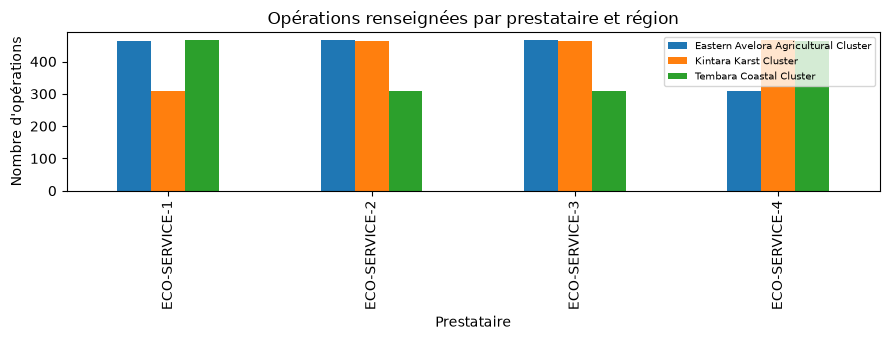

In [33]:
import networkx as nx

liens_maintenance_ecology = df_appareils.dropna(subset=['maintenance_provider']).groupby(['site_code', 'maintenance_provider']).size().rename('nombre_operations').reset_index()
graphe_maintenance_ecology = nx.Graph()
for ligne in liens_maintenance_ecology.itertuples(index=False):
    site = 'site:' + ligne.site_code
    prestataire = 'prestataire:' + ligne.maintenance_provider
    graphe_maintenance_ecology.add_node(site, type_noeud='site')
    graphe_maintenance_ecology.add_node(prestataire, type_noeud='prestataire')
    graphe_maintenance_ecology.add_edge(site, prestataire, weight=int(ligne.nombre_operations))
resume_prestataires_ecology = liens_maintenance_ecology.groupby('maintenance_provider').agg(nombre_sites=('site_code', 'nunique'), nombre_operations=('nombre_operations', 'sum'))
print('Nœuds / liens :', graphe_maintenance_ecology.number_of_nodes(), graphe_maintenance_ecology.number_of_edges())
print('Composantes connexes :', nx.number_connected_components(graphe_maintenance_ecology))
display(resume_prestataires_ecology)
display(liens_maintenance_ecology.loc[liens_maintenance_ecology['site_code'].eq('KNT-KES')])
# Vue agrégée lisible : le graphe complet reste disponible dans la variable ci-dessus.
maintenance_regions_ecology = liens_maintenance_ecology.merge(df_sites[['site_code', 'region']], on='site_code', validate='many_to_one')
matrice_regions_ecology = maintenance_regions_ecology.pivot_table(index='region', columns='maintenance_provider', values='nombre_operations', aggfunc='sum', fill_value=0)
display(matrice_regions_ecology)
fig, axe = plt.subplots(figsize=(9, 3.5))
matrice_regions_ecology.T.plot.bar(ax=axe)
axe.set(title='Opérations renseignées par prestataire et région', ylabel="Nombre d'opérations", xlabel='Prestataire')
axe.legend(fontsize=7)
plt.tight_layout()
plt.show()

Le graphe comporte 68 nœuds et 64 liens, répartis en quatre composantes : chaque
prestataire renseigné couvre 16 sites. KNT-KES est relié à ECO-SERVICE-2 pour
78 opérations. Cette organisation régulière ne permet pas d'identifier un
prestataire particulièrement associé à une opération suspecte.

Le degré d'un prestataire compte les sites reliés, alors que la somme des poids
compte ses opérations. Une couverture régulière ou étendue ne constitue pas
un indice de transport clandestin. Les codes `ECO-SERVICE-*` sont internes à
Ecology : aucun rapprochement avec une entreprise externe ne sera affirmé
sans table de correspondance. Les degrés et les composantes suffisent ici,
sans ajouter un algorithme de communautés à un petit réseau biparti.

### Processus réels d'accès aux sites, à partir de Public Records

Les relevés mensuels ne sont pas un journal de tâches, mais les demandes d'accès
en sont un. Pour les sites Ecology présents dans ce registre, un cas est une
demande d'accès et un événement est une activité administrative datée.
Nous utilisons les identifiants et conservons les étapes absentes telles quelles.
L'absence d'une étape enregistrée ne prouve pas qu'une obligation a été contournée.

,nombre_cas
sequence,
"(request_submitted, technical_review, wildlife_review, authorization_granted, access_started, access_completed, closure_recorded)",28
"(request_submitted, technical_review, authorization_granted, access_started, access_completed, closure_recorded)",12
"(request_submitted, technical_review, wildlife_review, security_review, authorization_granted, access_started, access_completed, closure_recorded)",11
"(request_submitted, technical_review, wildlife_review, authorization_denied, closure_recorded)",4
"(request_submitted, technical_review, authorization_denied, closure_recorded)",2
"(request_submitted, technical_review, wildlife_review, authorization_denied, request_submitted, authorization_granted, access_started, access_completed, closure_recorded)",2
"(request_submitted, technical_review, wildlife_review, security_review, authorization_denied, request_submitted, authorization_granted, access_started, access_completed, closure_recorded)",1


,source,destination,effectif
0,DEBUT,request_submitted,60
1,request_submitted,technical_review,60
7,closure_recorded,FIN,60
5,access_started,access_completed,54
4,authorization_granted,access_started,54
6,access_completed,closure_recorded,54
2,technical_review,wildlife_review,46
3,wildlife_review,authorization_granted,28
8,technical_review,authorization_granted,12
9,wildlife_review,security_review,12


,site,debut,fin,nombre_evenements,confidentialite,duree_jours,security_review_enregistree
access_case_number,,,,,,,
ACC-2018-0002,KNT-KES,2018-02-19 09:00:00,2018-03-25 11:00:00,8,confidential,34.083333,True
ACC-2021-0009,KNT-KES,2021-02-22 09:00:00,2021-03-28 11:00:00,8,standard,34.083333,True
ACC-2024-0014,KNT-KES,2024-02-19 09:00:00,2024-03-24 11:00:00,7,restricted,34.083333,False


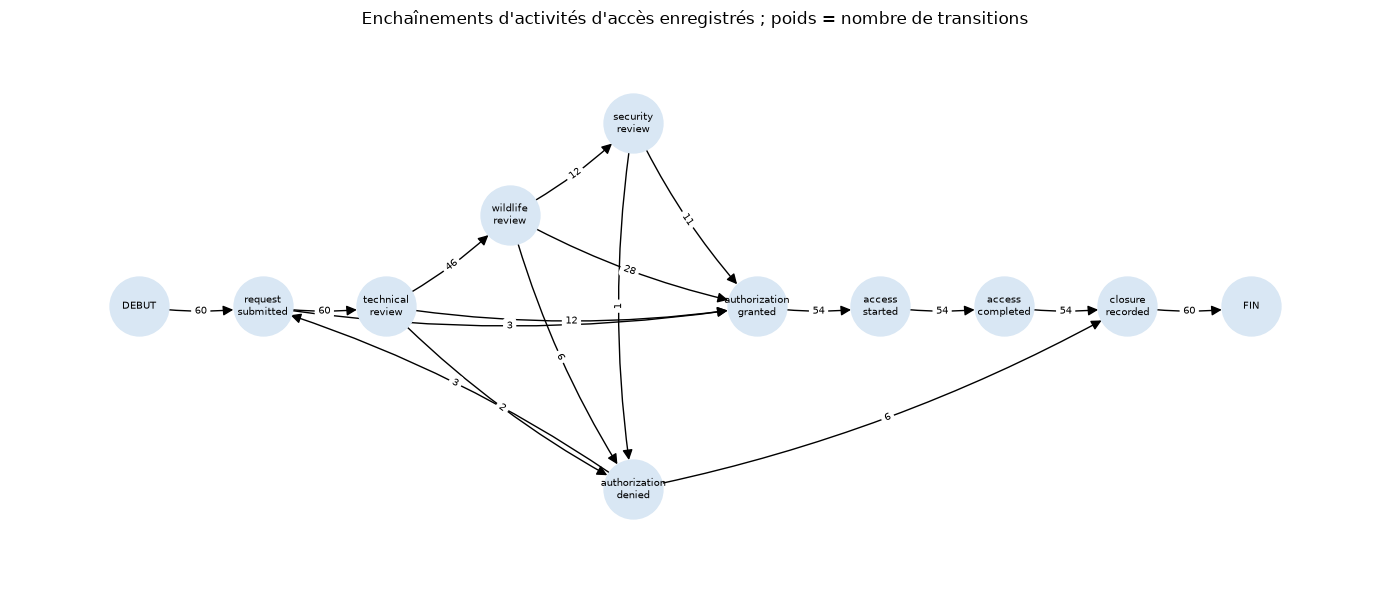

In [34]:
from collections import Counter

journal_acces_ecology = pd.read_csv('data/public_records/site_access_case_events.csv').drop_duplicates()
journal_acces_ecology = journal_acces_ecology.loc[journal_acces_ecology['site_code'].isin(df_sites['site_code'])].copy()
journal_acces_ecology['event_time'] = dates_heures_ecology(journal_acces_ecology['event_time'])
for colonne in ['activity', 'previous_status', 'new_status', 'confidentiality_class']:
    journal_acces_ecology[colonne] = categorie_ecology(journal_acces_ecology[colonne])
assert journal_acces_ecology['access_event_id'].is_unique
journal_acces_ecology = journal_acces_ecology.sort_values(['access_case_number', 'event_time', 'access_event_id'])
variantes_acces_ecology = journal_acces_ecology.groupby('access_case_number')['activity'].agg(tuple)
display(variantes_acces_ecology.value_counts().rename_axis('sequence').to_frame('nombre_cas'))
transitions_acces_ecology = Counter()
for sequence in variantes_acces_ecology:
    parcours = ('DEBUT',) + sequence + ('FIN',)
    transitions_acces_ecology.update(zip(parcours[:-1], parcours[1:]))
graphe_acces_ecology = nx.DiGraph()
for (source, destination), poids in transitions_acces_ecology.items():
    graphe_acces_ecology.add_edge(source, destination, weight=poids)
table_transitions_acces_ecology = pd.DataFrame([{'source': u, 'destination': v, 'effectif': w} for (u,v),w in transitions_acces_ecology.items()]).sort_values('effectif', ascending=False)
display(table_transitions_acces_ecology.head(12))
resume_cas_acces_ecology = journal_acces_ecology.groupby('access_case_number').agg(site=('site_code', 'first'), debut=('event_time', 'min'), fin=('event_time', 'max'), nombre_evenements=('access_event_id', 'size'), confidentialite=('confidentiality_class', 'first'))
resume_cas_acces_ecology['duree_jours'] = (resume_cas_acces_ecology['fin'] - resume_cas_acces_ecology['debut']).dt.total_seconds() / 86400
resume_cas_acces_ecology['security_review_enregistree'] = variantes_acces_ecology.map(lambda sequence: 'security_review' in sequence)
display(resume_cas_acces_ecology.loc[resume_cas_acces_ecology['site'].eq('KNT-KES')])
fig, axe = plt.subplots(figsize=(14, 6))
positions = {'DEBUT': (0, 1), 'request_submitted': (1.5, 1), 'technical_review': (3, 1),
             'wildlife_review': (4.5, 2), 'security_review': (6, 3),
             'authorization_granted': (7.5, 1), 'access_started': (9, 1),
             'access_completed': (10.5, 1), 'closure_recorded': (12, 1),
             'FIN': (13.5, 1), 'authorization_denied': (6, -1)}
nx.draw_networkx_nodes(graphe_acces_ecology, pos=positions, ax=axe, node_size=1800, node_color='#d9e7f4')
nx.draw_networkx_labels(graphe_acces_ecology, pos=positions, ax=axe, font_size=7,
                        labels={n: n.replace('_', '\n') for n in graphe_acces_ecology})
nx.draw_networkx_edges(graphe_acces_ecology, pos=positions, ax=axe, node_size=1800, arrowsize=15,
                      connectionstyle='arc3,rad=0.08')
nx.draw_networkx_edge_labels(graphe_acces_ecology, pos=positions, edge_labels=nx.get_edge_attributes(graphe_acces_ecology, 'weight'), font_size=7, ax=axe, connectionstyle='arc3,rad=0.08')
axe.margins(.06, .18)
axe.set_title("Enchaînements d'activités d'accès enregistrés ; poids = nombre de transitions")
axe.axis('off')
plt.tight_layout()
plt.show()

La mesure de dépendance du Heuristic Miner compare les transitions dans les deux
sens : (effectif A→B − effectif B→A) / (effectif A→B + effectif B→A + 1).
Nous calculons cette mesure pour décrire les liens principaux, sans prétendre
implémenter un outil complet de process mining. Elle ne transforme pas une
succession administrative en preuve de transport matériel.

In [35]:
dependances_acces_ecology = table_transitions_acces_ecology.copy()
dependances_acces_ecology['effectif_inverse'] = [transitions_acces_ecology.get((ligne.destination, ligne.source), 0) for ligne in dependances_acces_ecology.itertuples(index=False)]
dependances_acces_ecology['dependance'] = (dependances_acces_ecology['effectif'] - dependances_acces_ecology['effectif_inverse']) / (dependances_acces_ecology['effectif'] + dependances_acces_ecology['effectif_inverse'] + 1)
display(dependances_acces_ecology.sort_values('dependance', ascending=False).head(12).round(3))

,source,destination,effectif,effectif_inverse,dependance
0,DEBUT,request_submitted,60,0,0.984
1,request_submitted,technical_review,60,0,0.984
7,closure_recorded,FIN,60,0,0.984
5,access_started,access_completed,54,0,0.982
4,authorization_granted,access_started,54,0,0.982
6,access_completed,closure_recorded,54,0,0.982
2,technical_review,wildlife_review,46,0,0.979
3,wildlife_review,authorization_granted,28,0,0.966
8,technical_review,authorization_granted,12,0,0.923
9,wildlife_review,security_review,12,0,0.923


Après harmonisation, les 412 événements décrivent 60 demandes et sept variantes. Cinquante-quatre cas comportent un accès réalisé et six se terminent après un refus ; trois parcours comprennent un refus suivi d'une nouvelle demande et d'une autorisation. KNT-KES a une étape `security_review` en 2018 et 2021, mais pas en 2024. Cette absence n'est ni unique dans le registre ni une preuve d'irrégularité réglementaire. Les dépendances fortes décrivent surtout la séquence administrative attendue.

## Cours 5 — Évolution temporelle, saisonnalité et examen local

**Question.** Une baisse locale dépasse-t-elle les variations habituelles ?
Nous reprenons d'abord les médianes régionales, puis l'autocorrélation et une
décomposition additive classique à période 12. Ces séries sont mensuelles,
régulières et comportent plus de deux années. Une périodicité apparente n'est
pas une cause identifiée. La décomposition est rétrospective, pas une prévision.
Nous n'utilisons pas STL, SARIMA ou Prophet, seulement mentionnés comme pistes
complémentaires dans le support.

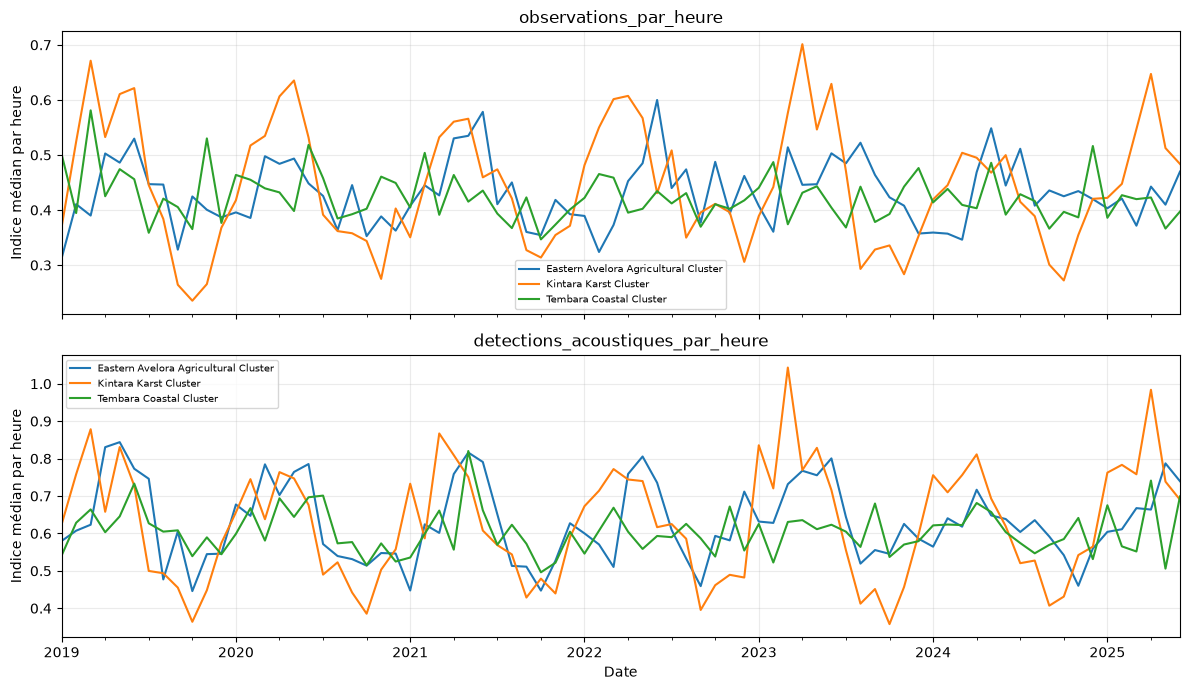

Autocorrélation aux retards 1, 6, 12 et 24 mois :


1     0.708
6    -0.763
12    0.746
24    0.735
Name: autocorrelation, dtype: float64

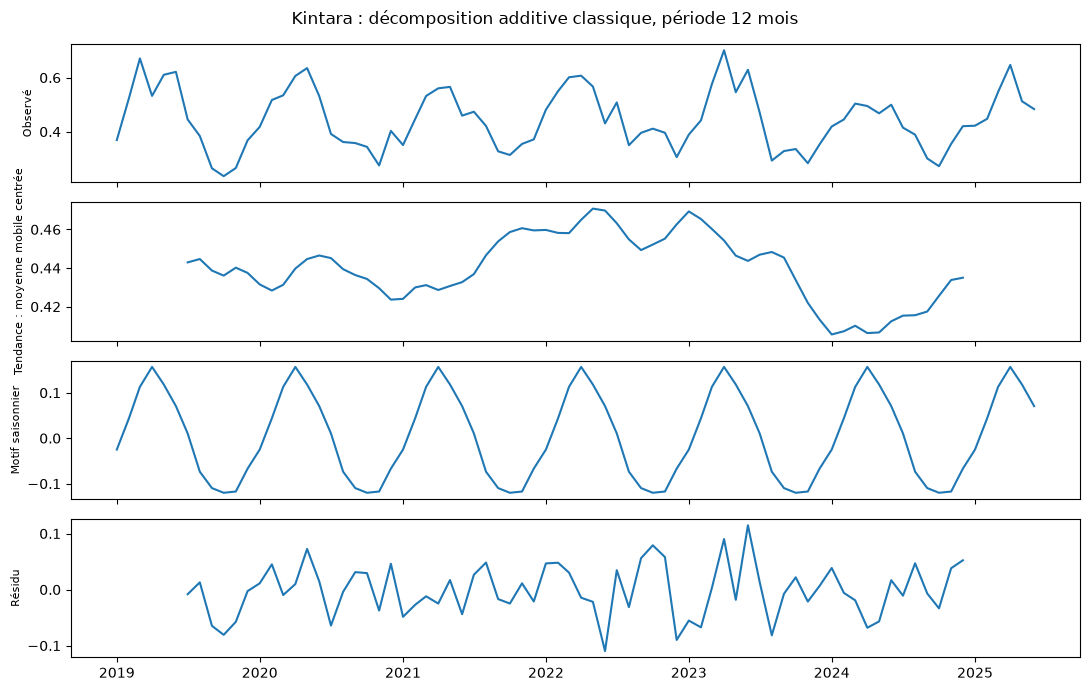

In [36]:
evolution_mensuelle_bats = ecologie_mensuelle.groupby(['mois_releve', 'region'])[['observations_par_heure', 'detections_acoustiques_par_heure']].median()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for axe, variable in zip(axes, ['observations_par_heure', 'detections_acoustiques_par_heure']):
    tableau = evolution_mensuelle_bats[variable].unstack('region')
    tableau.index = tableau.index.to_timestamp()
    tableau.plot(ax=axe)
    axe.set_ylabel('Indice médian par heure')
    axe.set_title(variable)
    axe.set_xlabel('')
    axe.legend(fontsize=7)
    axe.grid(alpha=.25)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

serie_kintara_ecology = evolution_mensuelle_bats.xs('Kintara Karst Cluster', level='region')['observations_par_heure'].astype(float)
serie_kintara_ecology.index = serie_kintara_ecology.index.to_timestamp()
autocorrelations_ecology = pd.Series({retard: serie_kintara_ecology.autocorr(lag=retard) for retard in range(1, 25)}, name='autocorrelation')
print('Autocorrélation aux retards 1, 6, 12 et 24 mois :')
display(autocorrelations_ecology.loc[[1, 6, 12, 24]].round(3))
# Moyenne mobile centrée 2 x 12, adaptée à une période paire.
moyenne_mobile_ecology = serie_kintara_ecology.rolling(12, center=True).mean()
tendance_kintara_ecology = (moyenne_mobile_ecology + moyenne_mobile_ecology.shift(-1)) / 2
sans_tendance_ecology = serie_kintara_ecology - tendance_kintara_ecology
motif_mensuel_ecology = sans_tendance_ecology.groupby(sans_tendance_ecology.index.month).mean()
motif_mensuel_ecology = motif_mensuel_ecology - motif_mensuel_ecology.mean()
saison_kintara_ecology = pd.Series(serie_kintara_ecology.index.month.map(motif_mensuel_ecology), index=serie_kintara_ecology.index)
residu_kintara_ecology = serie_kintara_ecology - tendance_kintara_ecology - saison_kintara_ecology
assert np.allclose((tendance_kintara_ecology + saison_kintara_ecology + residu_kintara_ecology).dropna(), serie_kintara_ecology.loc[residu_kintara_ecology.notna()])
fig, axes = plt.subplots(4, 1, figsize=(11, 7), sharex=True)
for axe, serie, titre in zip(axes, [serie_kintara_ecology, tendance_kintara_ecology, saison_kintara_ecology, residu_kintara_ecology], ['Observé', 'Tendance : moyenne mobile centrée', 'Motif saisonnier', 'Résidu']):
    axe.plot(serie.index, serie)
    axe.set_ylabel(titre, fontsize=8)
fig.suptitle('Kintara : décomposition additive classique, période 12 mois')
plt.tight_layout()
plt.show()

L'autocorrélation de Kintara est positive à 12 mois (≈ 0,746) et à 24 mois
(≈ 0,735), et négative à 6 mois (≈ −0,763). Cela étaye une variation annuelle
dans cette série agrégée. La décomposition sépare un motif récurrent de la
tendance et des écarts résiduels. La moyenne mobile centrée laisse les extrémités
sans tendance ni résidu : ces valeurs absentes ne sont pas remplacées par zéro.

### Étude de KNT-KES et choix des références

Le choix de ce site est motivé par le rapport `EFR-510088`, lu lors de
l'exploration documentaire, et non par une sélection automatique aveugle.
Le rapport parle d'un accès en mars 2024 et d'une baisse ultérieure.
Cette piste sera évaluée plutôt que considérée comme vraie.

Nous prenons 2019–2023 comme référence antérieure à cet événement et comparons
chaque mois au même mois calendaire de ces cinq années. Une référence de cinq
valeurs par mois reste limitée. Les sites de comparaison sont choisis dans le
même habitat et la même région, sur leurs conditions environnementales médianes
avant 2024, et non parce que leurs courbes donnent le résultat attendu.

Sites de comparaison et distances environnementales standardisées :


,distance
site_code,
KNT-NNM,1.326499
KNT-CHP,1.488420
KNT-JAK,1.878428


Références nulles : ratios laissés manquants, pas remplacés par zéro.


,references_nulles
observations_par_heure_reference,0
detections_acoustiques_par_heure_reference,0
colony_estimate_reference,0
comparison_species_count_reference,0


,mois_releve,observations_par_heure,observations_par_heure_reference,observations_par_heure_ratio,detections_acoustiques_par_heure_ratio,uptime_pct,acoustic_quality,weather_interference
62,2024-03,0.502,0.752,0.667,0.968,88.7,77.8,21.5
63,2024-04,0.334,0.728,0.459,0.497,83.1,73.1,29.9
64,2024-05,0.111,0.719,0.154,0.489,91.8,71.4,47.0
65,2024-06,0.49,0.894,0.548,0.22,100.0,65.7,54.1
66,2024-07,0.367,0.645,0.568,0.375,88.3,79.6,48.9
67,2024-08,0.249,0.449,0.554,1.609,91.8,85.3,56.8


Conditions du site ciblé et médianes du même mois avant 2024 :


,mois_releve,mois_calendaire,observation_hours,rainfall_mm,habitat_disturbance_index,pesticide_index,uptime_pct,acoustic_quality,comparison_species_count_ratio,survey_method,survey_quality,observation_hours_reference,rainfall_mm_reference,habitat_disturbance_index_reference,pesticide_index_reference,uptime_pct_reference,acoustic_quality_reference
0,2024-03,3,31.9,118.4,26.3,27.4,88.7,77.8,1.800000,acoustic_transect,acceptable,33.8,111.2,24.6,19.6,94.9,82.5
1,2024-04,4,29.9,140.6,7.9,19.4,83.1,73.1,1.181818,acoustic_and_visual,acceptable,35.7,148.1,19.0,21.7,95.4,79.4
2,2024-05,5,27.1,246.2,17.7,36.8,91.8,71.4,1.000000,acoustic_and_visual,acceptable,32.7,209.6,20.3,24.8,87.7,77.9
3,2024-06,6,28.6,231.3,24.9,31.8,100.0,65.7,0.769231,acoustic_and_visual,acceptable,27.0,203.1,19.2,17.7,94.7,76.2
4,2024-07,7,30.0,240.0,13.4,24.8,88.3,79.6,1.600000,fixed_acoustic_station,high,27.2,257.5,24.8,31.7,97.7,80.0
5,2024-08,8,20.1,252.8,16.1,21.1,91.8,85.3,0.923077,acoustic_and_visual,high,25.6,239.8,20.4,16.0,91.4,74.9


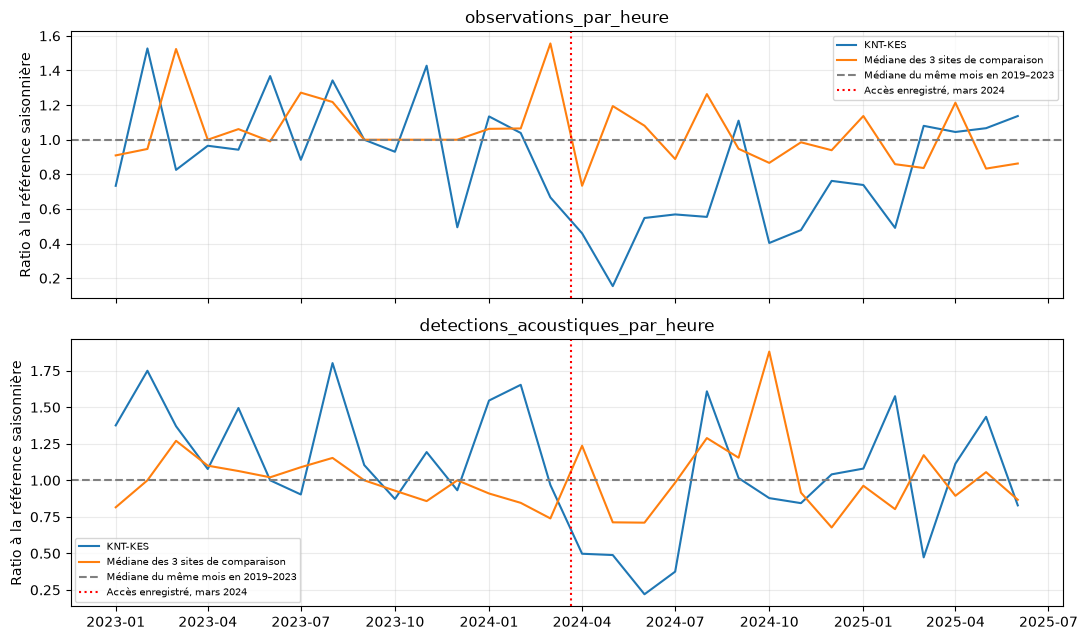

In [37]:
site_cible_ecology = 'KNT-KES'
avant_ecology = ecologie_mensuelle['survey_start'].lt('2024-01-01')
conditions_reference_ecology = ['mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct', 'vegetation_cover_pct']
contexte_cible_ecology = df_sites.set_index('site_code').loc[site_cible_ecology]
candidats_reference_ecology = df_sites.loc[df_sites['region'].eq(contexte_cible_ecology['region']) & df_sites['habitat_category'].eq(contexte_cible_ecology['habitat_category']), 'site_code']
environnement_reference_ecology = ecologie_mensuelle.loc[avant_ecology & ecologie_mensuelle['site_code'].isin(candidats_reference_ecology)].groupby('site_code')[conditions_reference_ecology].median()
reference_standardisee_ecology = StandardScaler().fit_transform(environnement_reference_ecology)
position_cible_ecology = environnement_reference_ecology.index.get_loc(site_cible_ecology)
distances_reference_ecology = pd.Series(pairwise_distances(reference_standardisee_ecology[[position_cible_ecology]], reference_standardisee_ecology)[0], index=environnement_reference_ecology.index).drop(site_cible_ecology).sort_values()
sites_reference_ecology = distances_reference_ecology.head(3).index.tolist()
print('Sites de comparaison et distances environnementales standardisées :')
display(distances_reference_ecology.head(3).to_frame('distance'))

ecologie_mensuelle['mois_calendaire'] = ecologie_mensuelle['survey_start'].dt.month
variables_saison_ecology = ['observations_par_heure', 'detections_acoustiques_par_heure', 'colony_estimate', 'comparison_species_count']
references_saisonnieres_ecology = ecologie_mensuelle.loc[avant_ecology].groupby(['site_code', 'mois_calendaire'])[variables_saison_ecology].median().add_suffix('_reference')
comparaison_saison_ecology = ecologie_mensuelle.merge(references_saisonnieres_ecology, on=['site_code', 'mois_calendaire'], how='left', validate='many_to_one')
for variable in variables_saison_ecology:
    denominateur = comparaison_saison_ecology[variable + '_reference'].replace(0, np.nan)
    comparaison_saison_ecology[variable + '_ratio'] = comparaison_saison_ecology[variable] / denominateur
print('Références nulles : ratios laissés manquants, pas remplacés par zéro.')
display((references_saisonnieres_ecology == 0).sum().to_frame('references_nulles'))
cible_temporelle_ecology = comparaison_saison_ecology.loc[comparaison_saison_ecology['site_code'].eq(site_cible_ecology)].sort_values('mois_releve')
resume_cible_2024_ecology = cible_temporelle_ecology.loc[cible_temporelle_ecology['survey_start'].between('2024-03-01', '2024-08-31')]
colonnes_cible_ecology = ['mois_releve', 'observations_par_heure', 'observations_par_heure_reference', 'observations_par_heure_ratio', 'detections_acoustiques_par_heure_ratio', 'uptime_pct', 'acoustic_quality', 'weather_interference']
tableau_cible_ecology = resume_cible_2024_ecology[colonnes_cible_ecology].copy()
tableau_cible_ecology['mois_releve'] = tableau_cible_ecology['mois_releve'].astype(str)
display(tableau_cible_ecology.round(3))
conditions_cible_ecology = ['observation_hours', 'rainfall_mm', 'habitat_disturbance_index', 'pesticide_index', 'uptime_pct', 'acoustic_quality']
reference_conditions_cible_ecology = ecologie_mensuelle.loc[avant_ecology & ecologie_mensuelle['site_code'].eq(site_cible_ecology)].groupby('mois_calendaire')[conditions_cible_ecology].median().add_suffix('_reference')
controle_conditions_cible_ecology = resume_cible_2024_ecology[['mois_releve', 'mois_calendaire'] + conditions_cible_ecology + ['comparison_species_count_ratio', 'survey_method', 'survey_quality']].merge(reference_conditions_cible_ecology, on='mois_calendaire', how='left', validate='many_to_one')
print('Conditions du site ciblé et médianes du même mois avant 2024 :')
display(controle_conditions_cible_ecology)
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for axe, variable in zip(axes, ['observations_par_heure', 'detections_acoustiques_par_heure']):
    cible = cible_temporelle_ecology.loc[cible_temporelle_ecology['survey_start'].ge('2023-01-01')]
    reference = comparaison_saison_ecology.loc[comparaison_saison_ecology['site_code'].isin(sites_reference_ecology) & comparaison_saison_ecology['survey_start'].ge('2023-01-01')].groupby('mois_releve')[variable + '_ratio'].median()
    axe.plot(cible['mois_releve'].dt.to_timestamp(), cible[variable + '_ratio'], label='KNT-KES')
    axe.plot(reference.index.to_timestamp(), reference, label='Médiane des 3 sites de comparaison')
    axe.axhline(1, color='grey', linestyle='--', label='Médiane du même mois en 2019–2023')
    axe.axvline(pd.Timestamp('2024-03-21'), color='red', linestyle=':', label='Accès enregistré, mars 2024')
    axe.set_ylabel('Ratio à la référence saisonnière')
    axe.set_title(variable)
    axe.legend(fontsize=7)
    axe.grid(alpha=.25)
plt.tight_layout()
plt.show()

Pour KNT-KES, l'indice observé d'avril 2024 vaut environ 46 % de sa médiane
des mois d'avril 2019–2023. Celui de mai vaut environ 15 %. Les détections
acoustiques d'avril et mai représentent près de la moitié de leurs références.
Cette baisse mérite donc un examen local. Les références retenues sont KNT-NNM,
KNT-CHP et KNT-JAK. Elles ne constituent pas un groupe témoin expérimental.

La baisse n'apparaît pas exclusivement après l'accès : le relevé du 5 au 12 mars
est déjà sous sa référence observée (≈ 67 %), avant l'accès du 21 mars.
Les indices observés et acoustiques ne restent pas non plus synchrones :
l'acoustique remonte au-dessus de sa référence en août 2024, contrairement
aux observations. La qualité acoustique et la disponibilité sont variables.
Ces éléments empêchent d'attribuer toute l'évolution à l'accès de mars.
Nous comparons aussi les conditions à leurs références saisonnières. Nous ne
divisons pas les détections par la disponibilité ou la qualité pour prétendre
les corriger : aucune calibration ne permet ici une telle correction.

### Repérage local et sensibilité aux fenêtres

Nous complétons les comparaisons saisonnières par l'approche simple de fenêtre
glissante du cours 5. Pour chaque site, la référence contient les 12 mois précédents,
sans inclure le mois évalué. L'IQR signale les écarts à cette fenêtre. Cette règle
reste sensible aux saisons et ne remplace pas la comparaison calendaire précédente.
Le repérage est également recalculé sur 24 mois pour vérifier sa sensibilité.

,signalements_12_mois,signalements_24_mois
site_code,,
KNT-QWU,11,8
AVL-ORR,9,3
TMB-HVD,8,2
KNT-KES,8,2
TMB-SKZ,8,1
KNT-YRG,7,4
AVL-SEY,7,4
TMB-NAC,7,4
TMB-SXP,7,3


KNT-KES :


,signalements_12_mois,signalements_24_mois
site_code,,
KNT-KES,8,2


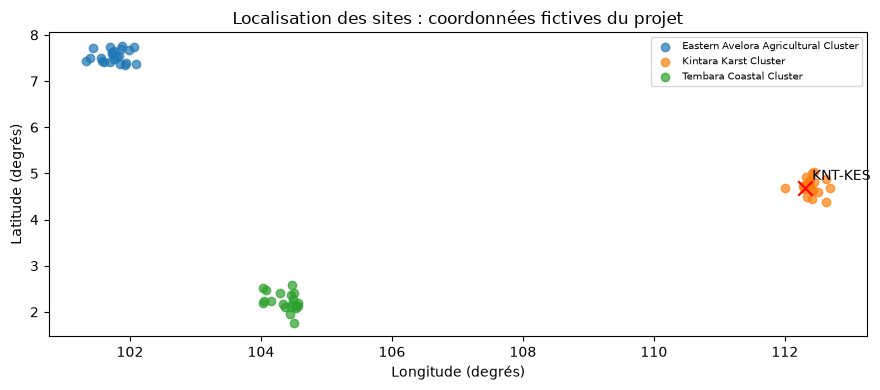

In [38]:
series_sites_ecology = ecologie_mensuelle.pivot(index='mois_releve', columns='site_code', values='observations_par_heure').sort_index().astype(float)
flags_fenetres_ecology = {}
for fenetre in [12, 24]:
    precedent = series_sites_ecology.shift(1)
    q1_local = precedent.rolling(fenetre, min_periods=fenetre).quantile(.25)
    q3_local = precedent.rolling(fenetre, min_periods=fenetre).quantile(.75)
    bas_local = q1_local - 1.5 * (q3_local - q1_local)
    haut_local = q3_local + 1.5 * (q3_local - q1_local)
    flags_fenetres_ecology[fenetre] = (series_sites_ecology.lt(bas_local) | series_sites_ecology.gt(haut_local)).where(q1_local.notna())
resume_fenetres_ecology = pd.DataFrame({f'signalements_{f}_mois': indicateurs.sum().astype(int) for f, indicateurs in flags_fenetres_ecology.items()})
display(resume_fenetres_ecology.sort_values('signalements_12_mois', ascending=False).head(10))
print('KNT-KES :')
display(resume_fenetres_ecology.loc[[site_cible_ecology]])
fig, axe = plt.subplots(figsize=(9, 4))
for region, groupe in df_sites.groupby('region'):
    axe.scatter(groupe['longitude'], groupe['latitude'], label=region, alpha=.7)
cible_site_ecology = df_sites.loc[df_sites['site_code'].eq(site_cible_ecology)].iloc[0]
axe.scatter([cible_site_ecology['longitude']], [cible_site_ecology['latitude']], marker='x', s=110, color='red')
axe.annotate(site_cible_ecology, (cible_site_ecology['longitude'], cible_site_ecology['latitude']), xytext=(5, 6), textcoords='offset points')
axe.set(xlabel='Longitude (degrés)', ylabel='Latitude (degrés)', title='Localisation des sites : coordonnées fictives du projet')
axe.legend(fontsize=7)
plt.tight_layout()
plt.show()

Le graphique régional peut masquer un changement local. Inversement, une baisse
locale ne constitue pas une preuve de prélèvement. Il faut confronter les indices
aux appareils, à la météo et aux documents. Une absence de signalement par l'IQR
ne prouve pas non plus l'absence d'un événement : les distributions de comptage
et les saisons peuvent rendre la borne basse peu informative.
La carte sert à situer les sites, sans calculer de distances métriques sur des degrés.
KNT-KES est signalé 8 fois avec la fenêtre de 12 mois et 2 fois avec 24 mois :
le résultat dépend donc de la référence choisie. Ce site n'est pas le premier
du classement global des signalements. Nous ne présentons pas le rapport ciblé
comme la découverte inévitable de la méthode statistique.

### Recherche systématique de baisses après retrait du motif calendaire

Le rapport attire l'attention sur KNT-KES, mais nous vérifions aussi les autres
sites. La référence reste fixée avant 2024. Pour chaque site et chaque mois,
nous soustrayons la médiane du même mois en 2019–2023, puis rapportons cet écart
à l'écart-type des résidus antérieurs du site. Ce score est descriptif et ne
constitue pas une probabilité. Les mêmes 60 observations servent à estimer
les 12 médianes : les seuils restent exploratoires et leur incertitude est réelle.

Nous présentons aussi une règle lisible sans score : un indice inférieur à
la moitié de sa référence calendaire. Les événements sont des mois consécutifs,
pas des nombres d'animaux prélevés. La règle n'identifie pas une cause.

In [39]:
suivi_desaisonnalise_ecology = comparaison_saison_ecology.copy()
suivi_desaisonnalise_ecology['residu_observe'] = suivi_desaisonnalise_ecology['observations_par_heure'] - suivi_desaisonnalise_ecology['observations_par_heure_reference']
stats_residus_avant_ecology = suivi_desaisonnalise_ecology.loc[suivi_desaisonnalise_ecology['survey_start'].lt('2024-01-01')].groupby('site_code')['residu_observe'].agg(['mean', 'std'])
suivi_desaisonnalise_ecology = suivi_desaisonnalise_ecology.merge(stats_residus_avant_ecology.rename(columns={'mean': 'residu_moyen_avant', 'std': 'residu_ecart_type_avant'}), on='site_code', how='left', validate='many_to_one')
suivi_desaisonnalise_ecology['z_residu_reference'] = (suivi_desaisonnalise_ecology['residu_observe'] - suivi_desaisonnalise_ecology['residu_moyen_avant']) / suivi_desaisonnalise_ecology['residu_ecart_type_avant'].replace(0, np.nan)
apres_reference_ecology = suivi_desaisonnalise_ecology.loc[suivi_desaisonnalise_ecology['survey_start'].ge('2024-01-01')].copy()
apres_reference_ecology['moins_moitie_reference'] = apres_reference_ecology['observations_par_heure_ratio'].lt(.5)
apres_reference_ecology['baisse_z_inf_moins3'] = apres_reference_ecology['z_residu_reference'].lt(-3)
classement_baisses_ecology = apres_reference_ecology.groupby('site_code').agg(
    mois_evalues=('survey_id', 'size'), mois_moins_moitie=('moins_moitie_reference', 'sum'),
    mois_z_inf_moins3=('baisse_z_inf_moins3', 'sum'), ratio_minimal=('observations_par_heure_ratio', 'min'),
    ratio_median=('observations_par_heure_ratio', 'median')
)
display(classement_baisses_ecology.sort_values(['mois_moins_moitie', 'ratio_minimal'], ascending=[False, True]).head(12).round(3))
print('KNT-KES, sans masquer les sites plus fortement signalés :')
display(classement_baisses_ecology.loc[['KNT-KES']].round(3))
evenements_baisse_ecology = []
for site, lignes in apres_reference_ecology.sort_values('mois_releve').groupby('site_code'):
    lignes = lignes.sort_values('mois_releve').copy()
    drapeau = lignes['moins_moitie_reference']
    groupes = drapeau.ne(drapeau.shift(fill_value=False)).cumsum()
    for _, episode in lignes.loc[drapeau].groupby(groupes.loc[drapeau]):
        evenements_baisse_ecology.append({'site_code': site, 'debut': str(episode['mois_releve'].min()), 'fin': str(episode['mois_releve'].max()), 'nombre_mois': len(episode), 'ratio_minimal': episode['observations_par_heure_ratio'].min()})
evenements_baisse_ecology = pd.DataFrame(evenements_baisse_ecology)
display(evenements_baisse_ecology.sort_values(['nombre_mois', 'ratio_minimal'], ascending=[False, True]).head(12).round(3))

,mois_evalues,mois_moins_moitie,mois_z_inf_moins3,ratio_minimal,ratio_median
site_code,,,,,
TMB-PEL,18,7,0,0.198,0.9
AVL-GRB,18,5,0,0.0,0.863
KNT-KES,18,5,0,0.154,0.703
AVL-VEL,18,4,0,0.254,0.84
KNT-LUM,18,4,0,0.263,0.807
TMB-DLQ,18,4,0,0.34,0.885
AVL-ORR,18,3,0,0.181,0.963
KNT-YRG,18,3,0,0.24,1.224
TMB-UVF,18,3,0,0.273,0.846


KNT-KES, sans masquer les sites plus fortement signalés :


,mois_evalues,mois_moins_moitie,mois_z_inf_moins3,ratio_minimal,ratio_median
site_code,,,,,
KNT-KES,18,5,0,0.154,0.703


,site_code,debut,fin,nombre_mois,ratio_minimal
64,TMB-PEL,2024-12,2025-04,5,0.198
24,AVL-VEL,2024-01,2024-04,4,0.254
9,AVL-GRB,2024-10,2024-11,2,0.000
31,KNT-KES,2024-04,2024-05,2,0.154
67,TMB-SKZ,2025-03,2025-04,2,0.273
63,TMB-PEL,2024-09,2024-10,2,0.296
39,KNT-NNM,2025-05,2025-06,2,0.367
32,KNT-KES,2024-10,2024-11,2,0.403
11,AVL-HTY,2025-04,2025-05,2,0.406
10,AVL-GRB,2025-02,2025-02,1,0.000


KNT-KES compte cinq mois sous la moitié de sa référence sur les dix-huit mois évalués, mais aucun score résiduel inférieur à −3. TMB-PEL compte sept mois sous la moitié et l'épisode le plus long dure cinq mois. La baisse n'est donc pas propre à KNT-KES : avril–mai 2024 y constitue un épisode à confronter au rapport, pas un résultat isolant à lui seul une collecte clandestine.

### Sensibilité à la qualité et à la disponibilité des appareils

Nous ne supprimons pas les observations originales. Nous recalculons les résumés
en excluant les relevés de qualité limitée, puis en exigeant en plus une disponibilité
mensuelle d'au moins 90 %. Cette dernière borne est un choix de sensibilité,
pas une garantie de bon fonctionnement pendant les heures exactes du relevé.
La référence 2019–2023 reste identique afin d'isoler l'effet de la sélection.

In [40]:
sensibilite_qualite_ecology = []
for nom, masque in [
    ('tous', pd.Series(True, index=apres_reference_ecology.index)),
    ('qualite_non_limitee', apres_reference_ecology['survey_quality'].ne('limited')),
    ('qualite_non_limitee_et_uptime_90', apres_reference_ecology['survey_quality'].ne('limited') & apres_reference_ecology['uptime_pct'].ge(90))
]:
    selection = apres_reference_ecology.loc[masque]
    cible = selection.loc[selection['site_code'].eq('KNT-KES')]
    sensibilite_qualite_ecology.append({'selection': nom, 'releves_tous_sites': len(selection), 'releves_KNT_KES': len(cible), 'mois_KNT_KES_moins_moitie': cible['moins_moitie_reference'].sum(), 'ratio_median_KNT_KES': cible['observations_par_heure_ratio'].median()})
display(pd.DataFrame(sensibilite_qualite_ecology).round(3))
display(apres_reference_ecology.loc[apres_reference_ecology['site_code'].eq('KNT-KES') & apres_reference_ecology['moins_moitie_reference'], ['mois_releve', 'observations_par_heure_ratio', 'z_residu_reference', 'uptime_pct', 'acoustic_quality', 'survey_quality', 'weather_interference']])

,selection,releves_tous_sites,releves_KNT_KES,mois_KNT_KES_moins_moitie,ratio_median_KNT_KES
0,tous,1152,18,5,0.703
1,qualite_non_limitee,1116,18,5,0.703
2,qualite_non_limitee_et_uptime_90,882,13,4,0.762


,mois_releve,observations_par_heure_ratio,z_residu_reference,uptime_pct,acoustic_quality,survey_quality,weather_interference
63,2024-04,0.459223,-1.850171,83.1,73.1,acceptable,29.9
64,2024-05,0.154019,-2.868233,91.8,71.4,acceptable,47.0
69,2024-10,0.403349,-1.088409,98.7,82.9,high,20.6
70,2024-11,0.477969,-1.113844,93.0,79.3,high,20.6
73,2025-02,0.490602,-1.536707,100.0,77.3,acceptable,18.6


Écarter les qualités limitées ne change pas les cinq mois signalés à KNT-KES. Exiger en plus une disponibilité d'au moins 90 % laisse treize mois, dont quatre sous la moitié de la référence. Avril 2024 est écarté (83,1 %), mais mai reste signalé (ratio 0,154 ; disponibilité 91,8 %). Le résultat n'est donc pas entièrement effacé par ce filtre, sans que celui-ci valide la cause de la baisse.

### Mois analogues sur les conditions de collecte et d'environnement

Nous cherchons des comparaisons supplémentaires pour avril et mai 2024 : mêmes
mois calendaires, même habitat et même région, avant 2024, sur les autres sites.
La proximité utilise température, pluie, humidité, disponibilité et qualité
acoustique, sans utiliser le comptage pour sélectionner les analogues.
Nous comparons les ratios à la référence propre à chaque site afin de ne pas
confondre sites naturellement très peuplés et sites plus faiblement peuplés.
La sélection reste observationnelle et ne contrôle pas toutes les causes possibles.

In [41]:
covariables_analogues_ecology = ['mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct', 'uptime_pct', 'acoustic_quality']
analogues_mois_ecology = []
for mois in ['2024-04', '2024-05']:
    cible = suivi_desaisonnalise_ecology.loc[suivi_desaisonnalise_ecology['site_code'].eq('KNT-KES') & suivi_desaisonnalise_ecology['mois_releve'].eq(pd.Period(mois))].iloc[0]
    candidats = suivi_desaisonnalise_ecology.loc[
        suivi_desaisonnalise_ecology['survey_start'].lt('2024-01-01') &
        suivi_desaisonnalise_ecology['site_code'].ne('KNT-KES') &
        suivi_desaisonnalise_ecology['habitat_category'].eq(cible['habitat_category']) &
        suivi_desaisonnalise_ecology['region'].eq(cible['region']) &
        suivi_desaisonnalise_ecology['mois_calendaire'].eq(cible['mois_calendaire'])
    ].copy()
    standardisation = StandardScaler().fit(candidats[covariables_analogues_ecology])
    candidats['distance_conditions'] = pairwise_distances(standardisation.transform(cible[covariables_analogues_ecology].to_frame().T), standardisation.transform(candidats[covariables_analogues_ecology]))[0]
    plus_proches = candidats.nsmallest(5, 'distance_conditions').copy()
    plus_proches['mois_cible'] = mois
    analogues_mois_ecology.append(plus_proches)
analogues_mois_ecology = pd.concat(analogues_mois_ecology, ignore_index=True)
display(analogues_mois_ecology[['mois_cible', 'site_code', 'mois_releve', 'distance_conditions', 'observations_par_heure_ratio', 'detections_acoustiques_par_heure_ratio']])
display(analogues_mois_ecology.groupby('mois_cible').agg(ratio_observe_median=('observations_par_heure_ratio', 'median'), minimum_observe=('observations_par_heure_ratio', 'min'), maximum_observe=('observations_par_heure_ratio', 'max')).round(3))

,mois_cible,site_code,mois_releve,distance_conditions,observations_par_heure_ratio,detections_acoustiques_par_heure_ratio
0,2024-04,KNT-LUM,2022-04,0.891087,1.060311,1.335992
1,2024-04,KNT-CYP,2019-04,1.031331,0.526116,0.794543
2,2024-04,KNT-CYP,2021-04,1.224250,0.668919,1.073342
3,2024-04,KNT-NNM,2020-04,1.309824,1.0,1.091045
4,2024-04,KNT-LUM,2019-04,1.324126,1.0,0.85
5,2024-05,KNT-CHP,2022-05,1.419486,1.098908,0.617249
6,2024-05,KNT-QWU,2019-05,1.541564,0.948395,1.770338
7,2024-05,KNT-BME,2020-05,1.548338,1.177476,0.950628
8,2024-05,KNT-QWU,2022-05,1.594622,1.0,1.0
9,2024-05,KNT-NNM,2020-05,1.785142,1.147283,1.005972


,ratio_observe_median,minimum_observe,maximum_observe
mois_cible,,,
2024-04,1.0,0.526,1.06
2024-05,1.099,0.948,1.177


Les cinq analogues d'avril ont un ratio médian de 1,000, contre 0,459 pour la cible ; ceux de mai ont un ratio médian de 1,099, contre 0,154. Ce contraste renforce l'intérêt de l'épisode au-delà du seul calendrier et de ces cinq covariables. Les analogues ne sont toutefois ni des témoins randomisés ni des reproductions exactes du site, et n'écartent pas les déplacements naturels ou les changements de gîte.

### Phénologie des vergers et variations d'activité

Nous comparons les profils par mois calendaire et les écarts à la médiane du
même site et du même mois. Cette décomposition descriptive vise à séparer
une relation liée au calendrier d'une association restant visible entre écarts.
Elle ne mesure pas un effet de pollinisation et ne permet pas de relier une
récolte à un lot de chauves-souris transporté.

,correlation_brute_spearman,correlation_ecarts_site_mois_spearman
fruit_set_rate_pct,0.477,0.189
rendement_kg_ha,0.448,0.143
durian_flower_density,0.270,0.169
other_pollinator_activity,0.314,0.071
pesticide_index,-0.404,-0.302


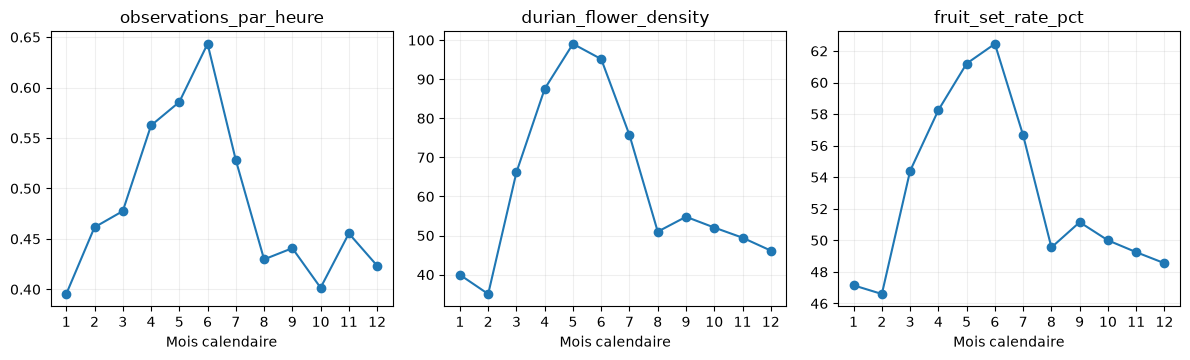

In [42]:
vergers_saison_ecology = vergers_contextuels_ecology.copy()
vergers_saison_ecology['mois_calendaire'] = vergers_saison_ecology['survey_period'].dt.month
variables_phenologie_ecology = ['observations_par_heure', 'fruit_set_rate_pct', 'rendement_kg_ha', 'durian_flower_density', 'other_pollinator_activity', 'pesticide_index']
medians_calendaires_vergers_ecology = vergers_saison_ecology.groupby(['site_code', 'mois_calendaire'])[variables_phenologie_ecology].transform('median')
ecarts_calendaires_vergers_ecology = vergers_saison_ecology[variables_phenologie_ecology] - medians_calendaires_vergers_ecology
comparaison_saison_vergers_ecology = pd.DataFrame({
    'correlation_brute_spearman': vergers_saison_ecology[variables_phenologie_ecology].corr(method='spearman')['observations_par_heure'],
    'correlation_ecarts_site_mois_spearman': ecarts_calendaires_vergers_ecology.corr(method='spearman')['observations_par_heure']
})
display(comparaison_saison_vergers_ecology.drop(index='observations_par_heure').round(3))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for axe, variable in zip(axes, ['observations_par_heure', 'durian_flower_density', 'fruit_set_rate_pct']):
    vergers_saison_ecology.groupby('mois_calendaire')[variable].median().plot(ax=axe, marker='o')
    axe.set(title=variable, xlabel='Mois calendaire')
    axe.set_xticks(range(1,13))
    axe.grid(alpha=.2)
plt.tight_layout()
plt.show()

L'activité et la floraison culminent globalement au printemps–début d'été. La corrélation activité–nouaison diminue de 0,477 à 0,189 sur les écarts au même site et au même mois ; celle avec le rendement passe de 0,448 à 0,143. La saison explique donc une partie importante de l'association. Le lien résiduel reste descriptif : ce tableau ne chiffre pas l'effet propre des chauves-souris sur la récolte.

## Cours 6 — Documents de terrain et limites de l'analyse lexicale

**Question.** Les rapports apportent-ils des éléments distinctifs, ou répètent-ils
principalement des modèles rédactionnels ? Nous calculons TF-IDF sur les mots
et les bigrammes, puis la similarité cosinus. Les termes rares sont conservés
avec `min_df=1`, car ils peuvent être importants dans ce petit corpus.

Le texte original reste disponible. Une similarité lexicale ne signifie pas une
confirmation factuelle. Le retrait de mots fréquents peut faire perdre des
négations : les passages retenus sont donc relus intégralement, dans leur contexte.

In [43]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vectoriseur_rapports_ecology = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=1, max_df=.95)
matrice_tfidf_ecology = vectoriseur_rapports_ecology.fit_transform(df_rapports['text'])
termes_rapports_ecology = vectoriseur_rapports_ecology.get_feature_names_out()
similarites_rapports_ecology = cosine_similarity(matrice_tfidf_ecology)
similarites_voisins_ecology = similarites_rapports_ecology.copy()
np.fill_diagonal(similarites_voisins_ecology, -np.inf)
positions_voisins_ecology = similarites_voisins_ecology.argmax(axis=1)
resume_textes_ecology = df_rapports[['document_id', 'document_type']].copy()
resume_textes_ecology['document_voisin'] = df_rapports['document_id'].to_numpy()[positions_voisins_ecology]
resume_textes_ecology['similarite_maximale'] = similarites_voisins_ecology.max(axis=1)
resume_textes_ecology['meme_type'] = df_rapports['document_type'].to_numpy() == df_rapports['document_type'].to_numpy()[positions_voisins_ecology]
print('Documents / termes :', matrice_tfidf_ecology.shape)
display(resume_textes_ecology.sort_values('similarite_maximale').head(8).round(3))
print('Plus proche voisin de même type :', resume_textes_ecology['meme_type'].sum(), 'sur', len(df_rapports))
position_incident_ecology = df_rapports.index.get_loc(df_rapports.index[df_rapports['document_id'].eq('EFR-510088')][0])
scores_incident_ecology = matrice_tfidf_ecology[position_incident_ecology].toarray().ravel()
display(pd.DataFrame({'terme': termes_rapports_ecology, 'tfidf': scores_incident_ecology}).nlargest(15, 'tfidf').round(3))

Documents / termes : (30, 768)


,document_id,document_type,document_voisin,similarite_maximale,meme_type
0,EFR-510088,ecological_incident_report,EFR-510095,0.087,True
1,EFR-510082,field_observation,EFR-510054,0.495,False
7,EFR-510026,monitoring_report,EFR-510042,0.562,True
3,EFR-510007,field_observation,EFR-510031,0.574,True
8,EFR-510037,monitoring_report,EFR-510019,0.596,True
9,EFR-510054,monitoring_report,EFR-510042,0.605,True
25,EFR-510077,ecological_incident_report,EFR-510130,0.606,True
5,EFR-510020,field_observation,EFR-510031,0.613,True


Plus proche voisin de même type : 29 sur 30


,terme,tfidf
175,conducted,0.129
205,cut,0.129
424,material,0.129
520,post,0.129
521,post access,0.129
545,record,0.129
321,handling,0.115
34,access,0.101
347,inspection,0.091
267,entrance,0.081


La matrice comporte 30 documents et 768 termes ou bigrammes. Pour 29 documents,
le plus proche voisin est du même type documentaire, ce qui correspond à des
modèles rédactionnels récurrents. EFR-510088 est beaucoup moins proche du reste
du corpus : sa similarité maximale est d'environ 0,087. Son vocabulaire distinctif
motive une lecture attentive, mais la rareté lexicale ne prouve pas sa véracité.

### LSA : structure documentaire et lecture des termes en contexte

Pour comparer à la représentation TF-IDF complète, nous testons cinq composantes
LSA par SVD. Ce nombre est un choix exploratoire, pas la preuve de cinq thèmes.
Les composantes sont signées : les mots de poids positif et négatif sont présentés.
Une projection qui explique peu de variance ne peut pas remplacer les similarités
calculées dans l'espace complet. Nous vérifions aussi les contextes littéraux
des expressions liées à la collecte : les bigrammes créés après retrait des
stopwords ne sont pas toujours adjacents dans le texte original.

In [44]:
from sklearn.decomposition import TruncatedSVD

lsa_rapports_ecology = TruncatedSVD(n_components=5, random_state=42)
projection_lsa_ecology = lsa_rapports_ecology.fit_transform(matrice_tfidf_ecology)
print('Variance expliquée par composante :', lsa_rapports_ecology.explained_variance_ratio_.round(3))
print('Variance expliquée cumulée :', round(lsa_rapports_ecology.explained_variance_ratio_.sum(), 3))
termes_lsa_ecology = []
for numero, poids in enumerate(lsa_rapports_ecology.components_, start=1):
    termes_lsa_ecology.append({'composante': numero, 'termes_positifs': ', '.join(termes_rapports_ecology[np.argsort(poids)[-7:][::-1]]), 'termes_negatifs': ', '.join(termes_rapports_ecology[np.argsort(poids)[:7]])})
display(pd.DataFrame(termes_lsa_ecology))
contextes_collecte_ecology = []
for document in df_rapports.itertuples(index=False):
    for paragraphe in document.text.replace('\r\n', '\n').split('\n\n'):
        if re.search(r'licensed bat collection|all animals were returned|does not assign|does not convert|removal or handling', paragraphe, flags=re.I):
            contextes_collecte_ecology.append({'document_id': document.document_id, 'passage_original': paragraphe.strip()})
display(pd.DataFrame(contextes_collecte_ecology).drop_duplicates().head(12))

Variance expliquée par composante : [0.032 0.195 0.151 0.111 0.099]
Variance expliquée cumulée : 0.588


,composante,termes_positifs,termes_negatifs
0,1,"access, seasonal, habitat disturbance, movemen...","monitoring maintenance, monitoring team, moder..."
1,2,"lower detection, invalidate, interval device, ...","access, habitat disturbance, maintenance, asse..."
2,3,"equipment observed, entrance secure, disturban...","rainfall, neighboring, repeat, comparison neig..."
3,4,"completed, team, interval vegetation, limitati...","temporary, incident, evidence, rainfall, short..."
4,5,"temporary, evidence, incident, path inspection...","orchard, neighboring, microclimate review, mic..."


,document_id,passage_original
0,EFR-510088,UNCERTAINTY\nThe observations are consistent w...
1,EFR-510082,The report does not convert an unusual count i...
2,EFR-510082,AUTHORIZED ACTIVITY\nA licensed bat collection...
3,EFR-510035,The report does not convert an unusual count i...
4,EFR-510007,The report does not convert an unusual count i...
5,EFR-510031,The report does not convert an unusual count i...
6,EFR-510020,The report does not convert an unusual count i...
7,EFR-510048,The report does not convert an unusual count i...
8,EFR-510026,The report does not convert an unusual count i...
10,EFR-510026,PERMIT CONTEXT\nA separate licensed bat collec...


Les cinq composantes conservent 58,8 % de la variance. Elles décrivent une structure lexicale partielle, largement influencée par les formulations récurrentes des rapports. Les termes positifs et négatifs ne sont pas des diagnostics. La lecture des passages originaux reste nécessaire pour distinguer une collecte autorisée avec remise en liberté, une hypothèse de manipulation et une négation explicite.

### Lecture du rapport ciblé et de deux contre-exemples

Nous lisons le rapport qui motive l'étude de KNT-KES, un rapport mentionnant
une collecte autorisée avec remise en liberté et un incident attribué à des
perturbations ordinaires. Cette comparaison évite de sélectionner seulement
les passages compatibles avec l'hypothèse d'un prélèvement clandestin.

In [45]:
from IPython.display import Markdown

for identifiant in ['EFR-510088', 'EFR-510082', 'EFR-510077']:
    document = df_rapports.loc[df_rapports['document_id'].eq(identifiant)].iloc[0]
    display(Markdown('#### ' + identifiant + ' — ' + document['title']))
    display(document[['site_code', 'document_date', 'author_name', 'author_organization', 'related_survey_id', 'related_device_reference', 'publication_status']].to_frame('valeur'))
    display(Markdown(document['text']))

controle_incident_ecology = liens_rapports_ecology.loc[liens_rapports_ecology['document_id'].eq('EFR-510088')]
display(controle_incident_ecology[['document_id', 'document_date', 'survey_start', 'document_avant_releve', 'mois_concordant']])
mesure_incident_ecology = ecologie_mensuelle.loc[ecologie_mensuelle['survey_id'].eq('BAT-0000064')]
display(mesure_incident_ecology[['survey_id', 'site_code', 'mois_releve', 'observed_bat_count', 'acoustic_detection_count', 'uptime_pct', 'acoustic_quality', 'fault_code']])

#### EFR-510088 — Post-Access Ecological Incident at KNT-KES

,valeur
site_code,KNT-KES
document_date,2024-04-02 00:00:00
author_name,Anika Dren
author_organization,Horizon Field Research Cooperative
related_survey_id,BAT-0000064
related_device_reference,DEV-KNTKES-2
publication_status,restricted


INCIDENT
A post-access inspection was conducted at KNT-KES after the March access window. The acoustic station remained operational, but the subsequent survey recorded a marked reduction in *Eonycteris spelaea* activity compared with other environmentally similar months.

EVIDENCE
Device uptime was above ninety percent and the acoustic-quality record did not show a sustained fault. Weather interference was moderate and does not account for the full change. Visual inspection identified fresh handling marks near the secondary entrance, two short lengths of cut restraint material, and disturbed sediment along a route not used by the monitoring team. No dead animals were found. The access register confirms authorized equipment entry, although the declared purpose was routine monitoring maintenance.

IMMEDIATE ACTION
The entrance was photographed, the cut material was retained, and the station configuration was checked against the prior record. A repeat survey and a comparison with adjacent sites were requested. The access authority was asked to preserve the associated case file.

UNCERTAINTY
The observations are consistent with recent removal or handling activity, but they do not identify who conducted it or why. Seasonal movement, unrecorded disturbance, and temporary roost relocation remain alternatives. The report therefore records an unexplained post-access bat deficit with functioning devices and physical traces; it does not assign a covert operation or final use.

#### EFR-510082 — Field Observation 27

,valeur
site_code,KNT-JAK
document_date,2019-04-01 00:00:00
author_name,Vera Waren
author_organization,Pollinator Justice Network
related_survey_id,BAT-0001000
related_device_reference,DEV-KNTJAK-3
publication_status,restricted


SITE AND TIME
Field observation at KNT-JAK during sensor maintenance cycle.

METHOD
The team completed a standard dusk transect and reviewed survey BAT-0001000. Effort and weather were recorded.

OBSERVATIONS
Bat activity and comparison-species counts varied across the interval. Vegetation and access conditions showed no acute change.

LIMITATIONS
Wind and intermittent background noise reduced certainty in part of the survey.

The reporting interval concerns sensor maintenance cycle and includes recorded effort, weather, and device-quality limitations.

Bat activity was interpreted alongside habitat condition, flowering, fruit set, disturbance, and comparison-species observations.

The programme retained raw survey and device references so that low counts can be separated from poor monitoring coverage.

Observed changes may reflect movement, weather, access, pesticide exposure, habitat disturbance, or ordinary seasonal variation.

The report does not convert an unusual count into a claim about organized removal.

A repeat interval and comparison with neighboring sites were recommended.

The reporting interval concerns sensor maintenance cycle and includes recorded effort, weather, and device-quality limitations.

AUTHORIZED ACTIVITY
A licensed bat collection for tagging and release was completed by the conservation team; all animals were returned at the capture point.

#### EFR-510077 — Ecological Incident Report 51

,valeur
site_code,KNT-TEX
document_date,2019-04-07 00:00:00
author_name,Doran Norel
author_organization,Horizon Field Research Cooperative
related_survey_id,BAT-0001888
related_device_reference,DEV-KNTTEX-3
publication_status,internal


INCIDENT
An ordinary ecological incident was recorded at KNT-TEX during sensor maintenance cycle.

EVIDENCE
Survey BAT-0001888 showed a short-term reduction in activity. Heavy rainfall, access noise, and temporary device shielding were documented.

RESPONSE
The device was inspected and a repeat survey scheduled.

UNCERTAINTY
The available evidence favors temporary disturbance but does not exclude seasonal movement.

The reporting interval concerns sensor maintenance cycle and includes recorded effort, weather, and device-quality limitations.

Bat activity was interpreted alongside habitat condition, flowering, fruit set, disturbance, and comparison-species observations.

The programme retained raw survey and device references so that low counts can be separated from poor monitoring coverage.

Observed changes may reflect movement, weather, access, pesticide exposure, habitat disturbance, or ordinary seasonal variation.

The report does not convert an unusual count into a claim about organized removal.

A repeat interval and comparison with neighboring sites were recommended.

The reporting interval concerns sensor maintenance cycle and includes recorded effort, weather, and device-quality limitations.

Bat activity was interpreted alongside habitat condition, flowering, fruit set, disturbance, and comparison-species observations.

The programme retained raw survey and device references so that low counts can be separated from poor monitoring coverage.

,document_id,document_date,survey_start,document_avant_releve,mois_concordant
0,EFR-510088,2024-04-02,2024-04-05 18:00:00,True,True


,survey_id,site_code,mois_releve,observed_bat_count,acoustic_detection_count,uptime_pct,acoustic_quality,fault_code
63,BAT-0000064,KNT-KES,2024-04,10,15,83.1,73.1,NaN


### Ce que les sources confirment et ce qu'elles ne confirment pas

Le rapport `EFR-510088` décrit des traces de manipulation et l'absence de cadavres.
Ce sont des affirmations documentaires, pas des observations que nous pouvons
vérifier indépendamment dans les tables. Le texte conserve lui-même les hypothèses
de déplacement saisonnier, de perturbation non enregistrée et de changement de gîte.

Deux discordances nécessitent de la prudence :

- le document du 2 avril 2024 cite un relevé commençant le 5 avril 2024 ;
- il affirme une disponibilité supérieure à 90 %, alors que la ligne mensuelle
  de l'appareil lié à avril indique 83,1 %. La disponibilité mensuelle n'est pas
  nécessairement celle des seules heures observées, mais elle ne confirme pas
  directement le chiffre du rapport.

Nous ne corrigeons ni les dates ni les mesures pour les faire correspondre au récit.
L'absence de code de panne n'exclut pas un problème technique. Les documents
`EFR-510082` et `EFR-510077` montrent aussi que collecte, activité basse et accès
ne suffisent pas à identifier une opération clandestine.

## Rapprochements vérifiables avec Public Records et Logistics

Les informations rapportées par les autres membres du groupe sont des pistes,
pas des faits ajoutés aux données Ecology. Nous vérifions ici les références
disponibles sans modifier leurs notebooks. Un nom semblable ou une date proche
ne suffit pas pour identifier un lot biologique.

In [46]:
acces_ecology = pd.read_csv('data/public_records/site_access_case_events.csv').drop_duplicates()
acces_ecology['event_time'] = pd.to_datetime(acces_ecology['event_time'], format='mixed', errors='raise')
acces_cible_ecology = acces_ecology.loc[acces_ecology['site_code'].eq(site_cible_ecology)].sort_values('event_time')
acces_2024_ecology = acces_cible_ecology.loc[acces_cible_ecology['event_time'].between('2024-01-01', '2024-12-31')]
display(acces_2024_ecology[['access_event_id', 'access_case_number', 'event_time', 'activity', 'requesting_registration_number', 'requesting_organization_name', 'confidentiality_class']])

partenaires_ecology = pd.read_csv('data/logistics/erp_business_partners.csv').drop_duplicates()
assert partenaires_ecology['partner_code'].is_unique
organisations_acces_ecology = acces_2024_ecology[['requesting_registration_number', 'requesting_organization_name']].drop_duplicates()
partenaires_lies_ecology = organisations_acces_ecology.merge(partenaires_ecology, left_on='requesting_registration_number', right_on='external_registration_number', how='left', validate='one_to_many')
display(partenaires_lies_ecology[['requesting_registration_number', 'requesting_organization_name', 'partner_code', 'partner_name']])
expeditions_ecology = pd.read_csv('data/logistics/shipments.csv').drop_duplicates()
codes_partenaires_ecology = partenaires_lies_ecology['partner_code'].dropna()
expeditions_liees_ecology = expeditions_ecology.loc[expeditions_ecology['sender_partner_code'].isin(codes_partenaires_ecology) | expeditions_ecology['receiver_partner_code'].isin(codes_partenaires_ecology)].copy()
expeditions_liees_ecology['dispatch_time'] = pd.to_datetime(expeditions_liees_ecology['dispatch_time'], format='mixed', errors='raise')
print("Expéditions distinctes liées au partenaire identifié, toutes dates :", expeditions_liees_ecology['shipment_number'].nunique())
display(expeditions_liees_ecology.groupby(['item_category', 'declared_purpose']).size().rename('nombre_lignes').to_frame())
reglementaire_ecology = pd.read_csv('data/public_records/regulatory_case_events.csv').drop_duplicates()
cas_lies_ecology = reglementaire_ecology.loc[reglementaire_ecology['related_site_code'].eq(site_cible_ecology)]
references_expeditions_ecology = cas_lies_ecology[['case_number', 'related_site_code', 'related_shipment_number']].drop_duplicates()
expeditions_referencees_ecology = references_expeditions_ecology.merge(expeditions_ecology, left_on='related_shipment_number', right_on='shipment_number', how='left', validate='one_to_many', indicator=True)
noms_partenaires_ecology = partenaires_ecology.set_index('partner_code')['partner_name']
for role in ['sender', 'receiver', 'carrier']:
    expeditions_referencees_ecology[role + '_name'] = expeditions_referencees_ecology[role + '_partner_code'].map(noms_partenaires_ecology)
display(expeditions_referencees_ecology[['case_number', 'related_site_code', 'shipment_number', 'dispatch_time', 'sender_name', 'receiver_name', 'carrier_name', 'declared_quantity', 'declared_unit', 'temperature_control_class', '_merge']])
facilites_logistiques_ecology = pd.read_csv('data/logistics/erp_facilities.csv').drop_duplicates()
codes_facilites_ecology = set(expeditions_referencees_ecology['origin_facility_code'].dropna()) | set(expeditions_referencees_ecology['destination_facility_code'].dropna())
display(facilites_logistiques_ecology.loc[facilites_logistiques_ecology['facility_code'].isin(codes_facilites_ecology), ['facility_code', 'facility_name', 'operating_partner_code']])
debut_cas_ecology = cas_lies_ecology.assign(date_evenement=dates_heures_ecology(cas_lies_ecology['event_time'])).groupby('case_number')['date_evenement'].min()
controle_chronologie_expeditions_ecology = expeditions_referencees_ecology[['case_number', 'shipment_number', 'dispatch_time']].copy()
controle_chronologie_expeditions_ecology['debut_cas'] = controle_chronologie_expeditions_ecology['case_number'].map(debut_cas_ecology)
controle_chronologie_expeditions_ecology['date_depart'] = dates_heures_ecology(controle_chronologie_expeditions_ecology['dispatch_time'])
controle_chronologie_expeditions_ecology['depart_apres_ouverture_cas'] = controle_chronologie_expeditions_ecology['date_depart'].gt(controle_chronologie_expeditions_ecology['debut_cas'])
display(controle_chronologie_expeditions_ecology)
documents_publics_ecology = pd.read_csv('data/public_records/public_and_investigative_documents.csv')
mentions_ecology = documents_publics_ecology['text'].str.contains(r'KNT-KES|CHAMELEO|Unwabu', case=False, regex=True, na=False)
display(documents_publics_ecology.loc[mentions_ecology, ['document_id', 'document_date', 'title', 'source_reference']])
for identifiant in ['PUB-510079', 'PUB-510127']:
    document = documents_publics_ecology.loc[documents_publics_ecology['document_id'].eq(identifiant)].iloc[0]
    display(Markdown('### ' + identifiant + ' — ' + document['title']))
    display(Markdown(document['text']))

,access_event_id,access_case_number,event_time,activity,requesting_registration_number,requesting_organization_name,confidentiality_class
104,ACE-000105,ACC-2024-0014,2024-02-19 09:00:00,request_submitted,REG-AVL-01013,Horizon Field Research Cooperative,restricted
105,ACE-000106,ACC-2024-0014,2024-02-25 09:00:00,technical_review,REG-AVL-01013,Horizon Field Research Cooperative,restricted
106,ACE-000107,ACC-2024-0014,2024-03-01 09:00:00,wildlife_review,REG-AVL-01013,Horizon Field Research Cooperative,restricted
107,ACE-000108,ACC-2024-0014,2024-03-11 09:00:00,authorization_granted,REG-AVL-01013,Horizon Field Research Cooperative,restricted
108,ACE-000109,ACC-2024-0014,2024-03-21 18:00:00,access_started,REG-AVL-01013,Horizon Field Research Cooperative,restricted
109,ACE-000110,ACC-2024-0014,2024-03-22 03:00:00,access_completed,REG-AVL-01013,Horizon Field Research Cooperative,restricted
110,ACE-000111,ACC-2024-0014,2024-03-24 11:00:00,closure_recorded,REG-AVL-01013,Horizon Field Research Cooperative,restricted


,requesting_registration_number,requesting_organization_name,partner_code,partner_name
0,REG-AVL-01013,Horizon Field Research Cooperative,BP-30056,Horizon Field Research Cooperative


Expéditions distinctes liées au partenaire identifié, toutes dates : 55


nombre_lignes
item_category          declared_purpose                                             
agricultural_equipment agricultural distribution                                   1
agricultural_product   agricultural distribution                                   1
                       customer distribution                                       1
                       facility replenishment                                      1
                       laboratory delivery                                         3
                       scheduled stock transfer                                    1
biological_sample      environmental and wildlife reference materials             18
                       facility replenishment                                      1
                       field programme support                                     2
                       laboratory delivery                                         1
cold_storage_equipment agricultural distribution                                   1
                       field programme support                                     1
communication_service  facility replenishment                                      1
consulting_service     customer distribution                                       1
                       facility replenishment                                      1
laboratory_material    agricultural distribution                                   1
                       facility replenishment                                      1
                       laboratory delivery                                         2
medical_consumables    agricultural distribution                                   1
                       scheduled stock transfer                                    1
medical_equipment      agricultural distribution                                   1
                       facility replenishment                                      1
monitoring_equipment   agricultural distribution                                   1
                       customer distribution                                       1
                       laboratory delivery                                         1
office_supply          laboratory delivery                                         1
other                  laboratory delivery                                         1
                       scheduled stock transfer                                    1
protective_equipment   facility replenishment                                      1
refrigeration_service  customer distribution                                       1
                       laboratory delivery                                         1
research_contract      agricultural distribution                                   1
transport_service      agricultural distribution                                   1
                       scheduled stock transfer                                    1

,case_number,related_site_code,shipment_number,dispatch_time,sender_name,receiver_name,carrier_name,declared_quantity,declared_unit,temperature_control_class,_merge
0,REG-2019-0002,KNT-KES,SHP-2018-00007,2018-03-23T09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Northstar Cold Chain Services,5,sealed_lot,2-8C,both
1,REG-2023-0008,KNT-KES,SHP-2024-00007,2024-03-22T09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Northstar Cold Chain Services,6,sealed_lot,2-8C,both


,facility_code,facility_name,operating_partner_code
1,FCL-1024,Meridian Kintara Biological Aggregation Facility,BP-30078
7,FCL-1030,Kintara Cave Authority Field Depot,BP-30016


... (2 outputs left out)

### PUB-510079 — Message Concerning Collected Eonycteris

I worked on restricted receiving and reconciliation records. I am sending this because the standard files make the programme look like conservation support, but the handling instructions say something different.

The consignments include live or recently collected *Eonycteris spelaea*. They arrive under wildlife-monitoring or biological-sample descriptions, are consolidated in sealed units, and then disappear from the ordinary inventory sequence. I saw preparation sheets that used the word consumption and matched them to access cases, cold-storage receipts, and adjustment numbers. The animals were not being transferred only for tagging, veterinary examination, or habitat research.

Useful references include the spring Kestrel access file, the secure delivery series, and the biological-unit adjustments reviewed by the warehouse controller. Some copies use CHAMELEO routing, but I cannot explain who controls the entire programme. I did not see a complete destination record, and I cannot confirm the scale beyond the facilities where I worked.

Please verify the references independently. My account supports a consumption purpose for at least part of the collected bats. It does not establish the external route, the full network, or the historical origin of the programme.

### PUB-510127 — Private Historical Note 113

PRIVATE NOTE
I returned from the meeting concerning meeting archive. The same advisers appeared, though their titles have changed. I cannot tell whether the similarity is habit, instruction, or coincidence. I have kept the address card with the travel papers.

PROVENANCE
Undated fragment, assigned to the approximate period from adjacent documents.

The archival item relates to meeting archive and is presented with provenance and transcription limits.

Names, dates, addresses, roles, and repeated phrases are recorded without converting resemblance into identity proof.

CATALOG COMMENT
Unwabu is written on the margin, apparently the name of a coastal vessel or a folklore reference; the context is unrelated to modern programme governance.

Le numéro REG-AVL-01013 relie l'organisation d'accès Horizon Field Research
Cooperative au partenaire BP-30056. Les dossiers réglementaires de KNT-KES
référencent explicitement SHP-2018-00007 et SHP-2024-00007. Le second est déclaré
au départ le 22 mars 2024 à 09 h, après la fin d'accès enregistrée à 03 h.
Il relie le dépôt de l'autorité des grottes à l'installation d'agrégation biologique
de Meridian BioLogistics. Meridian est le destinataire, tandis que le transporteur
est Northstar Cold Chain Services. La déclaration porte sur six lots scellés,
pas sur six animaux identifiés.

Cette proximité et ces références sont concrètes, mais le dossier REG-2023-0008
cite une expédition de 2024 dans des événements datés de 2023. Cette discordance
est conservée : la référence administrative n'est pas une chaîne de traçabilité
matérielle complète. Les 55 expéditions associées au partenaire ne constituent
pas toutes des transports d'animaux et ne doivent pas être confondues avec les
sous-ensembles annoncés par Logistics.

PUB-510079 contient un témoignage explicite sur des Eonycteris collectées et
un usage de consommation, avec une mention du routage CHAMELEO. Le témoin dit
ne pas connaître l'ensemble du réseau ni son origine. Il s'agit d'une affirmation
documentaire à rapprocher des reçus et ajustements analysés par Logistics,
pas d'un usage final démontré par les seuls comptages Ecology.

À l'inverse, PUB-510127 emploie Unwabu dans un commentaire relatif à un navire
ou au folklore, déclaré sans rapport avec la gouvernance moderne du programme.
Cette occurrence est un contre-exemple à une recherche de mots-clés trop large.
Elle ne permet ni de confirmer ni de réfuter d'autres occurrences dans d'autres sources.

### Complément de gouvernance : une occurrence pertinente et ses homonymes

La première recherche dans les seuls documents publics ne suffisait pas.
MEM-510101, dans les mémos institutionnels, relie explicitement Unwabu à
l'autorité des exceptions CHAMELEO et au bureau exécutif de Meridian.
Nous conservons à la fois ce document, l'instruction de traitement MEM-510100
et le contre-exemple du tableau de bord historique MEM-510089.
Les significations ne doivent pas être fusionnées sur le seul mot CHAMELEO.

In [47]:
memos_pont_ecology = pd.read_csv('data/public_records/institutional_memos.csv').drop_duplicates()
for identifiant in ['MEM-510100', 'MEM-510101', 'MEM-510089']:
    document = memos_pont_ecology.loc[memos_pont_ecology['document_id'].eq(identifiant)].iloc[0]
    display(Markdown('#### ' + identifiant + ' — ' + document['subject_line']))
    display(document[['document_date', 'author_organization', 'related_shipment_number', 'visibility_level']].to_frame('valeur'))
    display(Markdown(document['text']))

#### MEM-510100 — Secure Delivery Record-Handling Instruction

,valeur
document_date,2023-08-17
author_organization,Meridian BioLogistics
related_shipment_number,SHP-2022-00011
visibility_level,restricted


SCOPE
This instruction applies to staff handling secure delivery records associated with shipment SHP-2022-00011 and related restricted consignments.

CONTROL REQUIREMENTS
Records marked CHAMELEO are to be routed through the designated compliance queue. Staff must verify the receiving facility code, named authorization class, seal number, and temperature-control record before release. Copies are not to be attached to ordinary customer correspondence. Route changes require approval from the security manager and the duty compliance officer.

RESPONSIBILITIES
Operations staff retain the ordinary shipment record. Security staff retain the sealed routing appendix. Warehouse staff record only the declared cargo category and quantity in the standard inventory system. Any mismatch between the standard record and the restricted appendix must be escalated rather than corrected locally.

ESCALATION
Contact the secure-delivery desk for missing signatures, unexplained destination changes, or requests to bypass the receiving scan. The code identifies a handling and governance procedure. This instruction does not explain the programme's wider purpose, the ownership of the designation, or the final use of any cargo.

#### MEM-510101 — Restricted CHAMELEO Governance Review

,valeur
document_date,2025-03-14
author_organization,Meridian BioLogistics
related_shipment_number,SHP-2023-00035
visibility_level,restricted


MEETING RECORD — RESTRICTED GOVERNANCE REVIEW

Attendees included the executive chair, the secure-delivery manager, clinical programme counsel, and the records secretary.

AGENDA
1. Authority for CHAMELEO routing.
2. Relationship between programme designation and executive approvals.
3. Separation of ordinary corporate records from restricted appendices.

DISCUSSION
The chair confirmed that Unwabu is the designation used in the restricted governance schedule for the authority approving CHAMELEO exceptions. The same schedule assigns final escalation to the Meridian executive office. Participants agreed that ordinary employees should see only shipment, inventory, and compliance fields needed for their roles. The secretary noted that earlier instructions treated CHAMELEO as a handling code, while the governance schedule links it to a named authority.

DECISIONS
The secure-delivery manager will maintain the restricted appendix. Compliance will retain a cross-reference between the designation, executive approvals, and affected routes. No change will be made to public corporate filings.

LIMITS
This record establishes an Unwabu–CHAMELEO–Meridian authority bridge. The meeting did not review other networks, biological questions, ecological material, or destination records.

The chair instructed staff not to alter existing operational records retrospectively. Any reconciliation should be recorded as a new governance note with a visible date and responsible role. The meeting did not review ecological evidence or clinical files, and participants were reminded that their authority was limited to routing and programme governance.

#### MEM-510089 — Records Security Instruction 75

,valeur
document_date,2019-04-13
author_organization,Nivren Maritime Logistics
related_shipment_number,NaN
visibility_level,internal


SCOPE
Security instruction for inventory close and associated restricted records.

CONTROLS
Verify role authorization, use the approved repository, and do not copy restricted appendices into ordinary email.

RESPONSIBILITIES
The process owner maintains access logs; compliance reviews exceptions.

ESCALATION
Report missing signatures or route changes to the duty manager.

The operational issue concerns inventory close and was reviewed through the ordinary procurement, shipment, and inventory records.

Quantities, units, authorizations, facility codes, and dates were compared before any adjustment was proposed.

The memo records a practical decision and named owner without inferring an undisclosed purpose.

Ordinary causes include posting delay, split batches, transfer timing, supplier substitution, and documentation lag.

LEGACY SYSTEM
CHAMELEO was also the name of a discontinued color-coded compliance dashboard; references to that interface should be archived separately from current secure-delivery records.

MEM-510101 apporte un lien documentaire positif Unwabu–CHAMELEO–bureau exécutif de Meridian. MEM-510100 décrit un traitement séparé des dossiers et des annexes scellées, mais ne dit pas à lui seul ce qui est transporté ni utilisé. MEM-510089 donne un autre sens historique au mot CHAMELEO. Ces trois usages sont conservés séparément ; l'autorité Unwabu n'est pas identifiée automatiquement à une personne physique.

## Synthèse Ecology

Les six fichiers sont étudiés en conservant les données originales. Les doublons
exacts, formats numériques et dates sont contrôlés avant les jointures. Les 64
sites ont chacun 78 relevés mensuels ; les séries de vergers concernent seulement
16 sites. Cette couverture complète n'annule pas les variations d'effort, de
qualité et de saison, les valeurs manquantes ni les huit taux de nouaison à vérifier.

Les analyses générales permettent de ne pas sélectionner uniquement les indices
allant dans le sens du récit. TMB-BRC est surtout atypique par son activité élevée.
Les regroupements ne déterminent pas de catégorie suspecte. Les relations avec
les vergers s'atténuent après prise en compte du site et du calendrier. D'autres
sites que KNT-KES présentent des baisses persistantes. Ces résultats négatifs ou
non spécifiques sont conservés, parce qu'ils bornent les conclusions possibles.

KNT-KES reste une piste documentaire et chronologique : faibles indices en
avril–mai 2024, persistance de mai avec le filtre de disponibilité, comparaison
aux mois analogues, rapport évoquant des traces de manipulation et accès Horizon.
Le rapport est toutefois antérieur au relevé auquel il fait référence et sa
description de l'appareil diffère de la disponibilité mensuelle enregistrée.
Le recul commence aussi en mars, avant l'accès du 21 mars. Un prélèvement est
une hypothèse à examiner, pas une cause établie par les comptages.

Les références explicites et le numéro d'organisation relient l'accès à un
circuit passant par Meridian. PUB-510079 apporte un témoignage de consommation
et MEM-510101 un lien de gouvernance Unwabu–CHAMELEO–Meridian. Ces affirmations
documentaires ne remplacent pas la traçabilité d'un lot. La discordance du dossier
réglementaire daté de 2023 citant une expédition de 2024 reste signalée. Les liens avec les établissements et les patients nécessitent une analyse
transversale distincte ; ils ne sont pas établis par les seules données Ecology.

### Choix méthodologiques et correspondance avec les cours

Nous avons utilisé les distributions, contrôles et corrélations (cours 1), les
distances, PCA, K-means et regroupement hiérarchique (cours 2), l'IQR, le z-score,
les cooccurrences, Isolation Forest et LOF (cours 3), les graphes et les véritables
traces d'accès (cours 4), l'autocorrélation, la décomposition classique et les
comparaisons saisonnières (cours 5), puis TF-IDF, bigrammes, cosinus et LSA (cours 6).
Les supports locaux des six cours sont les références de ces méthodes ; Isolation
Forest et LOF sont expliqués aux pages 15 et 17 du cours 3, la dépendance des traces
page 23 du cours 4 et LSA page 12 du cours 6. Les choix de seuils et les comparaisons
de sensibilité sont explicités : ce ne sont pas des tests confirmatoires.

Nous n'ajoutons pas de t-SNE redondant, de prévision temporelle sans objectif de
prévision ni de LDA imposée à trente rapports largement rédigés sur des modèles
communs. L'objectif reste d'expliquer les résultats et leurs limites, pas de
multiplier les algorithmes.